# Part 1. Data Cleaning and Preparation

**Goal:** load the full dataset, audit its structure and quality, apply only objective (model-independent) corrections, and validate the result.

**Full dataset.** The full US Accidents dataset (7,728,394 raw records) is used throughout this notebook. The 500,000-row fallback sample is not used, so no sample-representativeness comparison is needed. After confirmed duplicate removal and dropping the two constant columns, the analysis dataset has 7,610,699 rows × 44 columns (Section 1.5).

**Data states.** The notebook keeps three states of the data apart:

| State | What it contains | Where |
|---|---|---|
| A. Raw data | The original imported observations, before any change | Loaded in Section 1.1; audited in Sections 1.2 and 1.3 |
| B. Analysis dataset after objective cleaning | Confirmed duplicates removed, timestamp representation normalized, constant columns removed, confirmed categorical representation problems corrected, definitionally invalid values converted to missing | Produced in Section 1.4 and validated in Section 1.5; used throughout Part 2 |
| C. Model-ready representation | Missing-value treatment, encoding, feature exclusions and transformations, fit within a training/validation workflow | Not produced yet: it requires the decisions of Part 3 |

Dataset B is suitable for EDA, but it is not model-ready. It may still contain missing values, retained extreme observations, high-cardinality variables, leakage candidates and variables that need a model-dependent encoding or transformation. These are kept on purpose until Part 3 decides how to treat them.

## 1.1 Setup and Full-Dataset Loading

### 1.1.1 Libraries, data location and display settings

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.csv as pv
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from IPython.display import display

# The full dataset: next to the notebook (local run) or attached as a Kaggle input, usually in /kaggle/input/us-accidents;
# otherwise the only copy anywhere under /kaggle/input is used
DATA_FILE = "US_Accidents_March23.csv"
KAGGLE_INPUT = Path("/kaggle/input")
found = [p for p in (Path.cwd() / DATA_FILE, KAGGLE_INPUT / "us-accidents" / DATA_FILE) if p.is_file()][:1]
if not found and KAGGLE_INPUT.is_dir():
    found = sorted(KAGGLE_INPUT.rglob(DATA_FILE))
if len(found) != 1:
    raise FileNotFoundError(f"Expected one copy of {DATA_FILE} in {Path.cwd()} or under {KAGGLE_INPUT}, found {len(found)}"
                            + (f" ({', '.join(map(str, found))})" if found else "") + ". Locally, start Jupyter in the folder "
                            "that holds the file; on Kaggle, attach the US Accidents dataset as an input.")
RAW_CSV = found[0]
print(f"Dataset: {RAW_CSV}")

PROJECT_DIR = Path.cwd()  # figures/ and tables/ are written here (on Kaggle: /kaggle/working)
FIGURE_DIR, TABLE_DIR = PROJECT_DIR / "figures", PROJECT_DIR / "tables"
for directory in (FIGURE_DIR, TABLE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

TARGET = "Severity"
VALID_TARGET_VALUES = [1, 2, 3, 4]
ID_COL = "ID"
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# pandas settings. Bottleneck, where installed, sums 32-bit columns without extra precision, which makes their standard
# deviation over millions of rows inaccurate; pandas' own NumPy routines are used instead
pd.set_option("mode.copy_on_write", True)
pd.set_option("compute.use_bottleneck", False)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 60)

# Display settings. Liberation Sans has the same character widths as Arial and replaces it where Arial is not installed
COLORS ={"primary": "#2a78d6", "ink": "#0b0b0b", "muted": "#52514e", "grid": "#e4e3df", "other": "#b8b6b0"}
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]  # categorical slots 1-3
mpl.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "figure.dpi": 110, "savefig.dpi": 300,
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"], "font.size": 9,
    "axes.titlesize": 10.5, "axes.titleweight": "semibold", "axes.titlelocation": "left", "axes.titlepad": 8,
    "axes.labelsize": 9.5, "axes.labelcolor": COLORS["ink"], "axes.edgecolor": COLORS["muted"],
    "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
    "grid.color": COLORS["grid"], "grid.linewidth": 0.6,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5, "xtick.color": COLORS["muted"], "ytick.color": COLORS["muted"],
    "text.color": COLORS["ink"], "legend.fontsize": 8.5, "legend.frameon": False,
})
millions = mticker.FuncFormatter(lambda v, _: f"{v / 1e6:g}M" if v else "0")

Dataset: /kaggle/input/datasets/sobhanmoosavi/us-accidents/US_Accidents_March23.csv


### 1.1.2 Utility functions

In [2]:
SAVED_FIGURES, SAVED_TABLES = set(), set()

# Percentage
def pct(part, whole):
    return 100.0 * part / whole if whole else np.nan

# Save Figures
def save_figure(fig, name):
    """Save a figure as a 300 dpi, high-quality JPG for the report."""
    path = FIGURE_DIR / f"{name}.jpg"
    fig.savefig(path, format="jpg", dpi=300, bbox_inches="tight", pad_inches=0.05,
                facecolor="white", pil_kwargs={"quality": 95, "subsampling": 0})
    SAVED_FIGURES.add(path.name)

# Save Tables
def save_table(table, name):
    """Export a supporting table as CSV (without displaying it)."""
    path = TABLE_DIR / f"{name}.csv"
    table.to_csv(path, index=False)
    SAVED_TABLES.add(path.name)

# Perform Tables
def show_table(table, caption=None, precision=2, name=None, formats=None):
    """Display a compact table without the pandas index; optionally export it. `formats` sets the number format of
    selected columns, e.g. {"Speedup (×)": "{:.1f}"}."""
    styler = (table.style.hide(axis="index").format(precision=precision, thousands=",", na_rep="")
              .set_table_styles([{"selector": "caption",
                                  "props": "caption-side: top; text-align: left; font-weight: 600; padding-bottom: 6px;"}]))
    if formats:
        styler = styler.format(formats, subset=list(formats), na_rep="")
    display(styler.set_caption(caption) if caption else styler)
    if name:
        save_table(table, name)

# Format Cell
def format_cell(value, width=42):
    if pd.isna(value):
        return "NaN"
    text = str(value)
    return text if len(text) <= width else text[: width - 3] + "..."

# Memory Management
def row_hash(frame, columns):
    """64-bit row hash built one column at a time (low memory)."""
    hashes = np.zeros(len(frame), dtype=np.uint64)
    for c in columns:
        hashes *= np.uint64(0x100000001B3)
        hashes ^= pd.util.hash_pandas_object(frame[c], index=False).to_numpy()
    return hashes


def remap_categories(series, mapping, order=None):
    """Rename or merge categorical levels by remapping integer codes (no per-row string work)."""
    new_labels = pd.Index([mapping.get(level, level) for level in series.cat.categories])
    new_categories = pd.Index(order) if order is not None else pd.Index(new_labels.unique())
    lookup = new_categories.get_indexer(new_labels)
    assert (lookup >= 0).all(), "A remapped label is missing from the category order"
    codes = series.cat.codes.to_numpy()
    return pd.Series(pd.Categorical.from_codes(np.where(codes >= 0, lookup[codes], -1), categories=new_categories),
                     index=series.index, name=series.name)


CLEANING_LOG = {}


def log_cleaning(issue, columns, action, evidence, rows_affected):
    """Record one cleaning action; keyed by issue so re-running a cell never duplicates an entry."""
    CLEANING_LOG[issue] = {"Issue": issue, "Column(s)": columns, "Evidence": evidence, "Action": action,
                           "Rows affected": int(rows_affected)}

### 1.1.3 Loading strategy and column groups

The full file is loaded once with an explicit schema, using the PyArrow CSV reader:

- **Missing values.** Only empty fields become missing. Text such as `"NA"` or `"None"` stays visible for the audit.
- **Numeric and boolean columns.** They are typed strictly, so the load itself proves that every non-empty value parses.
- **Timestamps.** They are kept as text and parsed deliberately in Section 1.3.
- **Single working frame.** Keeping a second full copy is not affordable, so `df` is the only frame. The raw state stays reproducible from the unmodified CSV through `load_raw_accidents()`.

In [3]:
STRING_COLS = ["ID", "Description", "Street"]
DATETIME_COLS = ["Start_Time", "End_Time", "Weather_Timestamp"]  # loaded as text
CATEGORICAL_COLS = ["Source", "City", "County", "State", "Zipcode", "Country", "Timezone", "Airport_Code",
                    "Wind_Direction", "Weather_Condition", "Sunrise_Sunset", "Civil_Twilight",
                    "Nautical_Twilight", "Astronomical_Twilight"]
COORDINATE_COLS = ["Start_Lat", "Start_Lng", "End_Lat", "End_Lng"]
MEASUREMENT_COLS = ["Distance(mi)", "Temperature(F)", "Wind_Chill(F)", "Humidity(%)", "Pressure(in)",
                    "Visibility(mi)", "Wind_Speed(mph)", "Precipitation(in)"]
BOOLEAN_COLS = ["Amenity", "Bump", "Crossing", "Give_Way", "Junction", "No_Exit", "Railway", "Roundabout",
                "Station", "Stop", "Traffic_Calming", "Traffic_Signal", "Turning_Loop"]
ARROW_SCHEMA = {
    **{c: pa.string() for c in STRING_COLS + DATETIME_COLS},
    **{c: pa.dictionary(pa.int32(), pa.string()) for c in CATEGORICAL_COLS},
    TARGET: pa.int8(),
    **{c: pa.float64() for c in COORDINATE_COLS},  # full precision for coordinates
    **{c: pa.float32() for c in MEASUREMENT_COLS},  # few significant digits in the source
    **{c: pa.bool_() for c in BOOLEAN_COLS},
}

# Semantic column groups, reused throughout the notebook
COLUMN_GROUPS = {
    "Identifier": ["ID"],
    "Target": ["Severity"],
    "Data source": ["Source"],
    "Time": ["Start_Time", "End_Time"],
    "Accident extent": ["End_Lat", "End_Lng", "Distance(mi)"],
    "Text": ["Description"],
    "Location": ["Start_Lat", "Start_Lng", "Street", "City", "County", "State", "Zipcode", "Country", "Timezone"],
    "Weather": ["Airport_Code", "Weather_Timestamp", "Temperature(F)", "Wind_Chill(F)", "Humidity(%)",
                "Pressure(in)", "Visibility(mi)", "Wind_Direction", "Wind_Speed(mph)", "Precipitation(in)",
                "Weather_Condition"],
    "Road features": BOOLEAN_COLS,
    "Daylight": ["Sunrise_Sunset", "Civil_Twilight", "Nautical_Twilight", "Astronomical_Twilight"],
}
COLUMN_TO_GROUP = {col: group for group, cols in COLUMN_GROUPS.items() for col in cols}
GROUP_ORDER = {group: i for i, group in enumerate(COLUMN_GROUPS)}

### 1.1.4 Load the full dataset

In [4]:
def load_raw_accidents(path=RAW_CSV):
    """Load the full CSV with the explicit schema; only empty fields become missing."""
    table = pv.read_csv(path, convert_options=pv.ConvertOptions(
        column_types=ARROW_SCHEMA, null_values=[""], strings_can_be_null=True,
        true_values=["True"], false_values=["False"]))
    type_mapper = {pa.string(): pd.StringDtype("pyarrow"), pa.int8(): pd.Int8Dtype()}.get
    frame = table.to_pandas(types_mapper=type_mapper, split_blocks=True, self_destruct=True)
    for c in CATEGORICAL_COLS:  # alphabetical level order instead of first-appearance order (values unchanged)
        frame[c] = frame[c].cat.reorder_categories(sorted(frame[c].cat.categories))
    return frame


def count_data_lines(path):
    """Number of data lines in the CSV (header excluded)."""
    n_newlines, last_byte = 0, b""
    with path.open("rb") as fh:
        while chunk := fh.read(64 * 1024 * 1024):
            n_newlines += chunk.count(b"\n")
            last_byte = chunk[-1:]
    return n_newlines - 1 + (last_byte != b"\n")


with RAW_CSV.open("r", encoding="utf-8") as fh:
    header = fh.readline().strip().split(",")
assert set(header) == set(ARROW_SCHEMA) and len(header) == len(ARROW_SCHEMA), "Schema does not match the CSV header"

df = load_raw_accidents()
n_data_lines = count_data_lines(RAW_CSV)

assert list(df.columns) == header and len(df) == n_data_lines, "Loaded frame does not match the file"
assert all(df[c].dtype == bool for c in BOOLEAN_COLS), "A boolean column contains missing or non-boolean values"
RAW_SHAPE = df.shape
n_rows_raw = RAW_SHAPE[0]
raw_memory_gb = df.memory_usage(deep=True).drop("Index").sum() / 1e9

print(f"Loaded {RAW_CSV.name} ({RAW_CSV.stat().st_size / 1e9:.2f} GB): {RAW_SHAPE[0]:,} rows x {RAW_SHAPE[1]} columns, "
      f"as many rows as data lines in the file; {raw_memory_gb:.2f} GB in memory.")

Loaded US_Accidents_March23.csv (3.06 GB): 7,728,394 rows x 46 columns, as many rows as data lines in the file; 2.37 GB in memory.


## 1.2 Raw Data Inspection

These are the standard first views: one record, the column groups with their pandas types and missing values, and summary statistics. Nothing is changed here.

### 1.2.1 What does one accident record look like?

In [5]:
df.head()

,ID,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),Description,Street,City,County,State,Zipcode,Country,Timezone,Airport_Code,Weather_Timestamp,Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Direction,Wind_Speed(mph),Precipitation(in),Weather_Condition,Amenity,Bump,Crossing,Give_Way,Junction,No_Exit,Railway,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight
0,A-1,Source2,3,2016-02-08 05:46:00,2016-02-08 11:00:00,39.865147,-84.058723,NaN,NaN,0.01,Right lane blocked due to accident on I-70 Eastbound at ...,I-70 E,Dayton,Montgomery,OH,45424,US,US/Eastern,KFFO,2016-02-08 05:58:00,36.900002,NaN,91.0,29.680000,10.0,Calm,NaN,0.02,Light Rain,False,False,False,False,False,False,False,False,False,False,False,False,False,Night,Night,Night,Night
1,A-2,Source2,2,2016-02-08 06:07:59,2016-02-08 06:37:59,39.928059,-82.831184,NaN,NaN,0.01,Accident on Brice Rd at Tussing Rd. Expect delays.,Brice Rd,Reynoldsburg,Franklin,OH,43068-3402,US,US/Eastern,KCMH,2016-02-08 05:51:00,37.900002,NaN,100.0,29.650000,10.0,Calm,NaN,0.00,Light Rain,False,False,False,False,False,False,False,False,False,False,False,False,False,Night,Night,Night,Day
2,A-3,Source2,2,2016-02-08 06:49:27,2016-02-08 07:19:27,39.063148,-84.032608,NaN,NaN,0.01,Accident on OH-32 State Route 32 Westbound at Dela Palma...,State Route 32,Williamsburg,Clermont,OH,45176,US,US/Eastern,KI69,2016-02-08 06:56:00,36.000000,33.299999,100.0,29.670000,10.0,SW,3.5,NaN,Overcast,False,False,False,False,False,False,False,False,False,False,False,True,False,Night,Night,Day,Day
3,A-4,Source2,3,2016-02-08 07:23:34,2016-02-08 07:53:34,39.747753,-84.205582,NaN,NaN,0.01,Accident on I-75 Southbound at Exits 52 52B US-35. Expec...,I-75 S,Dayton,Montgomery,OH,45417,US,US/Eastern,KDAY,2016-02-08 07:38:00,35.099998,31.000000,96.0,29.639999,9.0,SW,4.6,NaN,Mostly Cloudy,False,False,False,False,False,False,False,False,False,False,False,False,False,Night,Day,Day,Day
4,A-5,Source2,2,2016-02-08 07:39:07,2016-02-08 08:09:07,39.627781,-84.188354,NaN,NaN,0.01,Accident on McEwen Rd at OH-725 Miamisburg Centerville R...,Miamisburg Centerville Rd,Dayton,Montgomery,OH,45459,US,US/Eastern,KMGY,2016-02-08 07:53:00,36.000000,33.299999,89.0,29.650000,6.0,SW,3.5,NaN,Mostly Cloudy,False,False,False,False,False,False,False,False,False,False,False,True,False,Day,Day,Day,Day


### 1.2.2 What type does pandas assign to each column, and what is missing?

In [6]:
raw_missing = len(df) - df.count()
schema_overview = pd.DataFrame([{
    "Group": group, "Columns": len(cols),
    "Pandas dtypes": ", ".join(f"{n} {dtype}" for dtype, n in df[cols].dtypes.astype(str).value_counts().items()),
    "Columns with missing values": int((raw_missing[cols] > 0).sum()), "Column names": ", ".join(cols)}
    for group, cols in COLUMN_GROUPS.items()])
show_table(schema_overview, caption="Columns by semantic group: pandas dtypes and columns with missing values (raw data)")

Group,Columns,Pandas dtypes,Columns with missing values,Column names
Identifier,1,1 string,0,ID
Target,1,1 Int8,0,Severity
Data source,1,1 category,0,Source
Time,2,2 string,0,"Start_Time, End_Time"
Accident extent,3,"2 float64, 1 float32",2,"End_Lat, End_Lng, Distance(mi)"
Text,1,1 string,1,Description
Location,9,"6 category, 2 float64, 1 string",4,"Start_Lat, Start_Lng, Street, City, County, State, Zipcode, Country, Timezone"
Weather,11,"7 float32, 3 category, 1 string",11,"Airport_Code, Weather_Timestamp, Temperature(F), Wind_Chill(F), Humidity(%), Pressure(in), Visibility(mi), Wind_Direction, Wind_Speed(mph), Precipitation(in), Weather_Condition"
Road features,13,13 bool,0,"Amenity, Bump, Crossing, Give_Way, Junction, No_Exit, Railway, Roundabout, Station, Stop, Traffic_Calming, Traffic_Signal, Turning_Loop"
Daylight,4,4 category,4,"Sunrise_Sunset, Civil_Twilight, Nautical_Twilight, Astronomical_Twilight"


### 1.2.3 Numeric columns

In [7]:
display(df.describe().T.round(2))

LEVEL_COUNTS = {c: df[c].value_counts(dropna=True) for c in CATEGORICAL_COLS + ["Street"]}
NUMERIC_TEXT_PATTERN = r"^\s*[-+]?\d+(?:\.\d+)?\s*$"
numeric_cols = df.select_dtypes(include="number").columns.tolist()
numeric_looking = {}
for c in [c for c in df.columns if c not in numeric_cols and c not in BOOLEAN_COLS]:
    if c in LEVEL_COUNTS:
        counts = LEVEL_COUNTS[c]
        numeric_looking[c] = pct(counts[counts.index.astype(str).str.match(NUMERIC_TEXT_PATTERN)].sum(), counts.sum())
    else:
        numeric_looking[c] = pct(df[c].str.match(NUMERIC_TEXT_PATTERN).sum(), df[c].count())
flagged = {c: v for c, v in numeric_looking.items() if v >= 1}
print(f"describe() covers {len(numeric_cols)} numeric columns, all declared numeric at load.")
print("Text columns whose values are mostly plain numbers: "
      + ", ".join(f"{c} ({v:.2f}%)" for c, v in flagged.items()))

,count,mean,std,min,25%,50%,75%,max
Severity,7728394.0,2.212384,0.487531,1.0,2.0,2.0,2.0,4.0
Start_Lat,7728394.0,36.201195,5.076079,24.5548,33.399631,35.823974,40.084959,49.002201
Start_Lng,7728394.0,-94.702545,17.391756,-124.623833,-117.219396,-87.766616,-80.353676,-67.113167
End_Lat,4325632.0,36.261829,5.272905,24.566013,33.46207,36.183495,40.17892,49.075
End_Lng,4325632.0,-95.72557,18.107928,-124.545748,-117.754345,-88.02789,-80.247086,-67.109242
Distance(mi),7728394.0,0.561842,1.776811,0.0,0.0,0.03,0.464,441.75
Temperature(F),7564541.0,61.663273,19.013653,-89.0,49.0,64.0,76.0,207.0
Wind_Chill(F),5729375.0,58.251022,22.389832,-89.0,43.0,62.0,75.0,207.0
Humidity(%),7554250.0,64.831017,22.820969,1.0,48.0,67.0,84.0,100.0
Pressure(in),7587715.0,29.538984,1.00619,0.0,29.370001,29.860001,30.030001,58.630001


describe() covers 13 numeric columns, all declared numeric at load.
Text columns whose values are mostly plain numbers: Zipcode (70.64%)


### 1.2.4 Categorical, text and boolean columns

In [8]:
def structural_audit(frame, include_unique=True):
    """Dtype, completeness and cardinality for every column, ordered by semantic group."""
    n_rows = len(frame)
    non_null = frame.count()
    audit = pd.DataFrame({"Column": frame.columns, "Group": [COLUMN_TO_GROUP[c] for c in frame.columns],
                          "Dtype": frame.dtypes.astype(str).to_numpy(), "Non-null": non_null.to_numpy(),
                          "Missing": (n_rows - non_null).to_numpy()})
    audit["Missing (%)"] = 100 * audit["Missing"] / n_rows
    if include_unique:
        audit["Unique"] = frame.nunique(dropna=True).to_numpy()
        audit["Unique (%)"] = 100 * audit["Unique"] / n_rows
    order = audit["Group"].map(GROUP_ORDER).to_numpy()
    return audit.iloc[np.argsort(order, kind="stable")].reset_index(drop=True)


categorical_overview = df.describe(include=["category", "string", "bool"]).T
raw_audit = structural_audit(df)
categorical_overview.map(format_cell)

,count,unique,top,freq
ID,7728394,7728394,A-1,1
Source,7728394,3,Source1,4325632
Start_Time,7728394,6131796,2021-01-26 16:16:13,225
End_Time,7728394,6705355,2021-11-22 08:00:00,112
Description,7728389,3761578,A crash has occurred causing no to mini...,9593
Street,7717525,336306,I-95 N,78430
City,7728141,13678,Miami,186917
County,7728394,1871,Los Angeles,526851
State,7728394,49,CA,1741433
Zipcode,7726479,825094,91761,11247


### 1.2.5 What looks suspicious?

The first views raise the questions that should be checked one by one:

1. Is `Severity` complete and limited to 1–4? (1.3.1)

2. `ID` has as many unique values as there are rows, while `Country` and `Turning_Loop` have a single value. (1.3.2)

3. With a unique `ID`, no row can be an exact duplicate of another. Are duplicates hidden? (1.3.3)

4. `Start_Time`, `End_Time` and `Weather_Timestamp` are stored as text. (1.3.4)

5. 22 columns contain missing values, and `End_Lat` and `End_Lng` are missing for about 44% of rows. (1.3.5)

6. `Wind_Direction` has 24 labels for 16 compass points plus calm and variable wind. (1.3.6)

7. `describe()` shows values far from the bulk: a temperature of 207 °F, a wind speed of 1,087 mph and a pressure of 0 inHg. Which of them are invalid by definition, and which are only unusual? (1.3.7)

## 1.3 Structural and Data-Quality Checks

**Question:** can the raw values be trusted as they are currently represented? Each subsection shows the evidence and states the decision. All actions are applied together in Section 1.4.

### 1.3.1 Target integrity

In [9]:
def target_integrity(frame):
    """Number of missing and of out-of-range target values."""
    target = frame[TARGET]
    return int(target.isna().sum()), int((target.notna() & ~target.isin(VALID_TARGET_VALUES)).sum())


n_target_missing, n_target_invalid = target_integrity(df)
raw_severity_share = df[TARGET].value_counts(normalize=True).sort_index() * 100
print(f"Severity: dtype {df[TARGET].dtype}; {n_target_missing:,} missing values; {n_target_invalid:,} values outside "
      f"{{1, 2, 3, 4}}. Raw shares: " + ", ".join(f"{k}: {v:.2f}%" for k, v in raw_severity_share.items()))

Severity: dtype Int8; 0 missing values; 0 values outside {1, 2, 3, 4}. Raw shares: 1: 0.87%, 2: 79.67%, 3: 16.81%, 4: 2.65%


`Severity` is complete and valid, so no action is needed. Its distribution is analysed in Section 2.1.1.

### 1.3.2 Identifiers and constant columns

In [10]:
id_is_unique = df[ID_COL].is_unique
id_format_ok = bool(df[ID_COL].str.match(r"^A-\d+$").all())
id_number = df[ID_COL].str.slice(2).astype("int64")
id_ranges = id_number.groupby(df["Source"], observed=True).agg(["min", "max"])
CONSTANT_COLS = raw_audit.loc[raw_audit["Unique"] <= 1, "Column"].tolist()
print(f"ID: {df[ID_COL].nunique():,} unique values for {n_rows_raw:,} rows; 'A-' plus an integer in "
      f"{'every' if id_format_ok else 'not every'} row; integers {id_number.min():,} to {id_number.max():,} "
      f"({'no gaps' if id_number.max() - id_number.min() + 1 == n_rows_raw else 'with gaps'}).")
print("ID integers by source: " + "; ".join(f"{s} {lo:,} to {hi:,}" for s, (lo, hi) in id_ranges.iterrows()) + ".")
print("Constant columns: " + "; ".join(f"{c} (only value {df[c].loc[df[c].first_valid_index()]}, "
                                         f"{int(df[c].isna().sum())} missing)" for c in CONSTANT_COLS) + ".")
del id_number

ID: 7,728,394 unique values for 7,728,394 rows; 'A-' plus an integer in every row; integers 1 to 7,777,761 (with gaps).
ID integers by source: Source1 3,412,645 to 7,777,761; Source2 1 to 3,412,644; Source3 102 to 3,412,606.
Constant columns: Country (only value US, 0 missing); Turning_Loop (only value False, 0 missing).


`ID` is a primary key, not a measurement: its numbers are assigned in blocks by source, so their order reflects collection rather than the accident. It is kept as a row key but excluded from features and from the duplicate check. The two constant columns carry no information and are dropped in Section 1.4.

### 1.3.3 Duplicate records

The check proceeds in three steps:

1. **All columns.** Because `ID` is unique, this comparison cannot find duplicates.
2. **`ID` excluded.** This reveals rows with identical content under different IDs.
3. **Timestamps compared as instants.** The same instant can be written in different text formats. Parsing itself is examined in Section 1.3.4.

Each step hashes rows first and then confirms every candidate by exact comparison.

In [11]:
CONTENT_COLS = [c for c in df.columns if c != ID_COL]
EVENT_KEY_COLS = ["Start_Time", "End_Time", "Start_Lat", "Start_Lng"]


def confirmed_duplicates(frame, columns):
    """Mask of rows that repeat an earlier row in `columns` (hash, then exact confirmation)."""
    hashes = row_hash(frame, columns)
    candidates = np.flatnonzero(pd.Series(hashes).duplicated(keep=False).to_numpy())
    confirmed = frame.iloc[candidates][columns].duplicated(keep="first").to_numpy()
    mask = np.zeros(len(frame), dtype=bool)
    mask[candidates[confirmed]] = True
    assert int(pd.Series(hashes).duplicated().sum()) == int(mask.sum()), "Hash duplicates and exact duplicates disagree"
    return mask, hashes


dup_mask_raw, _ = confirmed_duplicates(df, CONTENT_COLS)
parsed_datetimes = {c: pd.to_datetime(df[c], format="ISO8601", errors="coerce") for c in DATETIME_COLS}
normalized = df[CONTENT_COLS].assign(**parsed_datetimes)  # copy-on-write: other columns are not copied
dup_mask, norm_hash = confirmed_duplicates(normalized, CONTENT_COLS)  # final mask, applied in Section 1.4
key_hash = row_hash(normalized, EVENT_KEY_COLS)
n_event_key_dups = int(pd.Series(key_hash[~dup_mask]).duplicated(keep="first").sum())
assert not (dup_mask_raw & ~dup_mask).any(), "Every raw-text duplicate must remain a duplicate after parsing"

n_dup_with_id = 0 if id_is_unique else int(df.duplicated().sum())
n_dup_excl_id, n_dup_total = int(dup_mask_raw.sum()), int(dup_mask.sum())
n_dup_timestamp_only = n_dup_total - n_dup_excl_id
n_dup_raw_source1 = int(df.loc[dup_mask_raw, "Source"].eq("Source1").sum())
timestamp_dup_sources = df.loc[dup_mask & ~dup_mask_raw, "Source"].value_counts()
timestamp_dup_sources = timestamp_dup_sources[timestamp_dup_sources > 0]

duplicate_steps = pd.DataFrame([
    ("1. All 46 columns, ID included", n_dup_with_id, "ID is unique, so no row can equal another"),
    ("2. ID excluded, raw text", n_dup_excl_id,
     f"Identical content under different IDs; {n_dup_raw_source1:,} from Source1"),
    ("3. ID excluded, timestamps parsed (additional)", n_dup_timestamp_only,
     "Same instant written with and without fractional seconds; "
     + ", ".join(f"{s}: {n:,}" for s, n in timestamp_dup_sources.items())),
    ("Confirmed duplicates to remove (2 + 3)", n_dup_total, "First occurrence kept"),
    ("Same event key, other fields differ", n_event_key_dups,
     "Start/end time and start location shared; possibly repeated reports, not provable"),
], columns=["Check", "Duplicate rows", "Reason"])
duplicate_steps["Share of rows (%)"] = 100 * duplicate_steps["Duplicate rows"] / n_rows_raw
show_table(duplicate_steps, caption="Duplicate detection, step by step", precision=3, name="duplicate_summary")

example_pos = np.flatnonzero(dup_mask & ~dup_mask_raw)[0]
members = np.flatnonzero(norm_hash == norm_hash[example_pos])
member_text = df.iloc[members][DATETIME_COLS].astype(str).agg("|".join, axis=1).to_numpy()
pair_pos = [members[0], members[np.flatnonzero(member_text != member_text[0])[0]]]
show_table(df.iloc[pair_pos][[ID_COL, "Source", "Start_Time", "End_Time", "Street"]].map(format_cell),
           caption="Example from step 3: one record stored twice with different timestamp text")
del normalized, norm_hash, key_hash, members, member_text

Check,Duplicate rows,Reason,Share of rows (%)
"1. All 46 columns, ID included",0,"ID is unique, so no row can equal another",0.000
"2. ID excluded, raw text","102,338","Identical content under different IDs; 100,139 from Source1",1.324
"3. ID excluded, timestamps parsed (additional)","15,357","Same instant written with and without fractional seconds; Source1: 15,357",0.199
Confirmed duplicates to remove (2 + 3),"117,695",First occurrence kept,1.523
"Same event key, other fields differ","91,976","Start/end time and start location shared; possibly repeated reports, not provable",1.190


ID,Source,Start_Time,End_Time,Street
A-3653572,Source1,2023-03-18 21:29:35.000000000,2023-03-18 22:04:23.000000000,GA-403 S
A-3659806,Source1,2023-03-18 21:29:35,2023-03-18 22:04:23,GA-403 S


Rows found in steps 2 and 3 are confirmed duplicates and are removed in Section 1.4, keeping the first occurrence. Rows that share only the event key may be the same accident reported twice with different wording. That cannot be proven, so they are kept and flagged.

### 1.3.4 Datetime representation

In [12]:
def digit_pattern(series):
    """Replace digits with 9 to reveal the text format of each value."""
    return series.str.replace(r"\d", "9", regex=True)


rows = []
for c in DATETIME_COLS:
    text = df[c]
    patterns = digit_pattern(text)
    counts = patterns.value_counts()
    examples = [text.iloc[int((patterns == p).fillna(False).to_numpy().argmax())] for p in counts.index]
    n_text, n_parsed = int(text.count()), int(parsed_datetimes[c].count())
    rows.append({"Field": c, "Raw dtype": str(text.dtype), "Formats detected": len(counts),
                 "Format shares (%)": " / ".join(f"{pct(n, n_text):.2f}" for n in counts),
                 "Raw examples (one per format)": "; ".join(examples),
                 "Parsed dtype": str(parsed_datetimes[c].dtype), "Parse failures": n_text - n_parsed})
datetime_representation = pd.DataFrame(rows)
n_datetime_failures = int(datetime_representation["Parse failures"].sum())
n_timestamp_formats = int(datetime_representation["Formats detected"].max())
show_table(datetime_representation, caption="Timestamps before and after parsing", name="datetime_representation")

Field,Raw dtype,Formats detected,Format shares (%),Raw examples (one per format),Parsed dtype,Parse failures
Start_Time,string,3,90.38 / 8.83 / 0.79,2016-02-08 05:46:00; 2017-07-23 04:21:01.000000000; 2022-04-29 08:25:22.000000,datetime64[ns],0
End_Time,string,3,90.38 / 8.83 / 0.79,2016-02-08 11:00:00; 2017-07-23 10:21:01.000000000; 2022-04-29 11:30:23.000000,datetime64[ns],0
Weather_Timestamp,string,1,100.00,2016-02-08 05:58:00,datetime64[ns],0


In [13]:
start, end, weather_time = (parsed_datetimes[c] for c in DATETIME_COLS)
duration = end - start
weather_gap = (weather_time - start).abs()
COVERAGE_START, COVERAGE_END = pd.Timestamp("2016-02-01"), pd.Timestamp("2023-04-01")  # documented period
TIME_CHECKS = [
    ("End_Time earlier than Start_Time", duration < pd.Timedelta(0), "Impossible"),
    ("End_Time equal to Start_Time", duration == pd.Timedelta(0), "Suspicious"),
    ("Duration above 1 day", duration > pd.Timedelta(days=1), "Extreme"),
    ("Duration above 30 days", duration > pd.Timedelta(days=30), "Extreme"),
    ("Duration above 365 days", duration > pd.Timedelta(days=365), "Implausible end time"),
    ("Start_Time before February 2016", start < COVERAGE_START, "Outside documented coverage"),
    ("Start_Time after March 2023", start >= COVERAGE_END, "Outside documented coverage"),
    ("Weather_Timestamp more than 1 h from Start_Time", weather_gap > pd.Timedelta(hours=1), "Weather may not match the accident time"),
    ("Weather_Timestamp more than 6 h from Start_Time", weather_gap > pd.Timedelta(hours=6), "Weather may not match the accident time"),
]
time_checks = pd.DataFrame([{"Check": label, "Rows": int(mask.sum()), "Share (%)": pct(mask.sum(), n_rows_raw),
                             "Assessment": note} for label, mask, note in TIME_CHECKS])
n_duration_over_365 = int(time_checks.set_index("Check").at["Duration above 365 days", "Rows"])
n_start_before_coverage = int(time_checks.set_index("Check").at["Start_Time before February 2016", "Rows"])
n_weather_gap_1h = int(time_checks.set_index("Check").at["Weather_Timestamp more than 1 h from Start_Time", "Rows"])
show_table(time_checks, caption="Consistency checks on the parsed timestamps (raw data)", precision=3)
del start, end, weather_time, duration, weather_gap

Check,Rows,Share (%),Assessment
End_Time earlier than Start_Time,0,0.000,Impossible
End_Time equal to Start_Time,0,0.000,Suspicious
Duration above 1 day,"34,981",0.453,Extreme
Duration above 30 days,"5,477",0.071,Extreme
Duration above 365 days,"4,229",0.055,Implausible end time
Start_Time before February 2016,7,0.000,Outside documented coverage
Start_Time after March 2023,0,0.000,Outside documented coverage
Weather_Timestamp more than 1 h from Start_Time,"93,903",1.215,Weather may not match the accident time
Weather_Timestamp more than 6 h from Start_Time,"20,117",0.260,Weather may not match the accident time


All three columns parse without failure. They are converted in Section 1.4 and kept as local wall-clock times, with the time zone given by `Timezone`. No end time precedes its start. Durations above one year show that `End_Time` is unreliable, and it is also a leakage candidate (Section 1.3.8). Time features such as hour and weekday are deferred to feature engineering.

### 1.3.5 Missing values

**First look: raw-data missingness audit.** The figure shows the share of explicitly missing (`NaN`) values in each column of the raw data (n = 7,728,394), before any cleaning. After objective cleaning, the analysis dataset still has missing values in 22 columns (Section 1.5).

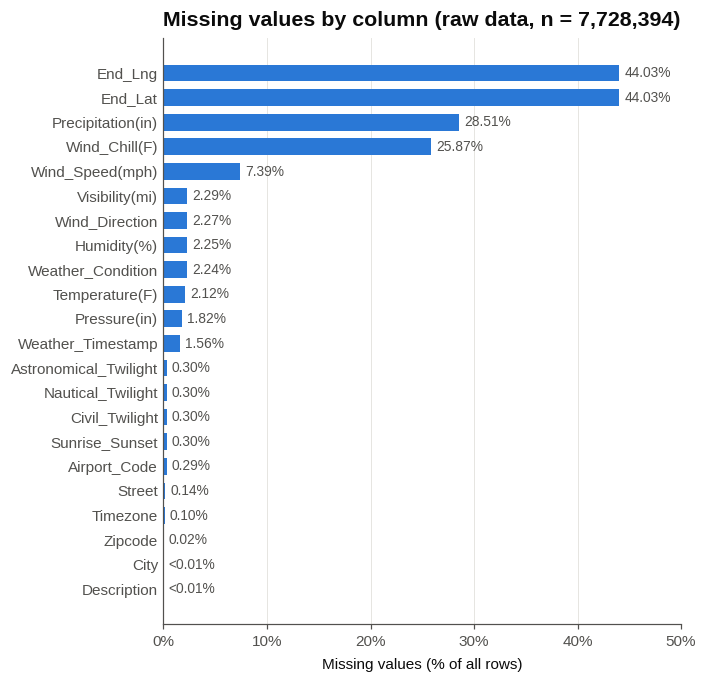

In [14]:
missing_table = (raw_audit.loc[raw_audit["Missing"] > 0, ["Column", "Group", "Missing", "Missing (%)"]]
                 .sort_values("Missing (%)", ascending=False).reset_index(drop=True))

fig_data = missing_table.sort_values("Missing (%)")
fig, ax = plt.subplots(figsize=(6.5, 0.24 * len(fig_data) + 1.0))
ax.barh(fig_data["Column"], fig_data["Missing (%)"], color=COLORS["primary"], height=0.68, zorder=2)
for y, value in enumerate(fig_data["Missing (%)"]):
    ax.text(value + 0.5, y, f"{value:.2f}%" if value >= 0.01 else "<0.01%", va="center", fontsize=9,
            color=COLORS["muted"])
ax.set_xlim(0, max(50, 10 * np.ceil(fig_data["Missing (%)"].max() / 10)))
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_xlabel("Missing values (% of all rows)", fontsize=10, labelpad=6)
ax.grid(axis="x", zorder=0)
ax.tick_params(axis="x", labelsize=10)
ax.tick_params(axis="y", length=0, labelsize=10)
ax.set_title(f"Missing values by column (raw data, n = {n_rows_raw:,})", fontsize=14, pad=8)
fig.tight_layout()
save_figure(fig, "missing_rate_by_column")
plt.show()

**Question:** is `NaN` the only form of missingness? A value can be marked as missing, it can be a text placeholder, or it can be a legal number that is impossible. Text columns are scanned for placeholder tokens such as "NA", "None", "unknown", "?" and whitespace-only strings, and category labels are scanned for placeholder words.

In [15]:
PLACEHOLDER_TOKENS = ["", "na", "n/a", "nan", "null", "none", "unknown", "?", "-", "--", "missing",
                      "not available", "undefined"]
PLACEHOLDER_WORD_PATTERN = r"(?i)\b(?:n/a|null|none|unknown|missing|undefined|not available)\b"
MAX_TOKEN_LENGTH = max(len(t) for t in PLACEHOLDER_TOKENS) + 5  # longer strings cannot be bare tokens

rows = []
for c in CATEGORICAL_COLS + STRING_COLS + DATETIME_COLS:
    if c in LEVEL_COUNTS:
        counts = LEVEL_COUNTS[c]
    else:  # unique or free-text column: only short strings can be bare placeholder tokens
        short = (df[c].str.len() <= MAX_TOKEN_LENGTH).to_numpy(dtype=bool, na_value=False)
        counts = df.loc[short, c].value_counts()
    levels = counts.index.astype(str)
    exact = levels.str.strip().str.lower().isin(PLACEHOLDER_TOKENS)
    contains = levels.str.contains(PLACEHOLDER_WORD_PATTERN, regex=True) & ~exact
    for i in np.flatnonzero(exact | contains):
        if int(counts.iloc[i]):
            rows.append({"Column": c, "Value": levels[i], "Match": "exact token" if exact[i] else "contains word",
                         "Rows": int(counts.iloc[i])})
placeholder_inventory = pd.DataFrame(rows, columns=["Column", "Value", "Match", "Rows"])
n_placeholder_description = int(placeholder_inventory.query("Column == 'Description' and Value == 'Unknown'")["Rows"].sum())
n_na_precipitation = int(placeholder_inventory.query("Column == 'Weather_Condition' and Value == 'N/A Precipitation'")["Rows"].sum())
assert set(placeholder_inventory["Column"]) <= {"Description", "Weather_Condition", "Street"}, "New placeholder column found"
street_matches = placeholder_inventory.query("Column == 'Street'").sort_values("Rows", ascending=False)
print(f"Exact placeholder token: Description = 'Unknown' in {n_placeholder_description:,} rows.")
print(f"Placeholder word inside a value: Weather_Condition = 'N/A Precipitation' in {n_na_precipitation:,} rows; "
      f"{int(street_matches['Rows'].sum())} Street values in {len(street_matches)} names, e.g. "
      + ", ".join(f"'{v}'" for v in street_matches["Value"].head(2)) + ".")

Exact placeholder token: Description = 'Unknown' in 34 rows.
Placeholder word inside a value: Weather_Condition = 'N/A Precipitation' in 3,252 rows; 16 Street values in 10 names, e.g. 'Virginia Center Commons Access None', 'Missing Link Rd'.


Apart from `NaN`, the scan finds one placeholder and two kinds of placeholder-like text:

- **Text placeholder.** `Description` = "Unknown" stands for an absent description. It is converted to missing in Section 1.4.
- **Placeholder-like label.** `Weather_Condition` = "N/A Precipitation" records precipitation of unidentified type, which is an observation, so it is kept.
- **Placeholder-like street names.** A few `Street` values contain such a word inside a longer name, for example "Missing Link Rd". With 16 rows, they are kept unchanged.

Invalid numbers are checked in Section 1.3.7, and the end coordinates, which are missing for whole providers, in Section 2.2.3. Explicit missing values are not imputed or dropped at this stage.

### 1.3.6 Categorical representation problems

**Wind_Direction.** Two coding schemes are mixed for the same directions. The canonical labels follow the 16-point abbreviations already used by most levels, plus `CALM` and `VAR`.

In [16]:
WIND_DIRECTION_CANONICAL = {"Calm": "CALM", "Variable": "VAR", "North": "N", "South": "S", "East": "E", "West": "W"}
COMPASS_ORDER = ["N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE", "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW",
                 "CALM", "VAR"]
wind_levels = LEVEL_COUNTS["Wind_Direction"].rename("Rows").rename_axis("Raw label").reset_index()
wind_levels["Raw label"] = wind_levels["Raw label"].astype(str)
wind_levels["Canonical label"] = wind_levels["Raw label"].replace(WIND_DIRECTION_CANONICAL)
assert set(wind_levels["Canonical label"]) == set(COMPASS_ORDER), "Unexpected Wind_Direction label"
wind_levels["order"] = wind_levels["Canonical label"].map({k: i for i, k in enumerate(COMPASS_ORDER)})
wind_levels = wind_levels.sort_values(["order", "Rows"], ascending=[True, False]).drop(columns="order")
save_table(wind_levels, "wind_direction_mapping")
n_wind_labels_raw, n_wind_labels_clean = len(wind_levels), len(COMPASS_ORDER)
n_wind_rows_relabelled = int(wind_levels.loc[wind_levels["Raw label"] != wind_levels["Canonical label"], "Rows"].sum())

merged = wind_levels[wind_levels["Canonical label"].duplicated(keep=False)]
show_table(merged[["Raw label", "Canonical label", "Rows"]],
           caption=f"Wind_Direction labels that are merged: {n_wind_labels_raw} raw labels become "
                   f"{n_wind_labels_clean} canonical labels ({n_wind_rows_relabelled:,} rows relabelled)")

Raw label,Canonical label,Rows
N,N,"307,151"
North,N,"153,385"
E,E,"278,914"
East,E,"103,545"
S,S,"419,989"
South,S,"177,375"
W,W,"383,913"
West,W,"164,751"
CALM,CALM,"961,624"
Calm,CALM,"368,557"


**Whitespace, case variants and formats.** The consistency scan covers every categorical column, plus `Street` and `Description`. Only the issues it finds are shown.

In [17]:
NEAR_CONSTANT_SHARE = 99.5    # % of non-missing rows in one level
HIGH_CARDINALITY_LEVELS = 1_000
WHITESPACE_ROWS, rows = {}, []
for c in CATEGORICAL_COLS + ["Street", "Description"]:
    if c in LEVEL_COUNTS:
        counts = LEVEL_COUNTS[c]
        levels = counts.index.astype(str)
        ws_rows = int(counts[levels != levels.str.strip()].sum())
        stripped = counts.groupby(levels.str.strip()).sum()  # whitespace variants merged first
        case_variant = pd.Index(stripped.index.str.lower()).duplicated(keep=False)
        case_levels, case_rows = int(case_variant.sum()), int(stripped[case_variant].sum())
        n_levels = int((counts > 0).sum())
    else:  # free text: whitespace only
        ws_rows = int(df[c].ne(df[c].str.strip()).sum())
        case_levels = case_rows = pd.NA
        n_levels = int(raw_audit.set_index("Column").at[c, "Unique"])
    WHITESPACE_ROWS[c] = ws_rows
    rows.append({"Column": c, "Levels": n_levels, "Rows with leading/trailing whitespace": ws_rows,
                 "Case-variant levels": case_levels, "Rows in case-variant levels": case_rows})
categorical_consistency = pd.DataFrame(rows).astype({"Case-variant levels": "Int64", "Rows in case-variant levels": "Int64"})
consistency = categorical_consistency.set_index("Column")

def whitespace_example(value, keep=30):
    """repr() of a value, shortened from the front so trailing whitespace stays visible."""
    return repr(value) if len(value) <= keep else "..." + repr(value[-keep:])


def largest_case_variant_group(column):
    """Largest group of levels that differ only in letter case (whitespace variants merged first)."""
    counts = LEVEL_COUNTS[column]
    frame = pd.DataFrame({"level": counts.index.astype(str).str.strip(), "rows": counts.to_numpy()})
    frame = frame.groupby("level", as_index=False)["rows"].sum()
    frame["key"] = frame["level"].str.lower()
    frame = frame[frame["key"].duplicated(keep=False)]
    top_key = frame.groupby("key")["rows"].sum().idxmax()
    return " | ".join(frame.loc[frame["key"] == top_key, "level"])


whitespace_examples = {
    "Street": df.loc[df["Street"].str.startswith(" ").to_numpy(dtype=bool, na_value=False), "Street"].iloc[0],
    "Description": df.loc[df["Description"].str.endswith("\xa0").to_numpy(dtype=bool, na_value=False), "Description"].iloc[0]}
zip_counts = LEVEL_COUNTS["Zipcode"]
zip_formats = zip_counts.groupby(zip_counts.index.astype(str).str.replace(r"\d", "9", regex=True)).sum()
n_zip_other = int(zip_formats.drop(["99999", "99999-9999"], errors="ignore").sum())

representation_issues = pd.DataFrame(
    [(c, "Leading/trailing whitespace", whitespace_example(whitespace_examples[c]), WHITESPACE_ROWS[c])
     for c in ["Street", "Description"]]
    + [(c, "Same name in different letter case",
        f"{int(consistency.at[c, 'Case-variant levels'])} levels, e.g. {largest_case_variant_group(c)}",
        int(consistency.at[c, "Rows in case-variant levels"])) for c in ["City", "County", "Street"]]
    + [("Zipcode", "5-digit and ZIP+4 mixed, plus other formats",
        " / ".join(f"{fmt}: {pct(n, zip_counts.sum()):.2f}%" for fmt, n in zip_formats.sort_values(ascending=False).items()),
        n_zip_other)],
    columns=["Column", "Issue", "Evidence", "Rows"])
show_table(representation_issues, caption="Representation issues in text and category columns")

Column,Issue,Evidence,Rows
Street,Leading/trailing whitespace,' State Route 32',"1,696,520"
Description,Leading/trailing whitespace,...'ar Exit 65 (South Boulevard).\xa0',"4,454"
City,Same name in different letter case,"111 levels, e.g. King Of Prussia | King of Prussia","20,533"
County,Same name in different letter case,"48 levels, e.g. DuPage | Dupage","97,145"
Street,Same name in different letter case,"448 levels, e.g. MCFARLAND BLVD E | McFarland Blvd E","18,394"
Zipcode,"5-digit and ZIP+4 mixed, plus other formats",99999: 70.64% / 99999-9999: 29.32% / 99999-99ND: 0.04%,"3,017"


Trimming whitespace is lossless and is applied in Section 1.4. Case variants refer to the same place, but merging them only matters if these high-cardinality columns are encoded, so it is deferred. The mixed `Zipcode` formats are also kept; a five-digit code can be derived later if the column is used.

### 1.3.7 Impossible versus extreme numeric values

`describe()` in Section 1.2.3 showed values far from the bulk of several measurements. Three different questions are kept apart:

| Concept | Meaning | Treatment |
|---|---|---|
| Invalid by definition | The value violates the mathematical or semantic definition of the variable | Set to missing (Section 1.4) |
| Statistical anomaly | The value is far from the bulk but breaks no documented or definitional validity rule: unusual, not proven invalid | Characterized here; kept unchanged |
| Model-dependent preprocessing | Transforming, scaling, clipping, winsorizing or imputing | Deferred until the model family is known |

A historical weather record is not a definition. A reading beyond a record is unusual and deserves inspection, but it is not invalid by definition, so record values are not used as cleaning thresholds.

**Step 1: definition-based validity rules.**

In [18]:
ABSOLUTE_ZERO_F = -459.67
VALIDITY_RULES = [  # (column, valid values, basis, test for invalid values)
    ("Start_Lat", "-90 to 90", "Latitude domain", lambda v: (v < -90) | (v > 90)),
    ("End_Lat", "-90 to 90", "Latitude domain", lambda v: (v < -90) | (v > 90)),
    ("Start_Lng", "-180 to 180", "Longitude domain", lambda v: (v < -180) | (v > 180)),
    ("End_Lng", "-180 to 180", "Longitude domain", lambda v: (v < -180) | (v > 180)),
    ("Distance(mi)", "≥ 0", "A length cannot be negative", lambda v: v < 0),
    ("Temperature(F)", f"≥ {ABSOLUTE_ZERO_F}", "Absolute zero", lambda v: v < ABSOLUTE_ZERO_F),
    ("Wind_Chill(F)", f"≥ {ABSOLUTE_ZERO_F}", "Absolute zero", lambda v: v < ABSOLUTE_ZERO_F),
    ("Humidity(%)", "0 to 100", "Relative humidity is a percentage", lambda v: (v < 0) | (v > 100)),
    ("Pressure(in)", "> 0", "Atmospheric pressure is positive", lambda v: v <= 0),
    ("Visibility(mi)", "≥ 0", "A distance cannot be negative", lambda v: v < 0),
    ("Wind_Speed(mph)", "≥ 0", "A speed cannot be negative", lambda v: v < 0),
    ("Precipitation(in)", "≥ 0", "An amount cannot be negative", lambda v: v < 0),
]

invalid_masks, rows = {}, []
for column, valid, basis, is_invalid in VALIDITY_RULES:
    values = df[column]
    mask = (is_invalid(values) | np.isinf(values)).to_numpy()  # a measurement must also be finite
    if mask.any():
        invalid_masks[column] = mask
    observed = values[mask].value_counts().sort_index()
    rows.append({"Column": column, "Valid values": f"{valid}, finite", "Basis": basis, "Invalid rows": int(mask.sum()),
                 "Invalid values (rows)": ", ".join(f"{v:g} ({n})" for v, n in observed.items())})
invalid_summary = pd.DataFrame(rows)
invalid_counts = pd.Series({c: int(m.sum()) for c, m in invalid_masks.items()}, dtype="int64")
VALIDITY_BASIS = {column: f"{basis} ({valid})" for column, valid, basis, _ in VALIDITY_RULES}
show_table(invalid_summary, caption="Definition-based validity rules (raw data)", name="invalid_values")

# Cross-field consistency check, reported separately because it is not a definition-based rule
n_wind_chill_above_temp = int((df["Wind_Chill(F)"] > df["Temperature(F)"]).sum())
print(f"Cross-field consistency check, Wind_Chill(F) above Temperature(F) in the same row: {n_wind_chill_above_temp:,} rows "
      "(reported only; no action depends on it)")

Column,Valid values,Basis,Invalid rows,Invalid values (rows)
Start_Lat,"-90 to 90, finite",Latitude domain,0,
End_Lat,"-90 to 90, finite",Latitude domain,0,
Start_Lng,"-180 to 180, finite",Longitude domain,0,
End_Lng,"-180 to 180, finite",Longitude domain,0,
Distance(mi),"≥ 0, finite",A length cannot be negative,0,
Temperature(F),"≥ -459.67, finite",Absolute zero,0,
Wind_Chill(F),"≥ -459.67, finite",Absolute zero,0,
Humidity(%),"0 to 100, finite",Relative humidity is a percentage,0,
Pressure(in),"> 0, finite",Atmospheric pressure is positive,3,0 (3)
Visibility(mi),"≥ 0, finite",A distance cannot be negative,0,


Cross-field consistency check, Wind_Chill(F) above Temperature(F) in the same row: 0 rows (reported only; no action depends on it)


**Step 2: how far do the extremes reach?** Each measurement is shown on its natural scale. The box spans the interquartile range (IQR), the whiskers reach the last value within 1.5 × IQR of the box, and every distinct value beyond the whiskers is drawn once as a dot. The 1.5 × IQR rule is used only to display and inspect values; nothing is removed because of it.

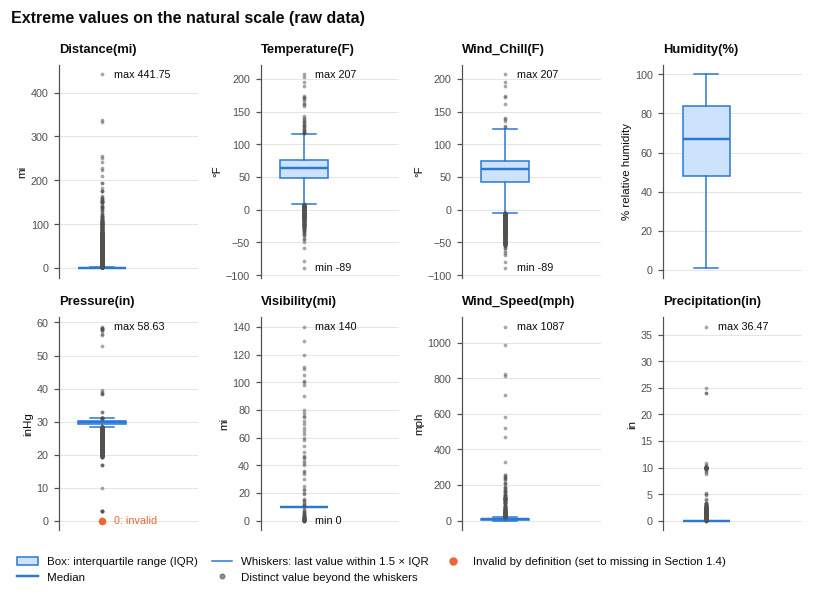

Column,Min,P1,Median,P99,P99.9,Max,IQR,Zero (%),Beyond 1.5 × IQR (%)
Distance(mi),0.00,0.00,0.03,6.95,20.40,441.75,0.46,42.73,12.47
Temperature(F),-89.00,12.20,64.00,96.00,105.10,207.00,27.00,0.04,0.67
Wind_Chill(F),-89.00,-2.00,62.00,96.00,105.00,207.00,32.00,0.07,0.77
Humidity(%),1.00,12.00,67.00,100.00,100.00,100.00,36.00,0.00,0.00
Pressure(in),0.00,24.58,29.86,30.44,30.67,58.63,0.66,0.00,5.84
Visibility(mi),0.00,0.50,10.00,10.00,30.00,140.00,0.00,0.10,19.61
Wind_Speed(mph),0.00,0.00,7.00,23.00,31.10,"1,087.00",5.80,13.44,2.94
Precipitation(in),0.00,0.00,0.00,0.18,0.69,36.47,0.00,90.35,9.65


In [19]:
def distribution_summary(values):
    """Robust summary of one numeric column (missing values excluded)."""
    v = values.dropna().to_numpy(dtype="float64")
    p1, q1, median, q3, p99, p999 = np.quantile(v, [0.01, 0.25, 0.5, 0.75, 0.99, 0.999])
    iqr = q3 - q1
    beyond = (v < q1 - 1.5 * iqr) | (v > q3 + 1.5 * iqr)
    return {"Min": v.min(), "P1": p1, "Q1": q1, "Median": median, "Q3": q3, "P99": p99, "P99.9": p999, "Max": v.max(),
            "IQR": iqr, "Zero (%)": pct((v == 0).sum(), len(v)), "Beyond 1.5 × IQR (%)": pct(beyond.sum(), len(v))}


MEASUREMENT_UNITS = {"Distance(mi)": "mi", "Temperature(F)": "°F", "Wind_Chill(F)": "°F", "Humidity(%)": "% relative humidity",
                     "Pressure(in)": "inHg", "Visibility(mi)": "mi", "Wind_Speed(mph)": "mph", "Precipitation(in)": "in"}  # axis labels

raw_summary = {c: distribution_summary(df[c]) for c in MEASUREMENT_COLS}

fig, axes = plt.subplots(2, 4, figsize=(7.4, 5.4))
for ax, c in zip(axes.flat, MEASUREMENT_COLS):
    v = df[c].dropna().to_numpy(dtype="float64")
    s = raw_summary[c]
    lo_fence, hi_fence = s["Q1"] - 1.5 * s["IQR"], s["Q3"] + 1.5 * s["IQR"]
    inside = v[(v >= lo_fence) & (v <= hi_fence)]
    ax.bxp([{"med": s["Median"], "q1": s["Q1"], "q3": s["Q3"], "whislo": inside.min(), "whishi": inside.max(), "fliers": []}],
           widths=0.5, showfliers=False, patch_artist=True, boxprops={"facecolor": "#cde2fb", "edgecolor": COLORS["primary"]},
           medianprops={"color": COLORS["primary"], "linewidth": 1.6}, whiskerprops={"color": COLORS["primary"]},
           capprops={"color": COLORS["primary"]})
    fliers = np.unique(v[(v < lo_fence) | (v > hi_fence)])  # each distinct value drawn once
    invalid_values = np.unique(df.loc[invalid_masks[c], c]) if c in invalid_masks else np.array([])
    valid_fliers = fliers[~np.isin(fliers, invalid_values)]
    ax.scatter(np.ones(len(valid_fliers)), valid_fliers, s=6, color=COLORS["muted"], alpha=0.5, linewidths=0, zorder=3)
    ax.scatter(np.ones(len(invalid_values)), invalid_values, s=16, color=SERIES_COLORS[1], zorder=4)
    labels = [(s["Max"], f"max {s['Max']:g}", COLORS["ink"])] if s["Max"] > inside.max() else []
    if len(invalid_values):
        labels.append((invalid_values.min(), f"{invalid_values.min():g}: invalid", SERIES_COLORS[1]))
    elif s["Min"] < inside.min():
        labels.append((s["Min"], f"min {s['Min']:g}", COLORS["ink"]))
    for y_value, text, color in labels:
        ax.text(1.12, y_value, text, va="center", ha="left", fontsize=7, color=color)
    ax.set_xlim(0.55, 2.0)
    ax.set_xticks([])
    ax.spines["bottom"].set_visible(False)
    ax.tick_params(axis="y", labelsize=7)
    ax.grid(axis="y", zorder=0)
    ax.set_title(c, fontsize=8.5)
    ax.set_ylabel(MEASUREMENT_UNITS[c], fontsize=7.5, labelpad=2)
fig.suptitle("Extreme values on the natural scale (raw data)", x=0.01, ha="left", fontsize=10.5, fontweight="semibold")
legend_items = [mpl.patches.Patch(facecolor="#cde2fb", edgecolor=COLORS["primary"], label="Box: interquartile range (IQR)"),
                mpl.lines.Line2D([], [], color=COLORS["primary"], linewidth=1.6, label="Median"),
                mpl.lines.Line2D([], [], color=COLORS["primary"], linewidth=1.0, label="Whiskers: last value within 1.5 × IQR"),
                mpl.lines.Line2D([], [], linestyle="none", marker="o", markersize=3, color=COLORS["muted"], alpha=0.6,
                                 label="Distinct value beyond the whiskers"),
                mpl.lines.Line2D([], [], linestyle="none", marker="o", markersize=4.5, color=SERIES_COLORS[1],
                                 label="Invalid by definition (set to missing in Section 1.4)")]
fig.legend(handles=legend_items, loc="lower left", bbox_to_anchor=(0.005, 0.0), ncol=3, fontsize=7.5, handlelength=1.8,
           columnspacing=1.2)
fig.tight_layout(rect=(0, 0.08, 1, 1))
save_figure(fig, "measurement_extremes_boxplots")
plt.show()

anomaly_overview = pd.DataFrame([{"Column": c, **{k: s[k] for k in ["Min", "P1", "Median", "P99", "P99.9", "Max", "IQR", "Zero (%)",
                                                                    "Beyond 1.5 × IQR (%)"]}} for c, s in raw_summary.items()])
show_table(anomaly_overview, caption="Where the bulk ends and how far the extremes reach (raw data)")

**Step 3: are the most extreme values repeated or concentrated?** Exact repetition of an extreme value, or a tail that comes from one station, points to a recording artifact rather than weather. The most extreme 0.01% on each side of every measurement is inspected. This window is for inspection only.

In [20]:
FAR_TAIL = 0.0001  # most extreme 0.01% on each side: an inspection window, not a cleaning rule
rows = []
for c in MEASUREMENT_COLS:
    values = df[c]
    for side, cut in (("Lower", values.quantile(FAR_TAIL)), ("Upper", values.quantile(1 - FAR_TAIL))):
        mask = ((values < cut) if side == "Lower" else (values > cut)).to_numpy()
        if not mask.any():
            continue
        tail = df.loc[mask, [c, "Airport_Code"]]
        stations, by_value = tail["Airport_Code"].value_counts(), tail[c].value_counts()
        extremes = by_value.sort_index(ascending=(side == "Lower")).head(3)
        rows.append({"Column": c, "Tail": f"{side} 0.01% ({'below' if side == 'Lower' else 'above'} {cut:.4g})", "Rows": int(mask.sum()),
                     "Stations": int((stations > 0).sum()),
                     "Top station (share)": f"{stations.index[0]} ({pct(stations.iloc[0], mask.sum()):.0f}%)",
                     "Most frequent value (rows)": f"{by_value.index[0]:g} ({by_value.iloc[0]})",
                     "Most extreme values (rows)": ", ".join(f"{v:g} ({n})" for v, n in extremes.items())})
numeric_anomalies = pd.DataFrame(rows)
show_table(numeric_anomalies, caption="The most extreme 0.01% of each measurement (raw data)", name="numeric_anomalies")

CONUS_BOX = {"lat": (24.3, 49.5), "lng": (-125.0, -66.9)}  # approximate contiguous-US extent
outside_box = ~(df["Start_Lat"].between(*CONUS_BOX["lat"]) & df["Start_Lng"].between(*CONUS_BOX["lng"]))
print(f"Start locations outside an approximate contiguous-US box: {int(outside_box.sum()):,}")

Column,Tail,Rows,Stations,Top station (share),Most frequent value (rows),Most extreme values (rows)
Distance(mi),Upper 0.01% (above 49.18),771,239,KHMZ (7%),57.25 (23),"441.75 (1), 336.57 (1), 333.63 (1)"
Temperature(F),Lower 0.01% (below -19),723,110,KVDF (9%),-20 (135),"-89 (10), -77.8 (11), -58 (1)"
Temperature(F),Upper 0.01% (above 111),749,87,KPHX (26%),113 (178),"207 (3), 203 (1), 196 (5)"
Wind_Chill(F),Lower 0.01% (below -38),543,101,KMSP (11%),-39 (49),"-89 (10), -80 (1), -69 (1)"
Wind_Chill(F),Upper 0.01% (above 111),470,63,KPHX (29%),112 (169),"207 (3), 196 (5), 189 (1)"
Humidity(%),Lower 0.01% (below 3),238,39,KLGB (13%),2 (189),"1 (49), 2 (189)"
Pressure(in),Lower 0.01% (below 20.24),756,41,K5SM (74%),20.21 (40),"0 (3), 0.02 (1), 0.12 (1)"
Pressure(in),Upper 0.01% (above 30.82),624,129,KDET (11%),30.84 (108),"58.63 (9), 58.39 (2), 58.32 (1)"
Visibility(mi),Upper 0.01% (above 70),502,13,KCIC (67%),80 (301),"140 (3), 130 (1), 120 (5)"
Wind_Speed(mph),Upper 0.01% (above 43),663,163,KLVM (8%),44 (86),"1087 (1), 984 (1), 822.8 (7)"


Start locations outside an approximate contiguous-US box: 0


- **Invalid by definition.** Only `Pressure(in)` breaks a validity rule: atmospheric pressure must be positive, yet 3 raw rows record 0 inHg. These three values become missing in Section 1.4. No other value breaks the definition-based rules of Step 1, and a separate cross-field consistency check, wind chill above the air temperature of the same row, finds no case. Passing these rules shows only that a value is not impossible by definition, not that it is correct.
- **Statistical anomalies.** Every measurement except `Humidity(%)` has values far beyond the bulk, up to 207 °F, 1,087 mph and 58.63 inHg. Some extremes repeat exactly (−89 °F in 10 rows, 822.8 mph in 7 rows), and some far tails come mostly from one station: most of the top 0.01% of precipitation readings are from KJRB, many of them exactly 9.99 in. These patterns point to sensor, station or unit problems, but they do not prove that a particular reading is wrong, and the dataset provides no authoritative validity bounds for every measurement. A statistically unusual value is therefore not treated as invalid: these values are neither deleted nor converted to missing, but kept unchanged and flagged.
- **Why no automatic outlier rule.** The 1.5 × IQR rule flags 9.65% of precipitation readings (every non-zero amount) and 19.61% of visibility readings (every value other than 10 miles). The long low-pressure tail is consistent with station pressure at high elevation. A generic rule would delete real weather.

**Policy.** Extreme values are retained unless they violate a documented or definitionally necessary validity rule. The 1.5 × IQR rule is used only to inspect distributions, not as an automatic deletion rule. Whether retained extremes are transformed depends on the model family, so any transformation is fit within the training pipeline (Section 2.6).

### 1.3.8 Availability at prediction time (leakage screen)

The intended use is to predict `Severity` when an accident is first reported. `Severity` measures the accident's impact on traffic, so a field that records how long or how far the impact extended is a proxy for the target, and using it would cause prediction-time leakage. Leakage candidates are documented here, not removed.

| Feature | Concern | Available when the accident is first reported? | Status |
|---|---|---|---|
| `End_Time` | High | No. It records when the traffic impact cleared, and duration is a near-direct proxy for the impact; 4,229 rows exceed one year (Section 1.3.4) | Likely leakage |
| `End_Lat`, `End_Lng` | High | No. They mark the end of the affected road segment, i.e. the extent of the impact; recorded by Source1 only | Likely leakage |
| `Distance(mi)` | High | No. It is the length of road affected, an outcome of the impact; zero for 85% of Source2 records (Section 2.2.4) | Likely leakage; association checked in Section 2.3.3.6 |
| `Source` | Medium | Yes, but it is a provider label, not a property of the accident; providers differ structurally (Section 2.2) | Kept as provenance; excluded from the baseline predictors (Section 2.6) |
| `Description` | Medium | Partly. It is provider-written text that may be updated as the incident develops | Excluded from the baseline tabular features (Section 2.6) |
| `ID` | Not a feature | A serial row key ordered by source and collection (Section 1.3.2) | Kept as row key only |
| `Country`, `Turning_Loop` | Not a feature | Constant in every row (Section 1.3.2) | Dropped in Section 1.4 |
| Start time and location, weather, road flags, daylight | Low | Yes. Static location attributes, or conditions observed near the start; `Weather_Timestamp` is more than one hour from `Start_Time` in 93,903 rows (Section 1.3.4) | Kept for now |

## 1.4 Objective Cleaning Actions

This section turns the raw data (A) into the analysis dataset after objective cleaning (B). Only the actions justified in Section 1.3 are applied. Nothing is imputed, scaled, encoded, grouped or removed as an outlier. Extreme values that break no validity rule stay unchanged, and leakage candidates stay in the data. Duplicate rows are removed last, so every row mask computed in Section 1.3 still lines up with `df`.

In [21]:
assert len(df) == n_rows_raw and df.shape[1] == RAW_SHAPE[1], "Run the notebook from the top: df is not in its raw state"

# 1. Constant columns
df = df.drop(columns=CONSTANT_COLS)
log_cleaning(f"Constant columns ({', '.join(CONSTANT_COLS)})", ", ".join(CONSTANT_COLS),
             "Dropped", "One value in every row, no missing values", 0)

# 2. Timestamps
for c in DATETIME_COLS:
    df[c] = parsed_datetimes[c]
log_cleaning("Timestamps stored as text", ", ".join(DATETIME_COLS), "Parsed to datetime64 (local time)",
             f"{n_timestamp_formats} text formats; {n_datetime_failures} parse failures", n_rows_raw)

# 3. Whitespace
for c, n in WHITESPACE_ROWS.items():
    if not n:
        continue
    if isinstance(df[c].dtype, pd.CategoricalDtype):
        df[c] = remap_categories(df[c], {level: level.strip() for level in df[c].cat.categories})
    else:
        df[c] = df[c].str.strip()
    log_cleaning(f"Whitespace in {c}", c, "Trimmed leading/trailing whitespace",
                 f"{n:,} values with leading or trailing whitespace", n)

# 4. Wind_Direction labels
df["Wind_Direction"] = remap_categories(df["Wind_Direction"], WIND_DIRECTION_CANONICAL, order=COMPASS_ORDER)
log_cleaning("Inconsistent Wind_Direction labels", "Wind_Direction", "Mapped to 16-point abbreviations plus CALM and VAR",
             f"{n_wind_labels_raw} raw labels encode {n_wind_labels_clean} directions", n_wind_rows_relabelled)

# 5. Text placeholder
mask = df["Description"].eq("Unknown").to_numpy(dtype=bool, na_value=False)
df["Description"] = df["Description"].mask(mask)
log_cleaning("Placeholder 'Unknown' in Description", "Description", "Converted to missing",
             "Placeholder for an absent free-text description", mask.sum())

# 6. Definitionally invalid numeric values (extreme but valid values are not changed)
for c, mask in invalid_masks.items():
    df[c] = df[c].mask(mask)
    log_cleaning(f"Invalid values in {c}", c, "Set to missing", f"Violates the definition: {VALIDITY_BASIS[c]}", mask.sum())

# 7. Confirmed duplicates (last, so the positional masks above stay aligned)
df = df.loc[~dup_mask]
df.index.name = "raw_row"  # original row position in the CSV, kept for traceability
log_cleaning("Duplicate records hidden by ID", "All except ID", "Removed later copies, kept first occurrence",
             f"Identical in all {len(CONTENT_COLS)} content columns: {n_dup_excl_id:,} as raw text, "
             f"{n_dup_timestamp_only:,} more after timestamp parsing", n_dup_total)
del parsed_datetimes, invalid_masks

cleaning_log = pd.DataFrame(CLEANING_LOG.values())
save_table(cleaning_log, "cleaning_log")
show_table(cleaning_log[["Issue", "Evidence", "Action", "Rows affected"]], caption="Cleaning actions applied")

Issue,Evidence,Action,Rows affected
"Constant columns (Country, Turning_Loop)","One value in every row, no missing values",Dropped,0
Timestamps stored as text,3 text formats; 0 parse failures,Parsed to datetime64 (local time),"7,728,394"
Whitespace in Street,"1,696,520 values with leading or trailing whitespace",Trimmed leading/trailing whitespace,"1,696,520"
Whitespace in Description,"4,454 values with leading or trailing whitespace",Trimmed leading/trailing whitespace,"4,454"
Inconsistent Wind_Direction labels,24 raw labels encode 18 directions,Mapped to 16-point abbreviations plus CALM and VAR,"1,081,609"
Placeholder 'Unknown' in Description,Placeholder for an absent free-text description,Converted to missing,34
Invalid values in Pressure(in),Violates the definition: Atmospheric pressure is positive (> 0),Set to missing,3
Duplicate records hidden by ID,"Identical in all 45 content columns: 102,338 as raw text, 15,357 more after timestamp parsing","Removed later copies, kept first occurrence","117,695"


## 1.5 Validation and Analysis Dataset

In [22]:
n_dup_clean = int(pd.Series(row_hash(df, [c for c in df.columns if c != ID_COL])).duplicated().sum())
clean_audit = structural_audit(df, include_unique=False)
save_table(clean_audit.loc[clean_audit["Missing"] > 0, ["Column", "Group", "Missing", "Missing (%)"]]
           .sort_values("Missing (%)", ascending=False), "missing_values")
clean_memory_gb = df.memory_usage(deep=True).drop("Index").sum() / 1e9
n_target_missing_clean, n_target_invalid_clean = target_integrity(df)
n_datetime_cols_clean = sum(pd.api.types.is_datetime64_any_dtype(df[c]) for c in DATETIME_COLS)

validation = pd.DataFrame({
    "Check": ["Rows", "Columns", "Duplicate rows (ID excluded)", "Timestamp parse failures",
              "Timestamp columns stored as datetime64", "Target missing / invalid", "Columns with missing values",
              "In-memory size (GB)"],
    "Raw": [f"{RAW_SHAPE[0]:,}", f"{RAW_SHAPE[1]}", f"{n_dup_total:,}", "", "0 of 3",
            f"{n_target_missing} / {n_target_invalid}", f"{int((raw_audit['Missing'] > 0).sum())}", f"{raw_memory_gb:.2f}"],
    "After objective cleaning": [f"{len(df):,}", f"{df.shape[1]}", f"{n_dup_clean:,}", f"{n_datetime_failures}", f"{n_datetime_cols_clean} of 3",
              f"{n_target_missing_clean} / {n_target_invalid_clean}", f"{int((clean_audit['Missing'] > 0).sum())}",
              f"{clean_memory_gb:.2f}"],
})
show_table(validation, caption="Validation: raw data versus the analysis dataset after objective cleaning", name="validation_before_after")

assert n_dup_clean == 0, "Duplicates remain after cleaning"
assert n_target_missing_clean == 0 and n_target_invalid_clean == 0, "Target integrity failed"
assert n_datetime_cols_clean == len(DATETIME_COLS), "A timestamp column is not datetime64"
assert not set(CONSTANT_COLS) & set(df.columns) and len(df) == n_rows_raw - n_dup_total

Check,Raw,After objective cleaning
Rows,"7,728,394","7,610,699"
Columns,46,44
Duplicate rows (ID excluded),"117,695",0
Timestamp parse failures,,0
Timestamp columns stored as datetime64,0 of 3,3 of 3
Target missing / invalid,0 / 0,0 / 0
Columns with missing values,22,22
In-memory size (GB),2.37,1.87


**What objective cleaning accomplished** (validation table above):

- **Raw data:** 7,728,394 rows × 46 columns.
- **Analysis dataset after objective cleaning:** 7,610,699 rows × 44 columns.
- **Confirmed duplicate rows removed:** 117,695; none remain.
- **Timestamp parsing failures:** 0; all three timestamp columns are stored as datetime64.
- **Target missing / invalid:** 0 / 0.
- **Columns that still contain missing values:** 22.

The 22 columns with missing values do not mean that objective cleaning failed. No objective rule can fill them: the correct treatment depends on the missingness mechanism, on whether the field is available at prediction time, on whether the feature is used at all, and on the modeling pipeline. Nothing is imputed in Part 1. Part 2 studies the missingness (Sections 2.2.3 and 2.3.3.5), and Section 2.6 states the resulting policy.

The analysis dataset is therefore not model-ready. These issues remain open and are examined in Part 2:

- class imbalance (Section 2.1.1);
- missing values, whose mechanisms depend on the provider and the collection period (Section 2.2.3);
- retained extreme values and station-concentrated tails (Section 1.3.7);
- leakage candidates (Section 1.3.8);
- high-cardinality location fields and candidate equivalent weather labels (Sections 2.1.2 and 2.2.2);
- 91,976 rows that share start time, end time and start location with another row without being identical, possibly repeated reports (Section 1.3.3);
- case variants and mixed `Zipcode` formats (Section 1.3.6).

# Part 2. Exploratory Data Analysis (EDA) 

**Data used.** Part 2 uses the analysis dataset after objective cleaning from Section 1.5 (dataset B: 7,610,699 rows × 44 columns), called *the analysis dataset* from here on. It is suitable for EDA but not model-ready: missing values, retained extreme observations, high-cardinality variables and leakage candidates are still present, and nothing is imputed, encoded or excluded. The missing weather values in particular are left unresolved on purpose: Sections 2.2.3 and 2.3.3.5 study why they are missing, and Section 2.6 states how they should be treated. Keys such as hour, road class or missing-value indicators are computed for the analysis only, and a fingerprint check after Section 2.4.4 confirms that `df` is unchanged. Figure titles therefore do not repeat the data state.

**Structure.** Section 2.1 describes each variable, 2.2 checks the patterns against the data providers and the collection period, 2.3 relates every candidate feature to the four Severity levels, and 2.4 tests whether the strongest relationships remain within comparable strata. Section 2.5 lists the key insights, and 2.6 the preparation implications for Part 3.

## 2.1 Univariate EDA

This section describes the data one variable at a time. Frequency and shape describe the dataset, not predictive value, and relationships with `Severity` are left to Section 2.3. No data is modified here: groupings such as "Top 15 + Other" exist only inside figures.

In [23]:
import matplotlib.dates as mdates


def frame_fingerprint(frame):
    """Cheap summary that changes if rows, columns, dtypes, missingness, the target or the index change."""
    return {"shape": frame.shape, "dtypes": tuple(frame.dtypes.astype(str)), "non_missing_cells": int(frame.count().sum()),
            "target_sum": int(frame[TARGET].sum()), "index_sum": int(frame.index.to_numpy().sum())}


CLEAN_FINGERPRINT = frame_fingerprint(df)  # fingerprint of the analysis dataset used from here on
n_clean = len(df)
SOURCES = sorted(df["Source"].cat.categories)
SOURCE_COLORS = dict(zip(SOURCES, SERIES_COLORS))
SOURCE_LINESTYLES = dict(zip(SOURCES, ["-", (0, (5, 2)), (0, (1, 1.2))]))  # second visual channel, for grayscale print
SOURCE_HATCHES = dict(zip(SOURCES, [None, "////", "...."]))
TOP_N = 15
MINOR_GRID = "#efeeea"  # lighter than the major gridlines


def top_n_with_other(counts, n, other_label):
    """Top-n levels plus one aggregated remainder, for display only."""
    top = counts.head(n).copy()
    top.index = top.index.astype(str)
    if len(counts) > n:
        top[other_label] = counts.iloc[n:].sum()
    return top


def value_grid(ax, axis="y"):
    """Major gridlines for reading values and lighter minor gridlines between them, behind the data."""
    ax.grid(axis=axis, which="major", color=COLORS["grid"], linewidth=0.7)
    ax.grid(axis=axis, which="minor", color=MINOR_GRID, linewidth=0.5)
    ax.set_axisbelow(True)


def month_axis(ax):
    """Calendar x-axis: a labelled tick at each January and a minor tick, labelled 'Jul', at each July."""
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.xaxis.set_minor_locator(mdates.MonthLocator(bymonth=7))
    ax.xaxis.set_minor_formatter(mdates.DateFormatter("Jul"))
    ax.tick_params(axis="x", which="minor", length=2.5, labelsize=6.5, labelcolor=COLORS["muted"])
    value_grid(ax, "x")

### 2.1.1 Target distribution

**Question:** how is the prediction target distributed?

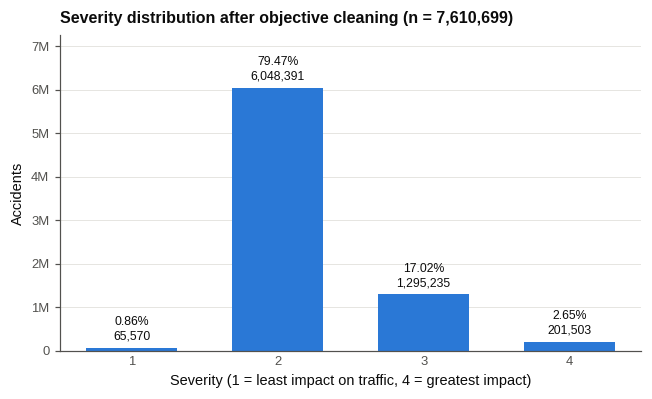

Majority class: Severity 2 (79.47%). Smallest class: Severity 1 (0.86%, 65,570 rows). Imbalance ratio: 92.2.
Modeling note: always predicting Severity 2 gives 79.47% accuracy, but only 25.00% balanced accuracy and 0.221 macro-F1.


In [24]:
severity_counts = df[TARGET].value_counts().sort_index()
severity_distribution = pd.DataFrame({"Severity": severity_counts.index.astype(int), "Count": severity_counts.to_numpy()})
severity_distribution["Share (%)"] = 100 * severity_distribution["Count"] / n_clean
severity_distribution["Majority-to-class ratio"] = severity_distribution["Count"].max() / severity_distribution["Count"]
save_table(severity_distribution, "severity_distribution")  # the figure shows the same counts and shares

fig, ax = plt.subplots(figsize=(6.0, 3.7))
counts = severity_distribution["Count"].to_numpy()
ax.bar(severity_distribution["Severity"].astype(str), counts, color=COLORS["primary"], width=0.62, zorder=2)
for x, (n, share) in enumerate(zip(counts, severity_distribution["Share (%)"])):
    ax.text(x, n + 0.02 * counts.max(), f"{share:.2f}%\n{n:,}", ha="center", va="bottom", fontsize=8, linespacing=1.3)
ax.set_ylim(0, counts.max() * 1.2)
ax.yaxis.set_major_formatter(millions)
ax.set_xlabel("Severity (1 = least impact on traffic, 4 = greatest impact)")
ax.set_ylabel("Accidents")
ax.grid(axis="y", zorder=0)
ax.tick_params(axis="x", length=0)
ax.set_title(f"Severity distribution after objective cleaning (n = {n_clean:,})")
fig.tight_layout()
save_figure(fig, "severity_distribution")
plt.show()

majority = severity_distribution.loc[severity_distribution["Count"].idxmax()]
minority = severity_distribution.loc[severity_distribution["Count"].idxmin()]
p_majority = majority["Share (%)"] / 100
imbalance_ratio = majority["Count"] / minority["Count"]
baseline_balanced_accuracy = 100 / len(severity_distribution)
baseline_macro_f1 = (2 * p_majority / (1 + p_majority)) / len(severity_distribution)
print(f"Majority class: Severity {int(majority['Severity'])} ({majority['Share (%)']:.2f}%). "
      f"Smallest class: Severity {int(minority['Severity'])} ({minority['Share (%)']:.2f}%, {int(minority['Count']):,} rows). "
      f"Imbalance ratio: {imbalance_ratio:.1f}.")
print(f"Modeling note: always predicting Severity {int(majority['Severity'])} gives {100 * p_majority:.2f}% accuracy, "
      f"but only {baseline_balanced_accuracy:.2f}% balanced accuracy and {baseline_macro_f1:.3f} macro-F1.")

One intermediate class dominates the target. Accuracy alone therefore cannot show whether the minority classes are learned, and class proportions must be preserved when the data are split. Even the smallest class has tens of thousands of rows, so the imbalance is relative rather than a shortage of data.

### 2.1.2 Categorical features: first look

In [25]:
LOW_CARDINALITY_MAX = 20
RARE_LEVEL_SHARE = 0.01  # % of non-missing rows
CATEGORY_FEATURES = [c for c in CATEGORICAL_COLS if c in df.columns] + ["Street"]
BOOLEAN_FEATURES = [c for c in BOOLEAN_COLS if c in df.columns]
CLEAN_LEVEL_COUNTS = {c: (lambda vc: vc[vc > 0])(df[c].value_counts()) for c in CATEGORY_FEATURES + BOOLEAN_FEATURES}


def cardinality_class(n_levels, top_share):
    if top_share >= NEAR_CONSTANT_SHARE:
        return "near-constant"
    if n_levels == 2:
        return "binary"
    if n_levels <= LOW_CARDINALITY_MAX:
        return "low"
    return "moderate" if n_levels <= HIGH_CARDINALITY_LEVELS else "high"


def cramers_v_with_source(column):
    """Cramér's V between a column and Source (missing values excluded); exported as supporting evidence."""
    table = pd.crosstab(df[column], df["Source"]).to_numpy(dtype=float)
    table = table[table.sum(axis=1) > 0]
    n = table.sum()
    expected = np.outer(table.sum(axis=1), table.sum(axis=0)) / n
    return float(np.sqrt(((table - expected) ** 2 / expected).sum() / (n * (min(table.shape) - 1))))


rows = []
for c in CATEGORY_FEATURES + BOOLEAN_FEATURES:
    counts = CLEAN_LEVEL_COUNTS[c]
    shares = 100 * counts / counts.sum()
    klass = cardinality_class(len(counts), float(shares.iloc[0]))
    rows.append({"Column": c, "Group": COLUMN_TO_GROUP[c], "Levels": len(counts),
                 "Missing (%)": pct(n_clean - int(counts.sum()), n_clean),
                 "Most common": str(counts.index[0]), "Most common share (%)": float(shares.iloc[0]),
                 "Rare levels": int((shares < RARE_LEVEL_SHARE).sum()),
                 "Levels covering 95% of rows": int(np.searchsorted(shares.cumsum().to_numpy(), 95.0) + 1),
                 "Cardinality class": klass,
                 "Cramér's V with Source": np.nan if (klass == "high" or c == "Source") else cramers_v_with_source(c)})
rows.append({"Column": "Description", "Group": "Text", "Levels": int(df["Description"].nunique()),
             "Missing (%)": pct(n_clean - int(df["Description"].count()), n_clean), "Most common": "",
             "Most common share (%)": np.nan, "Rare levels": pd.NA, "Levels covering 95% of rows": pd.NA,
             "Cardinality class": "free text", "Cramér's V with Source": np.nan})
CLASS_ORDER = {"near-constant": 0, "binary": 1, "low": 2, "moderate": 3, "high": 4, "free text": 5}
categorical_landscape = (pd.DataFrame(rows).astype({"Rare levels": "Int64", "Levels covering 95% of rows": "Int64"})
                         .assign(order=lambda t: t["Cardinality class"].map(CLASS_ORDER))
                         .sort_values(["order", "Levels"]).drop(columns="order").reset_index(drop=True))
save_table(categorical_landscape, "categorical_landscape")
cat = categorical_landscape.set_index("Column")

show_table(categorical_landscape.loc[~categorical_landscape["Column"].isin(BOOLEAN_FEATURES),
                                     ["Column", "Levels", "Missing (%)", "Most common", "Most common share (%)", "Cardinality class"]],
           caption="Categorical and text columns after objective cleaning (road-feature flags in Section 2.1.2.4)")

Column,Levels,Missing (%),Most common,Most common share (%),Cardinality class
Sunrise_Sunset,2,0.30,Day,69.55,binary
Civil_Twilight,2,0.30,Day,74.25,binary
Nautical_Twilight,2,0.30,Day,79.21,binary
Astronomical_Twilight,2,0.30,Day,83.12,binary
Source,3,0.00,Source1,55.32,low
Timezone,4,0.10,US/Eastern,46.31,low
Wind_Direction,18,2.25,CALM,17.56,low
State,49,0.00,CA,22.56,moderate
Weather_Condition,144,2.23,Fair,33.69,moderate
County,"1,871",0.00,Los Angeles,6.85,high


Cardinality classes use one rule for every column:

| Class | Rule |
|---|---|
| near-constant | one level covers at least 99.5% of rows |
| binary | 2 levels |
| low | 3–20 levels |
| moderate | 21–1,000 levels |
| high | more than 1,000 levels |

The five high-cardinality location fields and the free-text `Description` cannot be one-hot encoded as they are.

#### 2.1.2.1 Data source

`Source` identifies the data provider, not a property of an accident. It is kept as a possible dataset-construction variable, and its effects are examined in Section 2.2.

Record span by source: Source1 14 Jan 2016 to 31 Mar 2023; Source2 8 Feb 2016 to 8 Sep 2022; Source3 11 Feb 2016 to 8 Sep 2022.


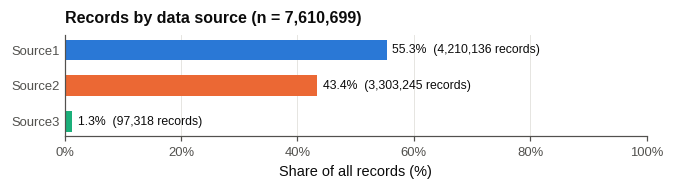

In [26]:
source_counts = df["Source"].value_counts()[SOURCES]
source_share = 100 * source_counts / n_clean
source_span = df.groupby("Source", observed=True)["Start_Time"].agg(["min", "max"])
print("Record span by source: " + "; ".join(
    f"{s} {lo.day} {lo:%b %Y} to {hi.day} {hi:%b %Y}" for s, (lo, hi) in source_span.loc[SOURCES].iterrows()) + ".")

fig, ax = plt.subplots(figsize=(6.2, 1.8))
y = np.arange(len(SOURCES))[::-1]
ax.barh(y, source_share[SOURCES], height=0.58, color=[SOURCE_COLORS[s] for s in SOURCES], zorder=2)
for yi, s in zip(y, SOURCES):
    ax.text(source_share[s] + 1, yi, f"{source_share[s]:.1f}%  ({source_counts[s]:,} records)", va="center", fontsize=8,
            color=COLORS["ink"])
ax.set_yticks(y, SOURCES)
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_xlabel("Share of all records (%)")
ax.tick_params(axis="y", length=0)
ax.grid(axis="x", zorder=0)
ax.set_title(f"Records by data source (n = {n_clean:,})")
fig.tight_layout()
save_figure(fig, "source_composition")
plt.show()

#### 2.1.2.2 State

**Question:** how geographically concentrated is the dataset?

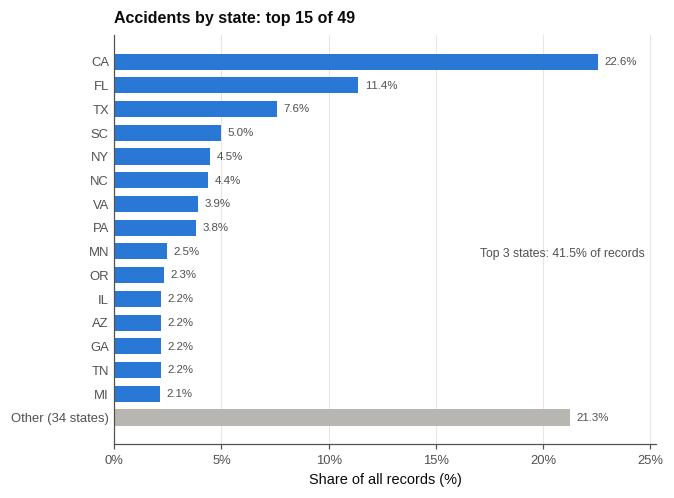

In [27]:
state_counts = CLEAN_LEVEL_COUNTS["State"]
top3_state_share = 100 * state_counts.head(3).sum() / state_counts.sum()
plot_share = 100 * top_n_with_other(state_counts, TOP_N, f"Other ({len(state_counts) - TOP_N} states)") / state_counts.sum()

fig, ax = plt.subplots(figsize=(6.2, 4.6))
y = np.arange(len(plot_share))[::-1]
ax.barh(y, plot_share.to_numpy(), color=[COLORS["primary"]] * TOP_N + [COLORS["other"]], height=0.68, zorder=2)
for yi, share in zip(y, plot_share):
    ax.text(share + 0.3, yi, f"{share:.1f}%", va="center", fontsize=7.5, color=COLORS["muted"])
ax.set_yticks(y, plot_share.index)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_xlim(0, plot_share.max() * 1.12)
ax.set_xlabel("Share of all records (%)")
ax.grid(axis="x", zorder=0)
ax.tick_params(axis="y", length=0)
ax.set_title(f"Accidents by state: top {TOP_N} of {len(state_counts)}")
ax.text(0.98, 0.45, f"Top 3 states: {top3_state_share:.1f}% of records", transform=ax.transAxes, ha="right",
        va="bottom", fontsize=8, color=COLORS["muted"])
fig.tight_layout()
save_figure(fig, "state_distribution")
plt.show()

The records are concentrated in a few states. This reflects where the providers collected data as well as where accidents happen, so frequency must not be read as risk.

#### 2.1.2.3 Weather_Condition

**Question:** which weather labels are present?

144 labels; 12 cover 95% of labelled rows; 94 each hold less than 0.01% of them.


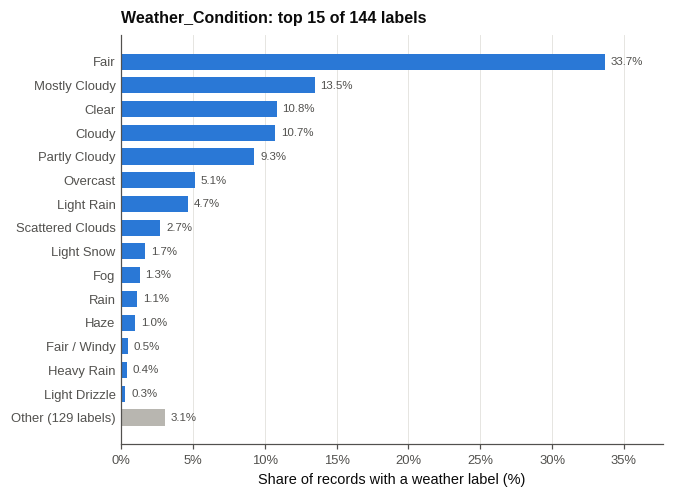

In [28]:
weather_counts = CLEAN_LEVEL_COUNTS["Weather_Condition"].copy()
weather_counts.index = weather_counts.index.astype(str)
print(f"{len(weather_counts)} labels; {int(cat.at['Weather_Condition', 'Levels covering 95% of rows'])} cover 95% of labelled rows; "
      f"{int(cat.at['Weather_Condition', 'Rare levels'])} each hold less than {RARE_LEVEL_SHARE}% of them.")

plot_share = 100 * top_n_with_other(weather_counts, TOP_N, f"Other ({len(weather_counts) - TOP_N} labels)") / weather_counts.sum()
fig, ax = plt.subplots(figsize=(6.2, 4.6))
y = np.arange(len(plot_share))[::-1]
ax.barh(y, plot_share.to_numpy(), color=[COLORS["primary"]] * TOP_N + [COLORS["other"]], height=0.68, zorder=2)
for yi, share in zip(y, plot_share):
    ax.text(share + 0.4, yi, f"{share:.1f}%", va="center", fontsize=7.5, color=COLORS["muted"])
ax.set_yticks(y, plot_share.index)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_xlim(0, plot_share.max() * 1.12)
ax.set_xlabel("Share of records with a weather label (%)")
ax.grid(axis="x", zorder=0)
ax.tick_params(axis="y", length=0)
ax.set_title(f"Weather_Condition: top {TOP_N} of {len(weather_counts)} labels")
fig.tight_layout()
save_figure(fig, "weather_condition_top_labels")
plt.show()

A few clear or cloudy labels dominate, followed by a long tail. Near-synonyms appear side by side among the most frequent labels: `Fair` and `Clear`, `Cloudy` and `Overcast`. **Question:** are they used at the same time, or did the terminology change? This is a data-collection question and is examined in Section 2.2.2.

#### 2.1.2.4 Road-feature flags

**Question:** how prevalent is each road feature in the dataset? The scale is linear, so rare flags stay visibly small; the dashed line marks the near-constant threshold of 0.5% of rows.

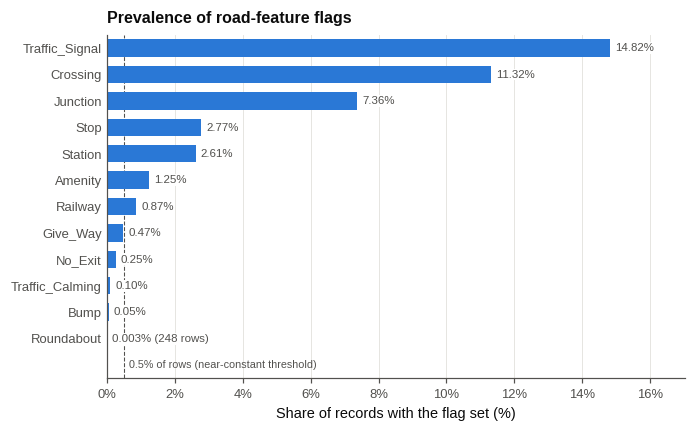

In [29]:
road_features = pd.DataFrame({"Column": BOOLEAN_FEATURES,
                              "Rows with flag": [int(CLEAN_LEVEL_COUNTS[c].get(True, 0)) for c in BOOLEAN_FEATURES]})
road_features["Share (%)"] = 100 * road_features["Rows with flag"] / n_clean
road_features = road_features.sort_values("Share (%)").reset_index(drop=True)  # most prevalent at the top
near_constant_pct = 100 - NEAR_CONSTANT_SHARE

fig, ax = plt.subplots(figsize=(6.4, 4.0))
y = np.arange(len(road_features))
ax.barh(y, road_features["Share (%)"], color=COLORS["primary"], height=0.66, zorder=2)
for yi, (n, share) in enumerate(zip(road_features["Rows with flag"], road_features["Share (%)"])):
    ax.text(share + 0.15, yi, f"{share:.2f}%" if share >= 0.01 else f"{share:.3f}% ({n:,} rows)", va="center", fontsize=7.5,
            color=COLORS["muted"], zorder=4, bbox={"facecolor": "white", "edgecolor": "none", "pad": 0.6})
ax.axvline(near_constant_pct, color=COLORS["muted"], linestyle="--", linewidth=0.7, zorder=1)
ax.text(near_constant_pct + 0.15, -1.0, "0.5% of rows (near-constant threshold)", ha="left", va="center", fontsize=7,
        color=COLORS["muted"])
ax.set_ylim(-1.5, len(road_features) - 0.5)
ax.set_yticks(y, road_features["Column"])
ax.set_xlim(0, road_features["Share (%)"].max() * 1.15)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_xlabel("Share of records with the flag set (%)")
ax.grid(axis="x", zorder=0)
ax.tick_params(axis="y", length=0)
ax.set_title("Prevalence of road-feature flags")
fig.tight_layout()
save_figure(fig, "road_feature_prevalence")
plt.show()

Seven flags occur in more than 0.5% of accidents. The other five are near-constant, but even the rarest still has hundreds of rows. Rarity alone does not make a flag useless, so the comparison with `Severity` decides.

The remaining categorical columns are summarised in the table above: `Timezone` and `Wind_Direction` (low cardinality) and the four daylight columns (binary). None of them is near-constant. The daylight columns are derived from the same time and location, so their redundancy is a multivariate question (Sections 2.3.3.4 and 2.4.2).

### 2.1.3 Numeric features: first look

In [30]:
NUMERIC_FEATURES = COORDINATE_COLS + MEASUREMENT_COLS
df[NUMERIC_FEATURES].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Start_Lat,7610699.0,36.19,5.07,24.55,33.39,35.82,40.08,49.00
Start_Lng,7610699.0,-94.72,17.38,-124.62,-117.22,-87.80,-80.37,-67.11
End_Lat,4210136.0,36.25,5.28,24.57,33.46,36.17,40.16,49.08
End_Lng,4210136.0,-95.78,18.11,-124.55,-117.78,-88.05,-80.26,-67.11
Distance(mi),7610699.0,0.56,1.78,0.00,0.00,0.03,0.46,441.75
Temperature(F),7450593.0,61.72,19.02,-89.00,49.00,64.00,76.00,207.00
Wind_Chill(F),5620682.0,58.30,22.42,-89.00,43.00,62.00,75.00,207.00
Humidity(%),7440578.0,64.81,22.81,1.00,48.00,67.00,84.00,100.00
Pressure(in),7473253.0,29.54,1.00,0.02,29.37,29.86,30.03,58.63
Visibility(mi),7437464.0,9.09,2.69,0.00,10.00,10.00,10.00,140.00


**Question:** what does the bulk of each measurement look like on its natural scale? Section 1.3.7 showed the full range, including the extremes. Here each x-axis spans the 0.1st to the 99.9th percentile so that the shape of the bulk is visible. The scale itself is not transformed.

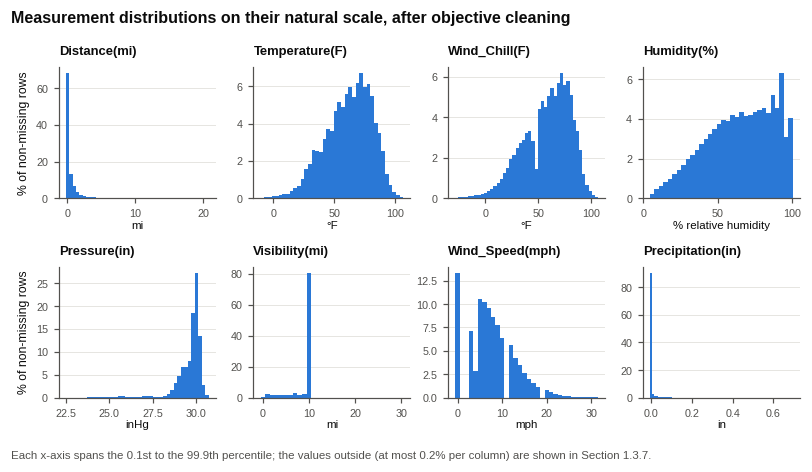

In [31]:
BIN_WIDTH = {"Distance(mi)": 0.5, "Temperature(F)": 3, "Wind_Chill(F)": 3, "Humidity(%)": 3, "Pressure(in)": 0.2,
             "Visibility(mi)": 1, "Wind_Speed(mph)": 1, "Precipitation(in)": 0.01}  # bins centred on reported values
fig, axes = plt.subplots(2, 4, figsize=(7.4, 4.2))
for ax, c in zip(axes.flat, MEASUREMENT_COLS):
    values = df[c].dropna().to_numpy(dtype="float64")
    lo, hi = np.quantile(values, [0.001, 0.999])
    w = BIN_WIDTH[c]
    edges = np.arange(np.floor(lo / w) * w - w / 2, hi + w, w)
    hist, _ = np.histogram(values, bins=edges)
    ax.bar(edges[:-1], 100 * hist / len(values), width=w, align="edge", color=COLORS["primary"], linewidth=0, zorder=2)
    ax.set_title(c, fontsize=8.5)
    ax.set_xlabel(MEASUREMENT_UNITS[c], fontsize=7.5, labelpad=1)
    ax.tick_params(labelsize=7)
    ax.grid(axis="y", zorder=0)
for ax in axes[:, 0]:
    ax.set_ylabel("% of non-missing rows", fontsize=8)
fig.suptitle("Measurement distributions on their natural scale, after objective cleaning", x=0.01, ha="left", fontsize=10.5,
             fontweight="semibold")
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.text(0.01, 0.005, "Each x-axis spans the 0.1st to the 99.9th percentile; the values outside (at most 0.2% per column) are "
         "shown in Section 1.3.7.", fontsize=7.5, color=COLORS["muted"], ha="left", va="bottom")
save_figure(fig, "numeric_distributions_natural_scale")
plt.show()

`Temperature(F)`, `Wind_Chill(F)` and `Humidity(%)` have a readable, moderately skewed bulk. `Pressure(in)` has a long lower tail. `Distance(mi)`, `Precipitation(in)`, `Visibility(mi)` and `Wind_Speed(mph)` are dominated by a single value: zero, or 10 miles for visibility. **Question:** how large are these point masses, and how discrete are the measurements?

In [32]:
rows = []
for c in NUMERIC_FEATURES:
    values = df[c].astype("float64")
    counts = values.value_counts()
    n_non_missing = int(values.count())
    rows.append({"Column": c, "Count": n_non_missing, "Missing (%)": pct(n_clean - n_non_missing, n_clean),
                 **distribution_summary(values), "Mean": values.mean(), "Std": values.std(), "Skewness": values.skew(),
                 "Distinct values": len(counts), "Mode": counts.index[0],
                 "Mode share (%)": pct(int(counts.iloc[0]), n_non_missing)})
numeric_landscape = pd.DataFrame(rows)
save_table(numeric_landscape, "numeric_landscape")
num = numeric_landscape.set_index("Column")
show_table(numeric_landscape.loc[numeric_landscape["Column"].isin(MEASUREMENT_COLS),
                                 ["Column", "Missing (%)", "Zero (%)", "Mode", "Mode share (%)", "Distinct values", "P99", "Max"]],
           caption="Point masses and discreteness of the measurements after objective cleaning (full statistics in "
                   "tables/numeric_landscape.csv)")

Column,Missing (%),Zero (%),Mode,Mode share (%),Distinct values,P99,Max
Distance(mi),0.00,43.19,0.00,43.19,"20,674",6.95,441.75
Temperature(F),2.10,0.04,77.00,2.27,860,96.00,207.00
Wind_Chill(F),26.15,0.07,73.00,2.34,"1,001",96.00,207.00
Humidity(%),2.24,0.00,93.00,3.83,100,100.00,100.00
Pressure(in),1.81,0.00,29.96,1.63,"1,143",30.44,58.63
Visibility(mi),2.28,0.10,10.00,80.40,92,10.00,140.00
Wind_Speed(mph),7.44,13.33,0.00,13.33,184,23.00,"1,087.00"
Precipitation(in),28.81,90.30,0.00,90.30,299,0.18,36.47


- `Distance(mi)` is exactly zero for 43% of rows and has a long right tail. It is also a leakage candidate (Section 1.3.8).
- `Precipitation(in)` is zero for 90% of observed rows, so most of its variation is whether it rained.
- `Visibility(mi)` has a point mass at 10 miles (80% of readings) and few distinct values, consistent with a reporting cap.
- `Wind_Speed(mph)` has a spike at zero (calm) and few distinct values, which pile up on particular speeds.
- `Pressure(in)` has a long lower tail, consistent with station pressure at high elevation.

These are descriptions, not treatments. The decisions so far fall into two kinds:

| Decision type | Examples | Status |
|---|---|---|
| Model-independent (objective cleaning, dataset B) | Duplicates removed, timestamps parsed, labels and whitespace normalized, constant columns dropped, definitionally invalid values set to missing | Applied in Section 1.4 |
| Model-dependent (model-ready representation, C) | Transforming skewed or zero-inflated measurements, scaling, clipping or winsorizing extremes, imputation, encoding, rare-category grouping | Deferred to Part 3 and the training pipeline: the right choice depends on the model. Scaling matters for linear and distance-based models but not for tree-based models, which are also less sensitive to extreme values |

### 2.1.4 Start_Time coverage

**Question:** what period does the dataset actually cover, and how does the number of records vary over it? Months are used only to aggregate records and are not added to `df`.

Start_Time range: 2016-01-14 20:18:33 to 2023-03-31 23:30:00; 87 calendar months, 0 without records
Lowest monthly volumes after the first year: Mar 2023 (30,143), Jul 2020 (35,203), Aug 2020 (37,283)


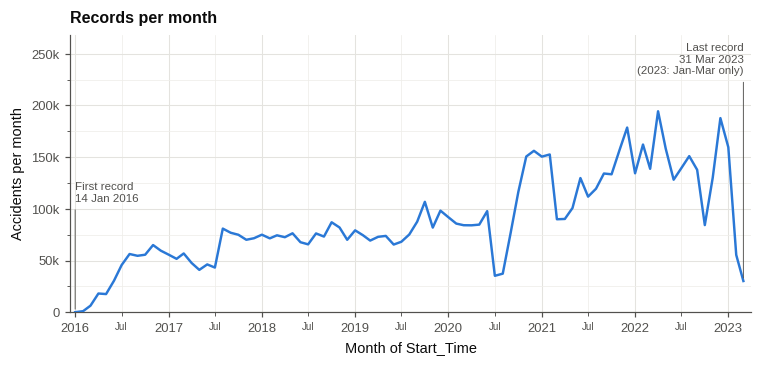

In [33]:
start_month = df["Start_Time"].dt.to_period("M")  # aggregation key only
all_months = pd.period_range(start_month.min(), start_month.max(), freq="M")
MONTH_AXIS_LIMITS = (all_months[0].start_time - pd.Timedelta(days=20), (all_months[-1] + 1).start_time)  # every monthly figure
records_by_month = start_month.value_counts().reindex(all_months, fill_value=0)
first_record, last_record = df["Start_Time"].min(), df["Start_Time"].max()
lowest_months = records_by_month[records_by_month.index.year > first_record.year].nsmallest(3)
print(f"Start_Time range: {first_record} to {last_record}; {len(all_months)} calendar months, "
      f"{int((records_by_month == 0).sum())} without records")
print("Lowest monthly volumes after the first year: "
      + ", ".join(f"{m.strftime('%b %Y')} ({n:,})" for m, n in lowest_months.items()))

fig, ax = plt.subplots(figsize=(7.0, 3.4))
x = records_by_month.index.to_timestamp()
ax.plot(x, records_by_month.to_numpy(), color=COLORS["primary"], linewidth=1.6, zorder=3)
ax.set_ylim(0, records_by_month.max() * 1.38)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v / 1e3:g}k" if v else "0"))
ax.annotate(f"First record\n{first_record:%d %b %Y}", xy=(x[0], records_by_month.iloc[0]), xytext=(x[0], records_by_month.max() * 0.55),
            fontsize=7.5, color=COLORS["muted"], ha="left",
            arrowprops={"arrowstyle": "-", "color": COLORS["muted"], "linewidth": 0.6, "relpos": (0, 0)})
ax.annotate(f"Last record\n{last_record:%d %b %Y}\n(2023: Jan-{last_record:%b} only)", xy=(x[-1], records_by_month.iloc[-1]),
            xytext=(x[-1], records_by_month.max() * 1.34), fontsize=7.5, color=COLORS["muted"], ha="right", va="top",
            arrowprops={"arrowstyle": "-", "color": COLORS["muted"], "linewidth": 0.6, "relpos": (1, 0)})
ax.set_xlim(*MONTH_AXIS_LIMITS)
month_axis(ax)
value_grid(ax, "y")
ax.yaxis.set_minor_locator(mticker.AutoMinorLocator(2))
ax.set_ylabel("Accidents per month")
ax.set_xlabel("Month of Start_Time")
ax.set_title("Records per month")
fig.tight_layout()
save_figure(fig, "records_by_month")
plt.show()

The first record is from 14 January 2016, just before the documented February 2016 start, and the last from 31 March 2023, so 2023 contains only January to March. Every calendar month in between has records. Monthly volume grows over the period but not smoothly: it falls sharply in July–August 2020 and again in early 2023, and March 2023 has the fewest records of any month after 2016. Record volume reflects collection as well as accidents, so the provider mix behind these counts is examined next.

## 2.2 Data-Collection and Source Effects

**Question:** are the observed patterns properties of accidents, or artifacts of how the dataset was collected? The dataset combines three providers and several years of changing collection. Before any pattern is related to `Severity`, it is checked here against the provider and the collection period.

### 2.2.1 Source mix over time

Last month with records: Source1 Mar 2023; Source2 Sep 2022; Source3 Sep 2022
Lowest Source1 shares: Jul 2020 0.5%, Aug 2020 1.3%


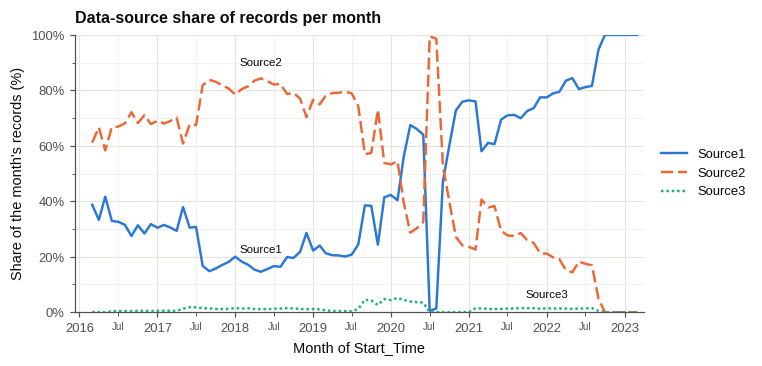

In [34]:
MIN_MONTH_ROWS = 1_000  # months with fewer records are left out of monthly shares
source_by_month = pd.crosstab(start_month, df["Source"])[SOURCES]
month_totals = source_by_month.sum(axis=1)
source_share_by_month = (100 * source_by_month.div(month_totals, axis=0))[month_totals >= MIN_MONTH_ROWS]
source_share_by_year = pd.crosstab(df["Start_Time"].dt.year, df["Source"], normalize="index")[SOURCES] * 100  # used in the transition at the end of Section 2.2
print("Last month with records: " + "; ".join(
    f"{s} {source_by_month.index[source_by_month[s] > 0].max().strftime('%b %Y')}" for s in SOURCES))
print("Lowest Source1 shares: " + ", ".join(
    f"{m.strftime('%b %Y')} {v:.1f}%" for m, v in source_share_by_month["Source1"].nsmallest(2).items()))

fig, ax = plt.subplots(figsize=(7.0, 3.4))
x = source_share_by_month.index.to_timestamp()
for s in SOURCES:
    ax.plot(x, source_share_by_month[s], color=SOURCE_COLORS[s], linestyle=SOURCE_LINESTYLES[s], linewidth=1.6, label=s,
            zorder=3)
LABEL_SPOTS = {"Source1": ("2018-05", 6, "bottom"), "Source2": ("2018-05", 4, "bottom"), "Source3": ("2022-01", 3, "bottom")}
for s, (month_label, offset, va) in LABEL_SPOTS.items():  # direct labels where each line has free space
    m = pd.Period(month_label, freq="M")
    ax.text(m.to_timestamp(), source_share_by_month.at[m, s] + offset, s, fontsize=7.5, color=COLORS["ink"], va=va, ha="center")
ax.set_ylim(0, 100)
ax.yaxis.set_major_locator(mticker.MultipleLocator(20))
ax.yaxis.set_minor_locator(mticker.MultipleLocator(10))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
value_grid(ax, "y")
month_axis(ax)
ax.set_xlim(*MONTH_AXIS_LIMITS)
ax.set_ylabel("Share of the month's records (%)")
ax.set_xlabel("Month of Start_Time")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
ax.set_title("Data-source share of records per month")
fig.tight_layout()
save_figure(fig, "source_share_by_month")
plt.show()

Source2 supplies most records until early 2020 and Source1 afterwards. Source2 and Source3 end in September 2022, so the final months come from Source1 alone. In July and August 2020 Source1 almost disappears, which explains the dip in monthly volume in Section 2.1.4. A comparison across sources is therefore also a comparison across periods, and vice versa.

### 2.2.2 Did the weather terminology change over time?

Section 2.1.2.3 found near-synonymous weather labels side by side. For three candidate pairs, the table compares the last month before the change with the first month after it. The change month is read from the data as the first month in which none of the earlier labels occurs; months with fewer than 1,000 labelled records are skipped.

In [35]:
LABEL_PAIRS = [("Clear", "Fair"), ("Overcast", "Cloudy"), ("Thunderstorm", "T-Storm")]
label_by_month = pd.crosstab(start_month, df["Weather_Condition"])
labelled_rows = label_by_month.sum(axis=1)

# The change month is read from the data: the first month in which none of the earlier labels occurs
earlier_labels = [a for a, _ in LABEL_PAIRS] + ["Scattered Clouds"]
earlier_present = (label_by_month[earlier_labels].sum(axis=1) > 0)[labelled_rows >= MIN_MONTH_ROWS]
WEATHER_FEED_CHANGE = earlier_present[~earlier_present].index.min().to_timestamp()
assert earlier_present[earlier_present.index >= WEATHER_FEED_CHANGE.to_period("M")].sum() == 0, "Earlier labels reappear"
PERIODS = [f"Before {WEATHER_FEED_CHANGE:%B %Y}", f"From {WEATHER_FEED_CHANGE:%B %Y}"]
print(f"First month without any of the earlier labels: {WEATHER_FEED_CHANGE:%B %Y}")

First month without any of the earlier labels: April 2019


In [36]:
after_month = WEATHER_FEED_CHANGE.to_period("M")
before_month = after_month - 1
before_label, after_label = before_month.strftime("%b %Y"), after_month.strftime("%b %Y")


def month_share(label, m):
    return 100 * label_by_month.at[m, label] / labelled_rows[m]


rows = []
for earlier, later in LABEL_PAIRS + [("Scattered Clouds", None)]:
    rows.append({
        "Earlier label": earlier, "Later label": later or "(none identified)",
        f"Earlier label share, {before_label} → {after_label}": f"{month_share(earlier, before_month):.2f}% → {month_share(earlier, after_month):.2f}%",
        f"Later label share, {before_label} → {after_label}": (f"{month_share(later, before_month):.2f}% → {month_share(later, after_month):.2f}%"
                                                              if later else ""),
        f"Rows with the earlier label from {after_label}": int(label_by_month.loc[label_by_month.index >= after_month, earlier].sum()),
        "Status": "Candidate equivalent terminology; not merged" if later else "Discontinued; not merged"})
weather_label_candidates = pd.DataFrame(rows)
show_table(weather_label_candidates, caption="Candidate equivalent Weather_Condition labels around the change "
           "(share of labelled accidents in the month)", name="weather_label_candidates")

# Does the change affect every provider? Share of labelled rows per source, before and after the change
label_by_source_period = pd.crosstab([df["Source"], df["Start_Time"] < WEATHER_FEED_CHANGE], df["Weather_Condition"],
                                     normalize="index") * 100
for earlier, later in LABEL_PAIRS[:2]:
    print(f"{earlier} / {later}, share of labelled rows before -> from {WEATHER_FEED_CHANGE:%B %Y}: " + "; ".join(
        f"{s} {label_by_source_period.at[(s, True), earlier]:.1f}% -> {label_by_source_period.at[(s, False), earlier]:.1f}% / "
        f"{label_by_source_period.at[(s, True), later]:.1f}% -> {label_by_source_period.at[(s, False), later]:.1f}%"
        for s in SOURCES))
del label_by_source_period

# Labels used almost only in one period (at least 99% of a label's rows)
before_change = (df["Start_Time"] < WEATHER_FEED_CHANGE).to_numpy()
weather_before = df.loc[before_change, "Weather_Condition"].value_counts()
weather_before.index = weather_before.index.astype(str)
share_before = weather_before.reindex(weather_counts.index, fill_value=0) / weather_counts
period_of_use = pd.Series(np.select([share_before >= 0.99, share_before <= 0.01], PERIODS, "Both periods"),
                          index=weather_counts.index)
weather_period_summary = (pd.DataFrame({"Period of use": period_of_use, "Rows": weather_counts}).groupby("Period of use")["Rows"]
                          .agg(["size", "sum"]).rename(columns={"size": "Labels", "sum": "Rows"}).reset_index())
weather_period_summary["Share of labelled rows (%)"] = 100 * weather_period_summary["Rows"] / weather_counts.sum()
print("Labels by period of use: " + "; ".join(f"{r['Period of use']}: {r['Labels']} labels "
      f"({r['Share of labelled rows (%)']:.1f}% of labelled rows)" for _, r in weather_period_summary.iterrows()))

Earlier label,Later label,"Earlier label share, Mar 2019 → Apr 2019","Later label share, Mar 2019 → Apr 2019",Rows with the earlier label from Apr 2019,Status
Clear,Fair,35.59% → 0.00%,0.36% → 38.96%,0,Candidate equivalent terminology; not merged
Overcast,Cloudy,20.26% → 0.00%,0.27% → 20.30%,0,Candidate equivalent terminology; not merged
Thunderstorm,T-Storm,0.04% → 0.00%,0.01% → 0.46%,0,Candidate equivalent terminology; not merged
Scattered Clouds,(none identified),7.70% → 0.00%,,0,Discontinued; not merged


Clear / Fair, share of labelled rows before -> from April 2019: Source1 35.8% -> 0.0% / 0.5% -> 48.5%; Source2 37.2% -> 0.0% / 0.4% -> 45.3%; Source3 37.9% -> 0.0% / 0.3% -> 51.4%
Overcast / Cloudy, share of labelled rows before -> from April 2019: Source1 17.5% -> 0.0% / 0.3% -> 14.7%; Source2 17.5% -> 0.0% / 0.1% -> 16.2%; Source3 16.3% -> 0.0% / 0.1% -> 14.4%
Labels by period of use: Before April 2019: 31 labels (18.9% of labelled rows); Both periods: 35 labels (34.0% of labelled rows); From April 2019: 78 labels (47.0% of labelled rows)


The switch is abrupt: in each pair the earlier label stops completely in the same month, and its candidate replacement takes over a similar share. The synchronized transition across providers is consistent with an upstream change in weather terminology or data processing, rather than a genuine shift in weather conditions. The raw label therefore partly encodes the collection period. The pairs are treated as **candidate equivalent terminology**. Their relationship with `Severity` is examined in Section 2.3.3.2, and Section 2.6 draws the preparation implication.

### 2.2.3 Is missingness caused by the provider or by the collection period?

Section 1.3.5 showed that the end coordinates, `Precipitation(in)`, `Wind_Chill(F)` and `Wind_Speed(mph)` have the highest missing rates. These values are still missing in the analysis dataset. They are left unresolved on purpose: imputing them, adding missing-value indicators or dropping a field is a model-dependent decision that should follow an understanding of why the values are missing. The end coordinates and the weather fields are examined separately, because their missingness may have different causes.

**End coordinates.** Are they recorded by some providers only, and does that hold in every year?

In [37]:
assert (df["End_Lat"].isna() == df["End_Lng"].isna()).all(), "End_Lat and End_Lng are not missing on the same rows"
end_recorded = df["End_Lat"].notna()
end_by_source_year = end_recorded.groupby([df["Source"], df["Start_Time"].dt.year], observed=True).mean().unstack() * 100
end_coordinates = pd.DataFrame({
    "Source": SOURCES, "Rows": df["Source"].value_counts()[SOURCES].to_numpy(),
    "End coordinates recorded (%)": 100 * end_recorded.groupby(df["Source"], observed=True).mean()[SOURCES].to_numpy(),
    "Lowest yearly share (%)": end_by_source_year.min(axis=1)[SOURCES].to_numpy(),
    "Highest yearly share (%)": end_by_source_year.max(axis=1)[SOURCES].to_numpy()})
show_table(end_coordinates, caption="End_Lat and End_Lng recorded, by data source", precision=1)
del end_recorded

Source,Rows,End coordinates recorded (%),Lowest yearly share (%),Highest yearly share (%)
Source1,"4,210,136",100.0,100.0,100.0
Source2,"3,303,245",0.0,0.0,0.0
Source3,"97,318",0.0,0.0,0.0


**Weather fields.** How does their missing rate evolve month by month? `Temperature(F)` is added as a reference for the other weather fields. The month of any break is read from the data as each field's largest month-to-month drop in missing rate.

Wind_Chill(F): largest month-to-month drop, 67.3% (Mar 2019) to 1.8% (Apr 2019)
Precipitation(in): largest month-to-month drop, 87.1% (Mar 2019) to 3.7% (Apr 2019)
Wind_Speed(mph): largest month-to-month drop, 18.0% (Mar 2019) to 1.6% (Apr 2019)
The break coincides with the weather-terminology change in Section 2.2.2: True


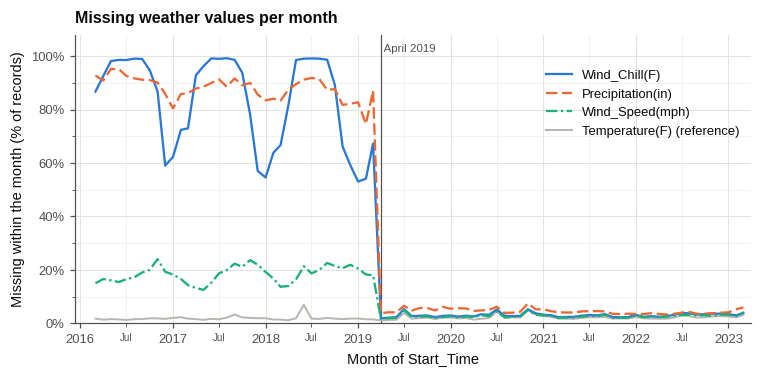

In [38]:
MISSING_OVER_TIME = ["Wind_Chill(F)", "Precipitation(in)", "Wind_Speed(mph)"]
REFERENCE_FIELD = "Temperature(F)"
monthly_missing = df[MISSING_OVER_TIME + [REFERENCE_FIELD]].isna().groupby(start_month).mean() * 100
monthly_missing = monthly_missing[records_by_month.reindex(monthly_missing.index).to_numpy() >= MIN_MONTH_ROWS]

largest_drop = monthly_missing[MISSING_OVER_TIME].diff().idxmin()  # month of each field's largest fall in missing rate
for c, m in largest_drop.items():
    previous = monthly_missing.index[monthly_missing.index.get_loc(m) - 1]
    print(f"{c}: largest month-to-month drop, {monthly_missing.at[previous, c]:.1f}% ({previous.strftime('%b %Y')}) "
          f"to {monthly_missing.at[m, c]:.1f}% ({m.strftime('%b %Y')})")
assert largest_drop.nunique() == 1, "The fields do not break in the same month"
MISSINGNESS_BREAK = largest_drop.iloc[0].to_timestamp()
print(f"The break coincides with the weather-terminology change in Section 2.2.2: {MISSINGNESS_BREAK == WEATHER_FEED_CHANGE}")

fig, ax = plt.subplots(figsize=(7.0, 3.5))
x = monthly_missing.index.to_timestamp()
FIELD_LINESTYLES = ["-", (0, (5, 2)), (0, (5, 1.5, 1, 1.5))]  # colour and line style, for grayscale print
for i, c in enumerate(MISSING_OVER_TIME):
    ax.plot(x, monthly_missing[c], color=SERIES_COLORS[i], linestyle=FIELD_LINESTYLES[i], linewidth=1.5, label=c, zorder=3)
ax.plot(x, monthly_missing[REFERENCE_FIELD], color=COLORS["other"], linewidth=1.3, label=f"{REFERENCE_FIELD} (reference)", zorder=2)
ax.axvline(MISSINGNESS_BREAK, color=COLORS["muted"], linewidth=0.8, zorder=1)
ax.text(MISSINGNESS_BREAK, 101, f" {MISSINGNESS_BREAK:%B %Y}", fontsize=7.5, color=COLORS["muted"], ha="left", va="bottom")
ax.set_ylim(0, 108)
ax.yaxis.set_major_locator(mticker.MultipleLocator(20))
ax.yaxis.set_minor_locator(mticker.MultipleLocator(10))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
value_grid(ax, "y")
month_axis(ax)
ax.set_xlim(*MONTH_AXIS_LIMITS)
ax.set_ylabel("Missing within the month (% of records)")
ax.set_xlabel("Month of Start_Time")
ax.legend(loc="upper right", bbox_to_anchor=(1.0, 0.92))
ax.set_title("Missing weather values per month")
fig.tight_layout()
save_figure(fig, "weather_missingness_by_month")
plt.show()

**Provider or period?** With the break located, each provider's missing rates can be compared within each period. The remaining weather gaps are then checked against the matched weather observation.

In [39]:
MISSINGNESS_PERIODS = [f"Before {MISSINGNESS_BREAK:%B %Y}", f"From {MISSINGNESS_BREAK:%B %Y}"]
period = pd.Series(pd.Categorical.from_codes((df["Start_Time"] >= MISSINGNESS_BREAK).astype(np.int8).to_numpy(),
                                             categories=MISSINGNESS_PERIODS), index=df.index, name="Period")
groups = [period, df["Source"]]
missing_by_period_source = df[MISSING_OVER_TIME].isna().groupby(groups, observed=True).mean() * 100
missing_by_period_source.columns = [f"{c} missing (%)" for c in MISSING_OVER_TIME]
missing_by_period_source.insert(0, "Rows", df.groupby(groups, observed=True).size())
show_table(missing_by_period_source.reset_index(), caption="Missing weather values by period and data source",
           precision=1, name="missing_by_period_source")
del period, groups

# Other weather gaps: do they fall on rows without any matched weather observation?
missing_cols = clean_audit.loc[clean_audit["Missing"] > 0, "Column"].tolist()
missing_flags = df[missing_cols].isna()
weather_time_missing = missing_flags["Weather_Timestamp"].to_numpy()
WEATHER_FIELDS = ["Temperature(F)", "Humidity(%)", "Pressure(in)", "Visibility(mi)", "Wind_Direction", "Weather_Condition"]
overlap = pd.Series({c: pct((missing_flags[c].to_numpy() & weather_time_missing).sum(), missing_flags[c].sum())
                     for c in WEATHER_FIELDS})
DAYLIGHT_COLS = COLUMN_GROUPS["Daylight"]
daylight_jointly_missing = bool(missing_flags[DAYLIGHT_COLS].sum(axis=1).isin([0, len(DAYLIGHT_COLS)]).all())
print(f"Other weather fields: {overlap.min():.1f}% to {overlap.max():.1f}% of their missing values fall on rows "
      f"without a matched weather observation.")
print(f"The four daylight columns are missing on exactly the same rows: {daylight_jointly_missing} "
      f"({int(missing_flags[DAYLIGHT_COLS[0]].sum()):,} rows)")
del missing_flags, weather_time_missing, start_month

Period,Source,Rows,Wind_Chill(F) missing (%),Precipitation(in) missing (%),Wind_Speed(mph) missing (%)
Before April 2019,Source1,"514,485",79.3,86.3,18.2
Before April 2019,Source2,"1,703,164",82.3,87.7,19.1
Before April 2019,Source3,"22,852",84.3,88.7,19.0
From April 2019,Source1,"3,695,651",3.3,4.6,3.0
From April 2019,Source2,"1,600,081",2.3,3.7,2.0
From April 2019,Source3,"74,466",2.9,7.1,2.6


Other weather fields: 67.7% to 85.3% of their missing values fall on rows without a matched weather observation.
The four daylight columns are missing on exactly the same rows: True (22,725 rows)


- **End coordinates** are recorded for every Source1 record and for no Source2 or Source3 record, in every year. This missingness is **determined by the provider**.
- **Wind chill, precipitation and wind speed** each have their largest month-to-month drop in missing rate in the same month, which coincides with the weather-terminology change (Section 2.2.2). Within each period, the rates are similar for every provider. This missingness is **driven by the collection period**, and the source differences in the overall rates come mainly from each provider's mix of periods. Before the break, wind chill is missing far more often in summer than in winter, consistent with wind chill being reported mainly in cold weather.
- **Other weather fields** stay at a few percent throughout, and most of their gaps fall on rows without a matched weather observation. They are a **row-level gap**, not independent gaps in each field.

### 2.2.4 Do providers record measurements differently?

**Question:** do Source1, Source2 and Source3 appear to record the same accident attributes using the same conventions? The question is not which source is better, and not which source predicts `Severity`.

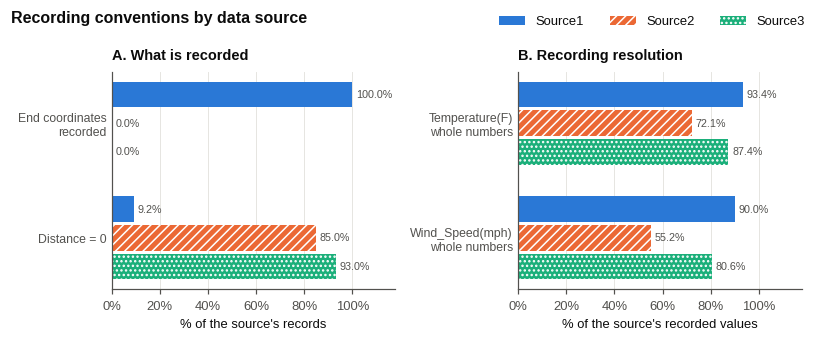

In [40]:
def whole_number_share(column):
    """Share of recorded values that are whole numbers, by data source."""
    observed = df[column].notna()
    values = df.loc[observed, column]
    return (values == np.round(values)).groupby(df.loc[observed, "Source"], observed=True).mean()


recording = pd.DataFrame({
    "End coordinates\nrecorded": df["End_Lat"].notna().groupby(df["Source"], observed=True).mean(),
    "Distance = 0": (df["Distance(mi)"] == 0).groupby(df["Source"], observed=True).mean(),
    "Temperature(F)\nwhole numbers": whole_number_share("Temperature(F)"),
    "Wind_Speed(mph)\nwhole numbers": whole_number_share("Wind_Speed(mph)"),
}).loc[SOURCES] * 100
PANELS = {"A. What is recorded": list(recording.columns[:2]), "B. Recording resolution": list(recording.columns[2:])}

fig, axes = plt.subplots(1, 2, figsize=(7.4, 3.1))
bar_height = 0.25
for ax, (title, metrics) in zip(axes, PANELS.items()):
    y = np.arange(len(metrics))[::-1].astype(float)
    for i, s in enumerate(SOURCES):
        positions = y + (1 - i) * bar_height  # Source1 at the top of each group
        values = recording.loc[s, metrics].to_numpy()
        ax.barh(positions, values, height=bar_height * 0.9, color=SOURCE_COLORS[s], hatch=SOURCE_HATCHES[s], edgecolor="white",
                linewidth=0, label=s, zorder=2)
        for p, v in zip(positions, values):
            ax.text(v + 1.5, p, f"{v:.1f}%", va="center", fontsize=7, color=COLORS["muted"])
    ax.set_yticks(y, metrics, fontsize=8)
    ax.set_xlim(0, 118)
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
    ax.grid(axis="x", zorder=0)
    ax.tick_params(axis="y", length=0)
    ax.set_title(title, fontsize=9.5)
    ax.set_xlabel("% of the source's records" if title.startswith("A") else "% of the source's recorded values", fontsize=8.5)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=3, bbox_to_anchor=(1.0, 1.0))
fig.suptitle("Recording conventions by data source", x=0.01, ha="left", fontsize=10.5, fontweight="semibold")
fig.tight_layout()
save_figure(fig, "source_recording_conventions")
plt.show()

Providers differ in what they record (end-coordinate availability, the prevalence of zero distances) and in measurement granularity (whole-number shares). The differences are consistent with source-specific upstream recording or preprocessing conventions; the data do not show which mechanism produces them. They matter for the bivariate analysis: an apparent `Distance(mi)` → `Severity` relationship could partly reflect Source → recording convention → `Distance(mi)` rather than a property of the accident. This figure is a diagnostic for later comparisons, not evidence about Severity.

### 2.2.5 Summary: collection artifacts to control for

| Pattern | Artifact of | Consequence for the bivariate analysis |
|---|---|---|
| Provider mix changes over time; Source1 almost absent in July–August 2020 | Source and period | Compare `Severity` by source within each period; do not read record volume as accident frequency |
| Weather labels change in April 2019 | Period | Harmonize candidate labels before comparing weather with `Severity` |
| End coordinates and zero distances | Source | Treat as leakage candidates; check within Source |
| Wind chill, precipitation and wind speed missingness | Period | Compare missingness with `Severity` within each period |
| Whole-number shares differ | Source | Interpret small numeric differences with care |

Association with `Source` for every categorical column (Cramér's V) is exported in `tables/categorical_landscape.csv` as supporting evidence. It is highest for `Weather_Condition`, `State` and `Traffic_Signal`.

**Questions carried into the bivariate analysis.** The collection effects above determine how Section 2.3 compares features with `Severity`:

- Which features separate the minority levels, given that Severity 2 makes up 79.5% of the records (Section 2.1.1)?
- Does the Severity distribution differ by provider and period, and why (Sections 2.2.1 and 2.2.2)?
- Do the candidate equivalent weather labels relate to Severity alike (Section 2.2.2)?
- Is weather missingness related to Severity within each period (Section 2.2.3)?
- How strongly do the leakage candidates move with Severity within each provider (Sections 1.3.8 and 2.2.4)?
- Do the weather measurements and the retained extremes differ across levels (Sections 1.3.7 and 2.1.3)?
- Which road contexts, daylight indicators and states separate the levels within each provider (Section 2.1.2)?

## 2.3 Bivariate EDA: Relationships with Severity

**Question:** how does each candidate feature relate to the four Severity levels, and can these relationships be read the same way across data sources and collection periods?

- **2.3.1** describes how the Severity distribution differs by source and changes over time.
- **2.3.2** examines competing explanations for those shifts.
- **2.3.3** relates the other features to all four levels, for all records, with Source1 and Source2 as a diagnostic.
- **2.3.4** summarizes the associations and the questions for the multivariate analysis (Section 2.4).

**Conventions.** All analyses use the analysis dataset (Section 1.5); missing values stay missing. A share is the percentage of a group's records at one level, P(Severity = k | group): the group's records are the denominator, and the group's number of records is shown with it. Groups with fewer than 1,000 records are left out or marked. With 7.6 million rows almost any difference is statistically significant, so Cramér's V (0 = no association) describes strength, and no association is read as a causal effect. Analysis keys such as hour, road class or missing indicators are computed for this section only and are never added to `df`.

In [41]:
SEVERITY_LEVELS = [1, 2, 3, 4]
severity = df[TARGET].astype("int8")
sev_values = severity.to_numpy()
sev_by_position = pd.Series(sev_values)  # positional twin of `severity` (df keeps its original row labels)
overall_mix = severity.value_counts(normalize=True).reindex(SEVERITY_LEVELS) * 100
start_time = df["Start_Time"]
month_key = start_time.dt.to_period("M")  # analysis-only keys: never added to df
MIN_GROUP_ROWS = 1_000  # a monthly or subgroup share needs at least this many records
MAIN_SOURCES = ["Source1", "Source2"]  # Source3 (1.3% of records) is too small for stratified displays
is_source = {s: df["Source"].eq(s).to_numpy() for s in SOURCES}
everything = np.ones(n_clean, dtype=bool)
POPULATIONS = {"All records": everything, **{s: is_source[s] for s in MAIN_SOURCES}}


def severity_counts(key, mask=None):
    """Records at each Severity level for every value of `key` (a column or an array aligned with df by position),
    optionally within a boolean row mask."""
    key = key.reset_index(drop=True) if isinstance(key, pd.Series) else pd.Series(key)
    if mask is None:
        return pd.crosstab(key, sev_by_position).reindex(columns=SEVERITY_LEVELS, fill_value=0)
    return pd.crosstab(key[mask], sev_by_position[mask]).reindex(columns=SEVERITY_LEVELS, fill_value=0)


def severity_shares(counts):
    """Row-normalized four-class Severity distribution (%) plus the number of records in each row."""
    rows = counts.sum(axis=1)
    return (counts.div(rows.where(rows > 0), axis=0) * 100).assign(Rows=rows)


def mix_of(mask):
    """Four-class Severity distribution (%) of the rows in `mask`."""
    return pd.Series(np.bincount(sev_values[mask], minlength=5)[1:], index=SEVERITY_LEVELS) / mask.sum() * 100


def cramers_v(counts):
    """Cramér's V of a contingency table; empty rows and columns are ignored."""
    t = np.asarray(counts, dtype=float)
    t = t[t.sum(axis=1) > 0][:, t.sum(axis=0) > 0]
    if min(t.shape) < 2:
        return np.nan
    n = t.sum()
    expected = np.outer(t.sum(axis=1), t.sum(axis=0)) / n
    return float(np.sqrt(((t - expected) ** 2 / expected).sum() / (n * (min(t.shape) - 1))))


def contrast(flags, mask=everything):
    """Four-class distribution with and without each binary flag (night and day for daylight), within `mask`.
    `flags` maps a name to (rows with the flag, rows without it); returns the two tables and the support."""
    present = pd.DataFrame({name: mix_of(yes & mask) for name, (yes, _) in flags.items()}).T
    absent = pd.DataFrame({name: mix_of(no & mask) for name, (_, no) in flags.items()}).T
    support = pd.Series({name: int((yes & mask).sum()) for name, (yes, _) in flags.items()})
    return present, absent, support

In [42]:
import textwrap

SEVERITY_COLORS = {1: "#cde2fb", 2: "#86b6ef", 3: "#2a78d6", 4: "#0d366b"}  # ordinal ramp for bars, also ordered in grayscale
SEVERITY_LINES = {  # line charts: darker steps of the same ramp, with line style and marker as second and third channels
    1: dict(color="#6aa3e6", linestyle=(0, (4, 1.5)), marker="o"),
    2: dict(color="#3f87dc", linestyle="-", marker="s"),
    3: dict(color="#1f5fae", linestyle=(0, (4, 1.5)), marker="^"),
    4: dict(color="#0d2f5c", linestyle="-", marker="D")}
SOURCE_LINES = {s: dict(color=SOURCE_COLORS[s], linestyle=SOURCE_LINESTYLES[s], marker=m) for s, m in zip(SOURCES, "s^o")}
SOURCE_BARS = {s: dict(facecolor=SOURCE_COLORS[s], hatch=SOURCE_HATCHES[s], edgecolor="white", linewidth=0) for s in SOURCES}
REFERENCE_LINE = dict(color=COLORS["ink"], linestyle="--", linewidth=1.0)  # a reference share, e.g. all records
MAJOR_LEVELS, MINOR_LEVELS = [2, 3], [1, 4]  # common and rare levels, drawn on separate scales


def share_label(value):
    """Compact percentage text that keeps small shares readable."""
    return f"{value:.2f}" if value < 1 else f"{value:.1f}"


def signed(value, decimals=1):
    """Signed number with a typographic minus, e.g. +3.2 or −0.4; a value that rounds to zero is shown as 0.0."""
    rounded = round(float(value), decimals)
    return f"{rounded:+.{decimals}f}".replace("-", "−") if rounded else f"{0:.{decimals}f}"


def percent_axis(axis, n_ticks=4, signed_labels=False, steps=(1, 2, 5, 10)):
    """Percentage (or percentage-point) ticks at round steps, labelled without rounding, with a minor tick between them."""
    axis.set_major_locator(mticker.MaxNLocator(n_ticks, steps=list(steps)))
    axis.set_major_formatter(mticker.FuncFormatter(
        lambda v, _: (f"{v:+g}".replace("-", "−") if v else "0") if signed_labels else f"{v:g}%"))
    axis.set_minor_locator(mticker.AutoMinorLocator(2))


def figure_header(fig, title, note=None, handles=None, ncol=None):
    """Title, an optional context note and an optional legend at the top of a figure. Returns the top of the area left
    for the panels, for tight_layout(rect=...). Plain figure text is used because tight_layout moves the panels further
    down when a suptitle exists. Legends explain the visual encodings; the note gives context only."""
    h = fig.get_figheight()
    y = 0.04  # inches from the top edge
    fig.text(0.01, 1 - y / h, title, ha="left", va="top", fontsize=10.5, fontweight="semibold")
    y += 0.25
    if note:
        lines = textwrap.wrap(note, int(21 * fig.get_figwidth()))
        fig.text(0.01, 1 - y / h, "\n".join(lines), ha="left", va="top", fontsize=7.5, color=COLORS["muted"], linespacing=1.3)
        y += 0.135 * len(lines) + 0.04
    if handles:
        ncol = ncol or len(handles)
        fig.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.003, 1 - (y - 0.03) / h), ncol=ncol, fontsize=8,
                   handlelength=2.4, handleheight=0.9, columnspacing=1.6, borderaxespad=0, borderpad=0.2)
        y += 0.2 * -(-len(handles) // ncol) + 0.06
    return 1 - (y + 0.02) / h


def finish_layout(fig, axes, top, x_label=None, **kwargs):
    """tight_layout below the header, with an optional x-axis label centred under all panels (one label instead of one
    per panel)."""
    h = fig.get_figheight()
    fig.tight_layout(rect=(0, 0.2 / h if x_label else 0, 1, top), **kwargs)
    if x_label:
        panels = np.atleast_1d(axes).ravel()
        centre = (min(a.get_position().x0 for a in panels) + max(a.get_position().x1 for a in panels)) / 2
        fig.text(centre, 0.19 / h, x_label, ha="center", va="top", fontsize=8.5)


def severity_handles(levels=SEVERITY_LEVELS, kind="bar"):
    """Legend entries for Severity levels, as bar patches or as line styles."""
    if kind == "line":
        return [mpl.lines.Line2D([], [], linewidth=1.5, markersize=4, label=f"Severity {k}", **SEVERITY_LINES[k]) for k in levels]
    return [mpl.patches.Patch(facecolor=SEVERITY_COLORS[k], edgecolor=COLORS["ink"], linewidth=0.5, label=f"Severity {k}")
            for k in levels]


def reference_handle(label):
    return mpl.lines.Line2D([], [], label=label, **REFERENCE_LINE)


def count_label(n):
    """Record count in compact form, e.g. 1.13M, 176k or 3,457."""
    return f"{n / 1e6:.2f}M" if n >= 1e6 else f"{n / 1e3:.0f}k" if n >= 1e4 else f"{n:,}"

In [43]:
BAR = dict(color=COLORS["primary"])
COMPARISON_BAR = dict(facecolor="white", edgecolor="#6f6d68", hatch="//////", linewidth=0.6)  # e.g. records without a feature
ZEBRA = "#f3f2ee"  # every other row is shaded, so that a row can be followed across the panels
SMALL_GROUP_ROWS = 10_000  # groups with fewer records are drawn faintly: their shares are less precise
FAINT = 0.4  # opacity of their bars


def level_bar_panels(n_rows, row_height=0.26, extra=1.6):
    """Four panels side by side, one per Severity level, sharing the rows."""
    return plt.subplots(1, 4, figsize=(7.0, n_rows * row_height + extra), sharey=True)


def shade_rows(ax, y):
    for yi in y[::2]:
        ax.axhspan(yi - 0.5, yi + 0.5, color=ZEBRA, linewidth=0, zorder=0)


def draw_level_bars(axes, shares, row_labels, reference_line=None, comparison=None, bar=BAR, value_labels=True,
                    separators=(), faint=None):
    """Horizontal bars of each row's share at each Severity level, one panel per level, first row at the top.
    `comparison`: a second table drawn as a hatched bar under each main bar (e.g. records without a feature).
    `reference_line`: one share per level, drawn as a dashed vertical line (e.g. all records).
    `faint`: one flag per row; flagged rows (small groups) are drawn faintly.
    Each panel has its own x-scale starting at zero; rows without a value stay empty."""
    n = len(shares)
    y = np.arange(n)[::-1].astype(float)
    height, shift = (0.36, 0.19) if comparison is not None else (0.62, 0.0)
    for ax, k in zip(axes, SEVERITY_LEVELS):
        shade_rows(ax, y)
        faint_rows = np.zeros(n, dtype=bool) if faint is None else np.asarray(faint, dtype=bool)
        values = shares[k].to_numpy(dtype=float)
        drawn = list(ax.barh(y + shift, values, height=height, zorder=2, **bar))
        top = np.nanmax(values)
        if comparison is not None:
            other = comparison[k].to_numpy(dtype=float)
            drawn += list(ax.barh(y - shift, other, height=height, zorder=2, **COMPARISON_BAR))
            top = max(top, np.nanmax(other))
        for patch, is_faint in zip(drawn, np.tile(faint_rows, len(drawn) // n)):
            if is_faint:
                patch.set_alpha(FAINT)
        if reference_line is not None:
            ax.axvline(reference_line[k], zorder=3, **REFERENCE_LINE)
            top = max(top, reference_line[k])
        limit = top * (1.34 if value_labels else 1.08)
        if value_labels:
            labelled = [(y + shift, values)] + ([(y - shift, other)] if comparison is not None else [])
            for positions, numbers in labelled:
                for i, (yi, v, is_faint) in enumerate(zip(positions, numbers, faint_rows)):
                    if np.isfinite(v):  # the label background matches its row, so a reference line does not cross it
                        ax.text(v + 0.025 * limit, yi, f"{share_label(v)}%", va="center", ha="left",
                                fontsize=6.8 if comparison is None else 6.3, zorder=4,
                                color=COLORS["muted"] if is_faint else COLORS["ink"],
                                bbox=dict(facecolor=ZEBRA if i % 2 == 0 else "white", edgecolor="none", pad=0.3))
        ax.set_xlim(0, limit)
        percent_axis(ax.xaxis, n_ticks=3)
        value_grid(ax, "x")
        ax.set_title(f"Severity {k}", fontsize=9.5)
        ax.tick_params(axis="y", length=0)
        ax.tick_params(axis="x", labelsize=7.5)
        for s in separators:
            ax.axhline(s, color=COLORS["muted"], linewidth=0.8, zorder=1)
    axes[0].set_yticks(y, row_labels, fontsize=8)
    axes[0].set_ylim(-0.5, n - 0.5)


def faint_handle(bar=BAR):
    return mpl.patches.Patch(alpha=FAINT, label=f"Group with fewer than {SMALL_GROUP_ROWS:,} records (less precise)", **bar)

In [44]:
def draw_difference_bars(axes, differences, row_labels, styles, separators=()):
    """Grouped horizontal bars of percentage-point differences, one panel per Severity level, first row at the top.
    `differences` maps a series name (e.g. a provider) to a table of rows x levels; `styles` gives each series' bar style.
    Each panel has its own x-scale and a solid line at zero; missing values stay empty."""
    names = list(differences)
    n = len(row_labels)
    y = np.arange(n)[::-1].astype(float)
    height = 0.8 / len(names)
    for ax, k in zip(axes, SEVERITY_LEVELS):
        shade_rows(ax, y)
        lo = hi = 0.0
        for j, name in enumerate(names):
            values = differences[name][k].to_numpy(dtype=float)
            ax.barh(y + ((len(names) - 1) / 2 - j) * height, values, height=height * 0.9, zorder=2, **styles[name])
            lo, hi = min(lo, np.nanmin(values)), max(hi, np.nanmax(values))
        pad = 0.12 * (hi - lo)
        ax.set_xlim(lo - pad, hi + pad)
        ax.axvline(0, color=COLORS["ink"], linewidth=0.9, zorder=3)
        percent_axis(ax.xaxis, n_ticks=5, signed_labels=True, steps=(1, 2, 2.5, 5, 10))
        value_grid(ax, "x")
        ax.set_title(f"Severity {k}", fontsize=9.5)
        ax.tick_params(axis="y", length=0)
        ax.tick_params(axis="x", labelsize=7)
        for s in separators:
            ax.axhline(s, color=COLORS["muted"], linewidth=0.8, zorder=1)
    axes[0].set_yticks(y, row_labels, fontsize=8)
    axes[0].set_ylim(-0.5, n - 0.5)


def bar_block_figure(blocks, title, note, handles, row_height=0.24, x_label=None):
    """One row of four level panels per block (e.g. per provider), each row with its own x-scales. A block is a dict
    with name, shares, labels and optionally reference_line, comparison, bar and separators."""
    n_rows = [len(b["shares"]) for b in blocks]
    height = sum(n_rows) * row_height + 0.8 * len(blocks) + 1.3
    fig, axes = plt.subplots(len(blocks), 4, figsize=(7.0, height), gridspec_kw={"height_ratios": n_rows}, sharey="row",
                             squeeze=False)
    for row, b in enumerate(blocks):
        draw_level_bars(axes[row], b["shares"], b["labels"], reference_line=b.get("reference_line"),
                        comparison=b.get("comparison"), bar=b.get("bar", BAR), separators=b.get("separators", ()),
                        faint=b.get("faint"))
    top = figure_header(fig, title, note, handles, ncol=2)
    finish_layout(fig, axes, top, x_label, h_pad=2.2)
    for row, b in enumerate(blocks):  # block name in bold above its row of panels, at the left margin
        fig.text(0.01, axes[row, 0].get_position().y1 + 0.12 / height, b["name"], ha="left", va="bottom", fontsize=9.5,
                 fontweight="semibold")
    return fig, axes

In [45]:
def style_profile_axis(ax, axis):
    """Hour or weekday x-axis: labelled major ticks, unlabelled minor ticks and fixed limits."""
    ax.set_xticks(axis["ticks"], axis["labels"])
    ax.set_xticks(axis["minor"], minor=True)
    ax.set_xlim(*axis["limits"])
    ax.tick_params(axis="x", which="minor", length=2)


def pooled_profile_figure(profile, axis, unit, title, name):
    """All records: share of each Severity level per hour (or weekday), common levels and rare levels on separate scales."""
    fig, axes = plt.subplots(1, 2, figsize=(7.0, 3.1))
    for ax, levels in zip(axes, (MAJOR_LEVELS, MINOR_LEVELS)):
        for k in levels:
            ax.plot(profile.index, profile[k], linewidth=1.5, markersize=3.5, zorder=3, **SEVERITY_LINES[k])
        ax.set_ylim(0, 100 if levels == MAJOR_LEVELS else profile[levels].max().max() * 1.2)
        percent_axis(ax.yaxis, n_ticks=6)
        value_grid(ax, "y")
        style_profile_axis(ax, axis)
        ax.set_xlabel(axis["label"], fontsize=8.5)
        ax.set_ylabel(f"% of the {unit}'s records", fontsize=8.5)
        ax.set_title(f"Severity {levels[0]} and {levels[1]}" + ("" if levels == MAJOR_LEVELS else " (enlarged scale)"), fontsize=9.5)
    top = figure_header(fig, title, f"All records pooled. The four shares of each {unit} add up to 100%.",
                        handles=severity_handles(kind="line"))
    fig.tight_layout(rect=(0, 0, 1, top), w_pad=2.0)
    save_figure(fig, name)
    plt.show()


def source_profile_figure(profiles, axis, unit, title, name):
    """Within Source1 and Source2: share of each Severity level per hour (or weekday), one panel per level and provider,
    each read against the provider's overall share of the level."""
    fig, axes = plt.subplots(4, 2, figsize=(7.0, 6.4), sharex=True)
    for row, k in enumerate(SEVERITY_LEVELS):
        for col, s in enumerate(MAIN_SOURCES):
            ax = axes[row, col]
            overall = mix_of(is_source[s])[k]
            ax.axhline(overall, zorder=2, **REFERENCE_LINE)
            ax.plot(profiles[s].index, profiles[s][k], linewidth=1.5, markersize=3.2, zorder=3, **SOURCE_LINES[s])
            ax.set_ylim(0, max(profiles[s][k].max(), overall) * 1.2)
            percent_axis(ax.yaxis, n_ticks=6)
            value_grid(ax, "y")
            style_profile_axis(ax, axis)
            ax.tick_params(axis="y", labelsize=7.5)
            if row == 0:
                ax.set_title(s, fontsize=9.5, loc="center")
            if col == 0:
                ax.set_ylabel(f"Severity {k}", fontsize=9, fontweight="semibold")
    for ax in axes[-1]:
        ax.set_xlabel(axis["label"], fontsize=8.5)
    handles = [mpl.lines.Line2D([], [], linewidth=1.5, markersize=3.5, label=f"{s}: share of each {unit}'s {s} records",
                                **SOURCE_LINES[s]) for s in MAIN_SOURCES] + [reference_handle("The provider's overall share of the level")]
    top = figure_header(fig, title, f"Each panel has its own y-axis range, starting at zero; y-axis values are % of the "
                                    f"{unit}'s records of that provider.", handles=handles, ncol=2)
    fig.tight_layout(rect=(0, 0, 1, top), h_pad=0.8, w_pad=2.0)
    save_figure(fig, name)
    plt.show()

### 2.3.1 Severity across sources and time

**Question:** do the three providers record the same four-class Severity distribution?

Cramér's V between Source and Severity: 0.29 for all records; within single years 0.20 (2019) to 0.48 (2022)


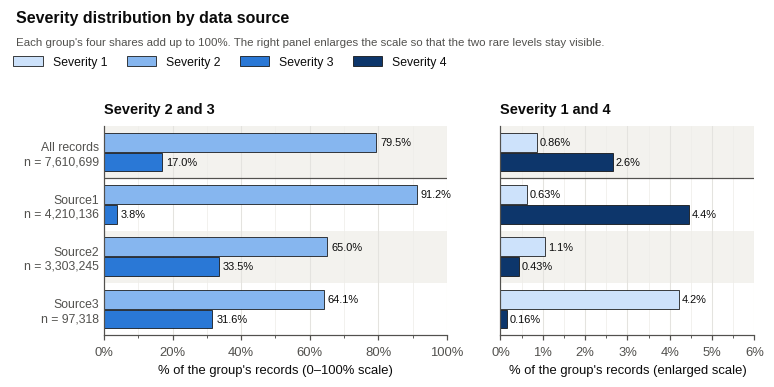

In [46]:
source_counts_sev = severity_counts(df["Source"])
source_mix = pd.concat([overall_mix.to_frame("All records").T.assign(Rows=n_clean),
                        severity_shares(source_counts_sev).loc[SOURCES]])
V_SOURCE = cramers_v(source_counts_sev)
start_year = start_time.dt.year
within_year_v = {int(y): cramers_v(severity_counts(df["Source"], (start_year == y).to_numpy()))
                 for y in sorted(start_year.unique()) if y < 2023}  # 2023 has Source1 records only
print(f"Cramér's V between Source and Severity: {V_SOURCE:.2f} for all records; within single years "
      f"{min(within_year_v.values()):.2f} ({min(within_year_v, key=within_year_v.get)}) to "
      f"{max(within_year_v.values()):.2f} ({max(within_year_v, key=within_year_v.get)})")

fig, axes = plt.subplots(1, 2, figsize=(7.0, 3.5), sharey=True, gridspec_kw={"width_ratios": [1.35, 1]})
y = np.arange(len(source_mix))[::-1].astype(float)
for ax, levels, scale in zip(axes, (MAJOR_LEVELS, MINOR_LEVELS), ("0–100% scale", "enlarged scale")):
    shade_rows(ax, y)
    limit = 100 if levels == MAJOR_LEVELS else np.ceil(source_mix[levels].max().max() * 1.3)
    for shift, k in zip((0.19, -0.19), levels):  # grouped bars: the first level of the panel above the second
        values = source_mix[k].to_numpy(dtype=float)
        ax.barh(y + shift, values, height=0.36, color=SEVERITY_COLORS[k], edgecolor=COLORS["ink"], linewidth=0.5, zorder=2)
        for yi, v in zip(y + shift, values):
            ax.text(v + 0.012 * limit, yi, f"{share_label(v)}%", va="center", fontsize=7.2, zorder=4)
    ax.axhline(y[0] - 0.5, color=COLORS["muted"], linewidth=0.8, zorder=1)  # all records above, the sources below
    ax.set_xlim(0, limit)
    percent_axis(ax.xaxis, n_ticks=6)
    value_grid(ax, "x")
    ax.tick_params(axis="y", length=0)
    ax.set_title(f"Severity {levels[0]} and {levels[1]}", fontsize=9.5)
    ax.set_xlabel(f"% of the group's records ({scale})", fontsize=8.5)
axes[0].set_yticks(y, [f"{g}\nn = {int(n):,}" for g, n in source_mix["Rows"].items()], fontsize=8)
axes[0].set_ylim(-0.5, len(y) - 0.5)
top = figure_header(fig, "Severity distribution by data source",
                    "Each group's four shares add up to 100%. The right panel enlarges the scale so that the two rare levels "
                    "stay visible.", handles=severity_handles())
fig.tight_layout(rect=(0, 0, 1, top), w_pad=2.0)
save_figure(fig, "severity_by_source")
plt.show()

**Finding.** Every level differs by provider. Source1 records are 91.2% Severity 2 and 4.4% Severity 4, with 3.8% Severity 3. Source2 and Source3 records are about one-third Severity 3 (33.5% and 31.6%) and have little Severity 4 (0.43% and 0.16%). Cramér's V between `Source` and `Severity` is 0.29, and it stays between 0.20 and 0.48 within single years.

**Limitation.** The within-year comparison rules out only one explanation, a different mix of years. Geography, road type and the kind of accidents each provider captures can still differ.

**Question:** how does the Severity distribution of all records change month by month?

Severity 3, share of each year's records: 2016 30.7%, 2017 32.2%, 2018 32.8%, 2019 24.9%, 2020 16.6%, 2021 9.6%, 2022 4.5%, 2023 0.0%
Severity 1, share of each year's records: 2016 0.05%, 2017 0.04%, 2018 0.03%, 2019 0.02%, 2020 2.42%, 2021 0.01%, 2022 2.17%, 2023 0.00%


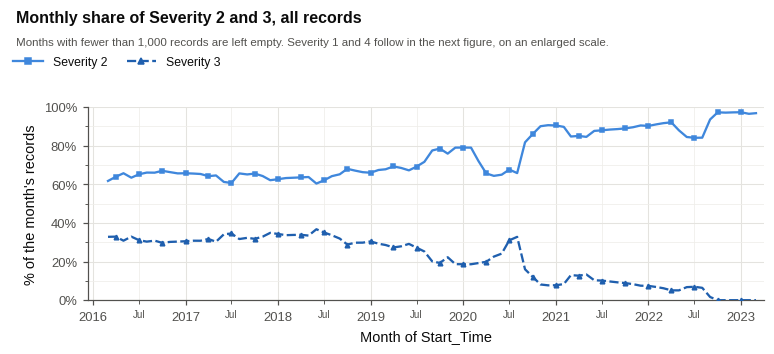

In [47]:
ALL_MONTHS = pd.period_range(month_key.min(), month_key.max(), freq="M")
TIMELINE = MONTH_AXIS_LIMITS  # the calendar range shared by every monthly figure (Section 2.1.4)
month_counts = pd.crosstab(month_key, severity).reindex(index=ALL_MONTHS, columns=SEVERITY_LEVELS, fill_value=0)
month_rows = month_counts.sum(axis=1)
pooled_monthly = (month_counts.div(month_rows, axis=0) * 100).where(month_rows >= MIN_GROUP_ROWS)  # too few records: empty
year_mix = severity_shares(severity_counts(start_year))
for k, decimals in ((3, 1), (1, 2)):
    print(f"Severity {k}, share of each year's records: " + ", ".join(f"{y} {v:.{decimals}f}%" for y, v in year_mix[k].items()))


def pooled_month_figure(levels, title, note):
    """Monthly share of the given Severity levels among all records, both on one percentage scale."""
    fig, ax = plt.subplots(figsize=(7.0, 3.2))
    for k in levels:
        ax.plot(ALL_MONTHS.to_timestamp(), pooled_monthly[k], linewidth=1.5, markersize=3, markevery=3, zorder=3,
                **SEVERITY_LINES[k])
    ax.set_ylim(0, 100 if levels == MAJOR_LEVELS else pooled_monthly[levels].max().max() * 1.15)
    percent_axis(ax.yaxis, n_ticks=6)
    value_grid(ax, "y")
    ax.set_xlim(*TIMELINE)
    month_axis(ax)
    ax.set_ylabel("% of the month's records")
    ax.set_xlabel("Month of Start_Time")
    top = figure_header(fig, title, note, handles=severity_handles(levels, kind="line"))
    fig.tight_layout(rect=(0, 0, 1, top))
    return fig


fig = pooled_month_figure(MAJOR_LEVELS, "Monthly share of Severity 2 and 3, all records",
                          f"Months with fewer than {MIN_GROUP_ROWS:,} records are left empty. Severity 1 and 4 follow in the "
                          "next figure, on an enlarged scale.")
save_figure(fig, "severity_by_month_levels_2_3")
plt.show()

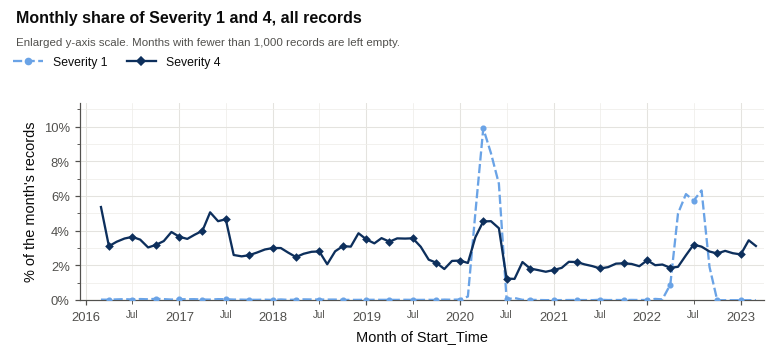

In [48]:
fig = pooled_month_figure(MINOR_LEVELS, "Monthly share of Severity 1 and 4, all records",
                          f"Enlarged y-axis scale. Months with fewer than {MIN_GROUP_ROWS:,} records are left empty.")
save_figure(fig, "severity_by_month_levels_1_4")
plt.show()

**Finding.** Severity 3 makes up about a third of the records in 2016–2018 (32.8% in 2018) and falls to 4.5% in 2022. Severity 1 appears only in 2020 and 2022 (2.42% and 2.17% of the year's records). Part of this reflects the change in provider mix over time (Section 2.2.1), so the next step looks inside each provider.

**Question:** do the distributions also shift within each provider, and where are the changes abrupt?

**Method.** Monthly shares within each source. Months with fewer than 1,000 records of the source are left empty, not treated as zero. A month-to-month change of at least 10 percentage points in any level marks a candidate discontinuity: a change worth investigating, not a confirmed change in coding rules. Both source figures use the full calendar axis from January 2016 to March 2023; months in which a source has no records at all are marked as such rather than left blank.

In [49]:
source_month = pd.crosstab([df["Source"], month_key], severity).reindex(columns=SEVERITY_LEVELS, fill_value=0)
source_month_rows = source_month.sum(axis=1)
monthly_share, supported_months = {}, {}
for s in SOURCES:
    rows = source_month_rows.loc[s]
    supported_months[s] = rows.index[rows >= MIN_GROUP_ROWS]
    monthly_share[s] = (source_month.loc[s].div(rows, axis=0) * 100).loc[supported_months[s]].reindex(ALL_MONTHS)
    print(f"{s}: {len(supported_months[s])} of {len(rows)} months with records reach {MIN_GROUP_ROWS:,} records")

JUMP_PP = 10  # a month-to-month change of at least 10 percentage points in any level marks a candidate discontinuity
candidate_breaks = []  # (source, last month before, first month after), consecutive supported months of one source
for s in SOURCES:
    share = monthly_share[s].dropna()
    change = share.diff().abs()
    for i in np.flatnonzero(change.max(axis=1).to_numpy() >= JUMP_PP):
        before, after = share.index[i - 1], share.index[i]
        candidate_breaks.append((s, before, after))
        print(f"Candidate discontinuity, {s} {before.strftime('%b %Y')} to {after.strftime('%b %Y')}: " + ", ".join(
            f"S{k} {share.at[before, k]:.1f}% to {share.at[after, k]:.1f}%" for k in SEVERITY_LEVELS))

Source1: 83 of 87 months with records reach 1,000 records
Source2: 79 of 80 months with records reach 1,000 records
Source3: 35 of 80 months with records reach 1,000 records
Candidate discontinuity, Source1 Aug 2019 to Sep 2019: S1 0.0% to 0.0%, S2 75.7% to 89.7%, S3 13.7% to 5.4%, S4 10.7% to 5.0%
Candidate discontinuity, Source1 Feb 2020 to Mar 2020: S1 0.5% to 8.9%, S2 90.5% to 73.2%, S3 4.8% to 12.1%, S4 4.2% to 5.8%
Candidate discontinuity, Source1 Mar 2020 to Apr 2020: S1 8.9% to 14.6%, S2 73.2% to 62.1%, S3 12.1% to 17.0%, S4 5.8% to 6.3%
Candidate discontinuity, Source1 Jun 2020 to Sep 2020: S1 10.5% to 0.0%, S2 62.5% to 96.6%, S3 21.2% to 0.0%, S4 5.9% to 3.4%
Candidate discontinuity, Source2 Apr 2022 to May 2022: S1 5.2% to 31.1%, S2 62.6% to 34.8%, S3 31.6% to 33.4%, S4 0.6% to 0.7%
Candidate discontinuity, Source3 Apr 2022 to May 2022: S1 8.1% to 42.9%, S2 68.9% to 33.9%, S3 22.5% to 23.0%, S4 0.4% to 0.2%


In [50]:
def month_span(first, last):
    """Label such as 'Aug–Sep 2019' for a pair of months."""
    return (f"{first.strftime('%b')}–{last.strftime('%b %Y')}" if first.year == last.year
            else f"{first.strftime('%b %Y')}–{last.strftime('%b %Y')}")


FEW_RECORDS = dict(color="#dddcd6", linewidth=0)  # months with too few records of the source: left empty
NO_RECORDS = dict(facecolor="white", edgecolor="#a9a7a1", hatch="////", linewidth=0)  # months without any record of it
BREAK_LINE = dict(color=COLORS["muted"], linestyle="--", linewidth=0.9)


def plot_source_timeline(source):
    """Monthly share of each Severity level within one source, one panel per level on the common calendar axis of all
    monthly figures. Candidate discontinuities are dashed lines; months with too few records are shaded and left empty;
    months without any record of the source are hatched."""
    x = ALL_MONTHS.to_timestamp()
    months_with_records = source_month_rows.loc[source].index
    gaps = months_with_records.difference(supported_months[source])
    no_records = ALL_MONTHS.difference(months_with_records)
    last_record = start_time[is_source[source]].max()
    breaks = [(before, after, before.start_time + (after.start_time - before.start_time) / 2)
              for s, before, after in candidate_breaks if s == source]
    labels = []  # [first month, last month, positions]; breaks less than three months apart share one label
    for before, after, mid in breaks:
        if labels and (mid - labels[-1][2][-1]).days < 92:
            labels[-1][1] = after
            labels[-1][2].append(mid)
        else:
            labels.append([before, after, [mid]])
    fig, axes = plt.subplots(4, 1, figsize=(7.0, 6.9), sharex=True)
    for ax, k in zip(axes, SEVERITY_LEVELS):
        values = monthly_share[source][k].to_numpy(dtype=float)
        top = max(np.nanmax(values) * 1.15, 1.0)
        for g in gaps:
            ax.axvspan(g.start_time, (g + 1).start_time, zorder=0, **FEW_RECORDS)
        for g in no_records:
            ax.axvspan(max(g.start_time, TIMELINE[0]), (g + 1).start_time, zorder=0, **NO_RECORDS)
        for _, _, mid in breaks:
            ax.axvline(mid, zorder=1, **BREAK_LINE)
        ax.plot(x, values, color=SOURCE_COLORS[source], linewidth=1.6, zorder=3)
        ax.set_ylim(-0.04 * top, top)  # a small offset keeps a line at 0% visible above the axis
        percent_axis(ax.yaxis, n_ticks=6)
        value_grid(ax, "y")
        month_axis(ax)
        ax.set_title(f"Severity {k}", fontsize=9, pad=3)
    axes[-1].set_xlim(*TIMELINE)
    axes[-1].set_xlabel("Month of Start_Time")
    fig.supylabel(f"% of the month's {source} records", fontsize=8.5)
    handles = [mpl.lines.Line2D([], [], color=SOURCE_COLORS[source], linewidth=1.6, label=f"Share of the month's {source} records"),
               mpl.lines.Line2D([], [], label=f"Candidate discontinuity (change of at least {JUMP_PP} pp)", **BREAK_LINE)]
    if len(gaps):
        handles.append(mpl.patches.Patch(label=f"Fewer than {MIN_GROUP_ROWS:,} {source} records (left empty)", **FEW_RECORDS))
    if len(no_records):
        handles.append(mpl.patches.Patch(label=f"No {source} records (last record {last_record.day} {last_record:%b %Y})",
                                         **NO_RECORDS))
    top = figure_header(fig, f"{source}: monthly share of each Severity level",
                        "Each panel has its own y-axis range. The calendar axis is the same in every monthly figure.",
                        handles=handles, ncol=2)
    strip = 0.3 if len(labels) > 2 else 0.05  # room above the first panel for staggered discontinuity labels
    fig.tight_layout(rect=(0, 0, 1, top - strip / fig.get_figheight()), h_pad=0.6)
    transform = axes[0].get_xaxis_transform()
    for i, (first, last, positions) in enumerate(labels):  # outer labels point away from the others, inner ones sit higher
        centre = positions[0] + (positions[-1] - positions[0]) / 2
        outer = len(labels) > 1 and i in (0, len(labels) - 1)
        align = "center" if not outer else "right" if i == 0 else "left"
        height = 1.05 if outer or len(labels) == 1 else 1.05 + 0.24 * (1 + (i - 1) % 2)
        axes[0].plot([centre, centre], [1.0, height + 0.13 if outer else height - 0.01], transform=transform,
                     color=COLORS["muted"], linewidth=0.6, clip_on=False)
        axes[0].text(centre, height, f" {month_span(first, last)} ", transform=transform, ha=align, va="bottom",
                     fontsize=7.5, color=COLORS["muted"])
    return fig

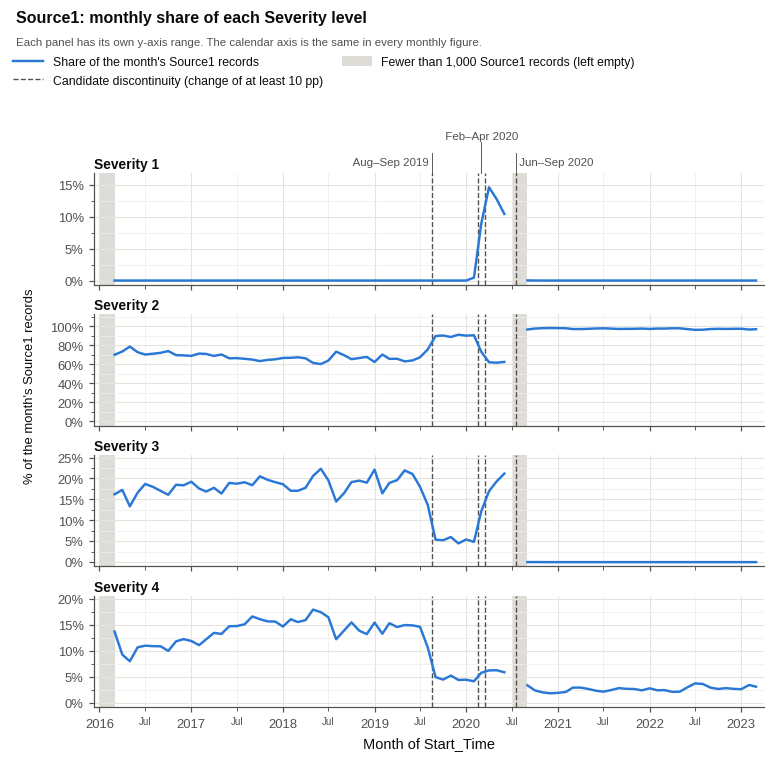

In [51]:
fig = plot_source_timeline("Source1")
save_figure(fig, "severity_by_month_source1")
plt.show()

**Finding (Source1).**

- Severity 4 makes up 8–18% of the monthly records until August 2019, 4–6% from September 2019 to June 2020 and 2–4% from September 2020.
- Severity 3 drops from 13.7% to 5.4% between August and September 2019, returns to 12–21% in March–June 2020 and is 0.0% in every month from September 2020.
- Severity 1 exceeds 1% of the monthly records only in March–June 2020 (8.9–14.6%).

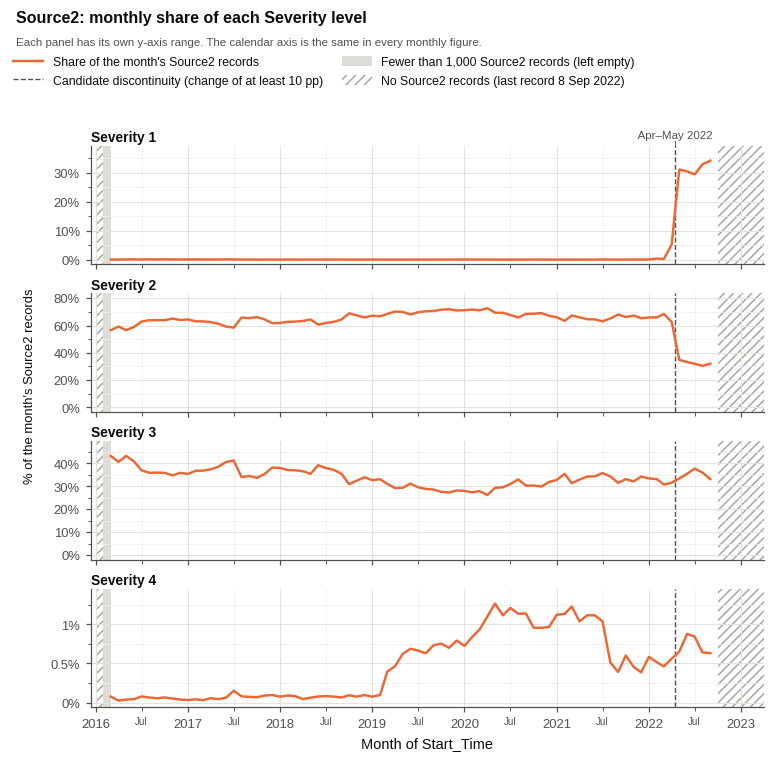

In [52]:
fig = plot_source_timeline("Source2")
save_figure(fig, "severity_by_month_source2")
plt.show()

**Finding (Source2 and Source3).** Source2's last record is from 8 September 2022; the later months are marked as having no Source2 records. Its Severity 3 share stays between 26% and 43% throughout, and its Severity 4 share never exceeds 1.3%. Severity 1 rises from 5.2% in April 2022 to 31.1% in May 2022 and stays at 29–34%, mostly at the expense of Severity 2. Source3 is too sparse for a monthly figure (35 of 80 months reach 1,000 records), but it shows the same change: Severity 1 rises from 8.1% in April to 42.9% in May 2022.

**What remains uncertain.** These are strong source- and period-dependent shifts; some are abrupt, and some levels vanish within a source and period. The observations do not show why. A change in the accidents recorded, in which accidents a provider captures, in traffic conditions or in how a level is coded could each produce them. Section 2.3.2 examines these explanations.

### 2.3.2 Investigating source/period distribution shifts

**Question:** what might explain the shifts? Four explanations are considered, without assuming which one is correct.

| Explanation | What it would look like in the data |
|---|---|
| The recorded accident population changed, including traffic conditions | Observable accident characteristics change together with the Severity shift |
| Source coverage or accident selection changed | The mix of states, cities or road types changes together with the shift |
| Coding or reporting conventions changed | The shift remains among comparable accidents, with little change in the observable mix |
| A combination | Part of the shift follows the observable mix, part does not |

`Severity` measures the impact on traffic, so different traffic conditions could change the recorded level even for similar accidents. The data contain no measure of traffic volume, so this explanation can be discussed but not tested.

**Comparisons.** Three within-source boundaries are each compared across the same calendar months one year apart, so that season is held roughly constant: Source1 in September 2019 and in September 2020, and Source2 in April 2022. The March–April 2020 changes fall inside the window for September 2020, and Source3 has too few records for stratified comparisons. Two cross-source comparisons set Source2 against Source1 over the same period: before September 2020, and September 2020 to March 2022.

**Observable characteristics.** The road class is read from `Street`: names beginning with "I-" or "Interstate" are interstates, and names with a highway designation (such as US-, SR-, Hwy, Fwy, Expy or a state prefix like CA-) are other named highways. It is a proxy, not an official classification. `Weather_Condition` labels are grouped into seven weather groups, so that old and new terminology (for example Clear and Fair) fall together; the column itself is not changed.

In [53]:
# Observable accident characteristics used from here on (analysis-only keys; df is not modified)
street = df["Street"].fillna("").str.strip()
is_interstate = street.str.contains(r"^(?:I-\s?\d|Interstate\b)", case=False, regex=True).to_numpy()
is_highway = ~is_interstate & street.str.contains(
    r"(?:\b(?:US|SR|State Route|Route|Rte|Hwy|Highway|Fwy|Freeway|Expy|Expressway|Pkwy|Parkway|Tpke|Turnpike|Beltway)\b|^[A-Z]{2}-\d)",
    case=False, regex=True).to_numpy()
ROAD_CLASSES = ["Interstate", "Other named highway", "Other or unnamed street"]
road_class_code = np.select([is_interstate, is_highway], [0, 1], 2)

# Display grouping of Weather_Condition labels: the first matching pattern wins, and old and new terminology
# (e.g. Clear and Fair) fall into the same group
WEATHER_PATTERNS = [("Thunderstorm", r"t-storm|thunder|tornado|funnel"), ("Snow or ice", r"snow|sleet|ice|freezing|wintry|hail"),
                    ("Rain or drizzle", r"rain|drizzle|shower"), ("Fog, haze or smoke", r"fog|haze|mist|smoke|dust|sand"),
                    ("Cloudy", r"cloud|overcast"), ("Clear or fair", r"clear|fair")]
WEATHER_GROUPS = ["Clear or fair", "Cloudy", "Rain or drizzle", "Snow or ice", "Thunderstorm", "Fog, haze or smoke", "Other", "Missing"]
weather_labels = pd.Series(df["Weather_Condition"].cat.categories)
label_groups = np.select([weather_labels.str.lower().str.contains(p) for _, p in WEATHER_PATTERNS],
                         [g for g, _ in WEATHER_PATTERNS], "Other")
label_to_group = dict(zip(weather_labels, label_groups))
weather_grp = remap_categories(df["Weather_Condition"], label_to_group).astype("object").fillna("Missing")
weather_grp = pd.Categorical(weather_grp, categories=WEATHER_GROUPS)
print("Road class from Street: " + ", ".join(f"{c} {100 * (road_class_code == i).mean():.1f}%" for i, c in enumerate(ROAD_CLASSES)))
print("Labels in the 'Other' weather group: " + ", ".join(l for l, g in label_to_group.items() if g == "Other"))

hour_of_day = start_time.dt.hour.to_numpy()
weekday = start_time.dt.dayofweek.to_numpy()
quarter_code = ((start_time.dt.year - 2016) * 4 + start_time.dt.quarter - 1).to_numpy()
CODED = {  # integer codes (missing = 0) for building strata
    "State": (df["State"].cat.codes.to_numpy() + 1, len(df["State"].cat.categories) + 1),
    "Road class": (road_class_code, 3),
    "Daylight": (df["Sunrise_Sunset"].cat.codes.to_numpy() + 1, len(df["Sunrise_Sunset"].cat.categories) + 1),
    "Weather group": (np.asarray(weather_grp.codes), len(WEATHER_GROUPS)),
    "Weekend": ((weekday >= 5).astype(int), 2),
    "Quarter": (quarter_code, int(quarter_code.max()) + 1)}


def between(start, end):
    return ((start_time >= start) & (start_time < end)).to_numpy()


COMPARISONS = {  # reference group first; within-source windows use the same calendar months one year apart
    "Source1, Sep 2019": ("Sep 2018–Feb 2019", is_source["Source1"] & between("2018-09-01", "2019-03-01"),
                          "Sep 2019–Feb 2020", is_source["Source1"] & between("2019-09-01", "2020-03-01")),
    "Source1, Sep 2020": ("Mar–Jun 2020", is_source["Source1"] & between("2020-03-01", "2020-07-01"),
                          "Mar–Jun 2021", is_source["Source1"] & between("2021-03-01", "2021-07-01")),
    "Source2, Apr 2022": ("Apr–Sep 2021", is_source["Source2"] & between("2021-04-01", "2021-10-01"),
                          "Apr–Sep 2022", is_source["Source2"] & between("2022-04-01", "2022-10-01")),
    "Source2 vs Source1, before Sep 2020": ("Source2", is_source["Source2"] & between("2016-01-01", "2020-09-01"),
                                            "Source1", is_source["Source1"] & between("2016-01-01", "2020-09-01")),
    "Source2 vs Source1, Sep 2020–Mar 2022": ("Source2", is_source["Source2"] & between("2020-09-01", "2022-04-01"),
                                              "Source1", is_source["Source1"] & between("2020-09-01", "2022-04-01"))}
WITHIN_SOURCE = list(COMPARISONS)[:3]

Road class from Street: Interstate 24.9%, Other named highway 27.3%, Other or unnamed street 47.8%
Labels in the 'Other' weather group: N/A Precipitation, Squalls, Squalls / Windy, Volcanic Ash


#### 2.3.2.1 Did the observable accident mix change?

**Question:** at each boundary, and between the providers, did the kind of accident recorded change? **Method:** the total variation distance between the two groups' distributions of each characteristic, TVD = ½ Σ |P_i − Q_i|, where P_i and Q_i are the groups' shares of category i. Both distributions use the union of the categories seen in either group (a category absent from one group has share 0), and a missing value counts as a category of its own, so each distribution sums to 1. TVD is 0 for identical distributions and 1 for distributions with no overlap. It measures how much the mix differs, not why.

Source1, Sep 2019 (Sep 2018–Feb 2019 to Sep 2019–Feb 2020): largest changes in state share CA 16.1% to 61.8%, OR 19.8% to 8.6%, MN 1.6% to 8.3%; interstate 37% to 30%; night 39% to 41%
Source1, Sep 2020 (Mar–Jun 2020 to Mar–Jun 2021): largest changes in state share FL 5.3% to 17.1%, CA 33.3% to 24.2%, TX 3.2% to 6.5%; interstate 24% to 26%; night 20% to 29%
Source2, Apr 2022 (Apr–Sep 2021 to Apr–Sep 2022): largest changes in state share CA 16.5% to 14.8%, FL 8.7% to 10.2%, AL 3.1% to 4.6%; interstate 27% to 28%; night 19% to 18%


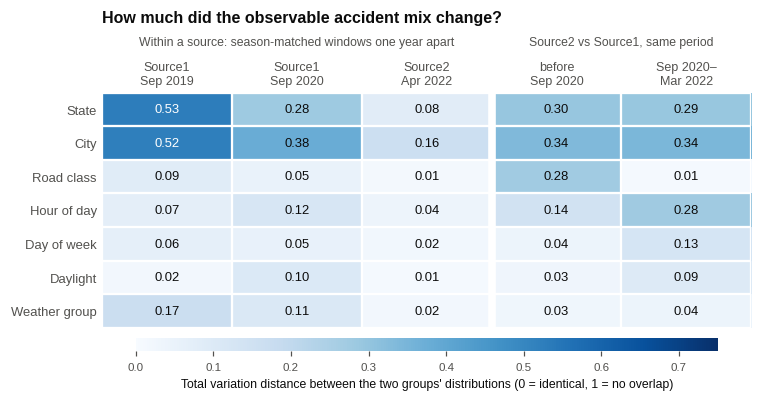

In [54]:
def tvd(values, a, b):
    """Total variation distance, 0.5 × sum of |P_i − Q_i|, between the distributions of `values` in two row groups
    (0 = identical, 1 = no overlap). Both use the union of the observed categories, with a share of 0 where a category
    is absent; a missing value is coded −1 and counts as a category of its own."""
    pa_ = pd.Series(values[a]).value_counts(normalize=True)
    pb = pd.Series(values[b]).value_counts(normalize=True)
    idx = pa_.index.union(pb.index)
    return 0.5 * float((pa_.reindex(idx, fill_value=0) - pb.reindex(idx, fill_value=0)).abs().sum())


MIX_DIMENSIONS = {"State": df["State"].cat.codes.to_numpy(), "City": df["City"].cat.codes.to_numpy(),
                  "Road class": road_class_code, "Hour of day": hour_of_day, "Day of week": weekday,
                  "Daylight": df["Sunrise_Sunset"].cat.codes.to_numpy(), "Weather group": np.asarray(weather_grp.codes)}
case_mix = pd.DataFrame({name: {d: tvd(v, ref, cmp) for d, v in MIX_DIMENSIONS.items()}
                         for name, (_, ref, _, cmp) in COMPARISONS.items()})
for name in WITHIN_SOURCE:
    ref_label, ref, cmp_label, cmp = COMPARISONS[name]
    shares = pd.DataFrame({"ref": df.loc[ref, "State"].value_counts(normalize=True),
                           "cmp": df.loc[cmp, "State"].value_counts(normalize=True)}).fillna(0) * 100
    biggest = (shares["cmp"] - shares["ref"]).abs().nlargest(3).index
    print(f"{name} ({ref_label} to {cmp_label}): largest changes in state share "
          + ", ".join(f"{st} {shares.at[st, 'ref']:.1f}% to {shares.at[st, 'cmp']:.1f}%" for st in biggest)
          + f"; interstate {100 * is_interstate[ref].mean():.0f}% to {100 * is_interstate[cmp].mean():.0f}%"
          + f"; night {100 * df['Sunrise_Sunset'].eq('Night').to_numpy()[ref].mean():.0f}% to "
            f"{100 * df['Sunrise_Sunset'].eq('Night').to_numpy()[cmp].mean():.0f}%")

COMPARISON_LABELS = {"Source1, Sep 2019": "Source1\nSep 2019", "Source1, Sep 2020": "Source1\nSep 2020",
                     "Source2, Apr 2022": "Source2\nApr 2022", "Source2 vs Source1, before Sep 2020": "before\nSep 2020",
                     "Source2 vs Source1, Sep 2020–Mar 2022": "Sep 2020–\nMar 2022"}
fig, ax = plt.subplots(figsize=(7.0, 3.7))
values = case_mix.to_numpy()
image = ax.imshow(values, cmap="Blues", vmin=0, vmax=0.75, aspect="auto")
for i, j in np.ndindex(values.shape):
    ax.text(j, i, f"{values[i, j]:.2f}", ha="center", va="center", fontsize=8.5,
            color="white" if values[i, j] > 0.4 else COLORS["ink"])
ax.set_xticks(range(values.shape[1]), [COMPARISON_LABELS[c] for c in case_mix.columns], fontsize=8.2)
ax.xaxis.tick_top()
ax.set_yticks(range(values.shape[0]), case_mix.index, fontsize=8.5)
ax.set_xticks(np.arange(-0.5, values.shape[1]), minor=True)
ax.set_yticks(np.arange(-0.5, values.shape[0]), minor=True)
ax.grid(which="minor", color="white", linewidth=1.5)
ax.tick_params(which="both", length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.axvline(len(WITHIN_SOURCE) - 0.5, color="white", linewidth=5)
for x_centre, text in [((len(WITHIN_SOURCE) - 1) / 2, "Within a source: season-matched windows one year apart"),
                       (len(WITHIN_SOURCE) + 0.5, "Source2 vs Source1, same period")]:
    ax.annotate(text, (x_centre, 1), xycoords=("data", "axes fraction"), xytext=(0, 29), textcoords="offset points",
                ha="center", va="bottom", fontsize=8, color=COLORS["muted"])
ax.set_title("How much did the observable accident mix change?", pad=46)
colorbar = fig.colorbar(image, ax=ax, orientation="horizontal", fraction=0.05, pad=0.04, aspect=45)
colorbar.set_label("Total variation distance between the two groups' distributions (0 = identical, 1 = no overlap)",
                   fontsize=8)
colorbar.ax.tick_params(labelsize=7.5)
colorbar.outline.set_visible(False)
fig.tight_layout()
save_figure(fig, "case_mix_change")
plt.show()

**Finding.**

- **Source1, September 2019:** geographic coverage changed sharply (state TVD 0.53). California rose from 16.1% to 61.8% of the records and Oregon fell from 19.8% to 8.6%.
- **Source1, September 2020:** coverage changed moderately (state TVD 0.28; Florida rose from 5.3% to 17.1%), and more records fall at night (20% to 29%).
- **Source2, April 2022:** the observable mix is almost unchanged (state TVD 0.08, city 0.16, every other characteristic 0.04 or less).
- **Source2 against Source1:** coverage differs in both periods (state TVD 0.30 and 0.29); road class differs before September 2020 (0.28) and hour of day afterwards (0.28).

**Limitation.** A change in mix does not by itself explain a Severity shift. The next two steps test whether the Severity differences remain among comparable records.

#### 2.3.2.2 Do providers differ within comparable groups?

**Question:** within the same state and quarter, do Source1 and Source2 still record different Severity distributions? **Method:** strata are State × Quarter cells in which each provider has at least 500 records. For each stratum and level the difference is Source1's share minus Source2's share, in percentage points. The box plots summarize these differences across the strata; every stratum counts once, whatever its number of records.

Before Sep 2020: 310 shared strata, holding 88.3% of Source1 and 75.8% of Source2 records in the period; median difference S1 -0.0, S2 -0.4, S3 -20.5, S4 +16.9 points
Sep 2020–Mar 2022: 168 shared strata, holding 94.7% of Source1 and 89.5% of Source2 records in the period; median difference S1 -0.0, S2 +34.0, S3 -35.1, S4 +1.6 points
Apr–Sep 2022: 51 shared strata, holding 92.9% of Source1 and 93.1% of Source2 records in the period; median difference S1 -22.5, S2 +60.3, S3 -39.0, S4 +1.9 points


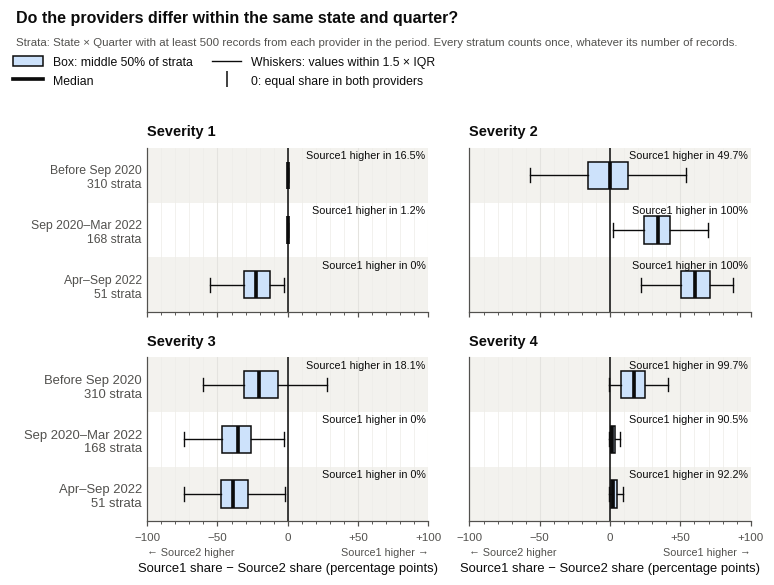

In [55]:
# Source1 minus Source2 inside State × Quarter strata where both providers have at least STRATUM_MIN_ROWS records
STRATUM_MIN_ROWS = 500
state_quarter = CODED["State"][0].astype(np.int64) * 1_000 + quarter_code
STRATA_PERIODS = {"Before Sep 2020": between("2016-01-01", "2020-09-01"), "Sep 2020–Mar 2022": between("2020-09-01", "2022-04-01"),
                  "Apr–Sep 2022": between("2022-04-01", "2022-10-01")}
stratum_differences = {}
for period, in_period in STRATA_PERIODS.items():
    counts = {s: pd.crosstab(state_quarter[is_source[s] & in_period], sev_values[is_source[s] & in_period])
              .reindex(columns=SEVERITY_LEVELS, fill_value=0) for s in MAIN_SOURCES}
    n1, n2 = counts["Source1"].sum(axis=1), counts["Source2"].sum(axis=1)
    shared = n1.index[n1 >= STRATUM_MIN_ROWS].intersection(n2.index[n2 >= STRATUM_MIN_ROWS])
    stratum_differences[period] = (counts["Source1"].loc[shared].div(n1[shared], axis=0)
                                   - counts["Source2"].loc[shared].div(n2[shared], axis=0)) * 100
    print(f"{period}: {len(shared)} shared strata, holding {100 * n1[shared].sum() / n1.sum():.1f}% of Source1 and "
          f"{100 * n2[shared].sum() / n2.sum():.1f}% of Source2 records in the period; median difference "
          + ", ".join(f"S{k} {stratum_differences[period][k].median():+.1f}" for k in SEVERITY_LEVELS) + " points")
share_higher = pd.DataFrame({p: (d > 0).mean() * 100 for p, d in stratum_differences.items()}).T  # % of strata, Source1 higher

limit = 20 * np.ceil(max(d.abs().max().max() for d in stratum_differences.values()) / 20)
BOX = dict(vert=False, widths=0.5, whis=1.5, showfliers=False, patch_artist=True, manage_ticks=False,
           boxprops=dict(facecolor="#cde2fb", edgecolor=COLORS["ink"], linewidth=1.0), medianprops=dict(color=COLORS["ink"], linewidth=2.4),
           whiskerprops=dict(color=COLORS["ink"], linewidth=0.9), capprops=dict(color=COLORS["ink"], linewidth=0.9))
fig, axes = plt.subplots(2, 2, figsize=(7.0, 5.3), sharex=True, sharey=True)
y = np.arange(len(STRATA_PERIODS))[::-1].astype(float)
for ax, k in zip(axes.flat, SEVERITY_LEVELS):
    shade_rows(ax, y)
    ax.axvline(0, color=COLORS["ink"], linewidth=1.0, zorder=1)
    for yi, (period, diff) in zip(y, stratum_differences.items()):
        ax.boxplot(diff[k].to_numpy(), positions=[yi], zorder=3, **BOX)
        higher = share_higher.at[period, k]
        ax.text(limit * 0.98, yi + 0.27, f"Source1 higher in {higher:.0f}%" if higher in (0, 100) else
                f"Source1 higher in {higher:.1f}%", ha="right", va="bottom", fontsize=7, color=COLORS["ink"], zorder=4)
    ax.set_xlim(-limit, limit)
    ax.xaxis.set_major_locator(mticker.MultipleLocator(50))
    ax.xaxis.set_minor_locator(mticker.MultipleLocator(10))
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: signed(v, 0) if v else "0"))
    value_grid(ax, "x")
    ax.tick_params(axis="y", length=0)
    ax.tick_params(axis="x", labelsize=7.5)
    ax.set_title(f"Severity {k}", fontsize=9.5)
axes[0, 0].set_yticks(y, [f"{p}\n{len(d)} strata" for p, d in stratum_differences.items()], fontsize=8)
axes[0, 0].set_ylim(-0.5, len(y) - 0.5)
for ax in axes[1]:
    ax.set_xlabel("Source1 share − Source2 share (percentage points)", fontsize=8.5, labelpad=13)
    ax.text(0.0, -0.155, "← Source2 higher", transform=ax.transAxes, ha="left", va="top", fontsize=7, color=COLORS["muted"])
    ax.text(1.0, -0.155, "Source1 higher →", transform=ax.transAxes, ha="right", va="top", fontsize=7, color=COLORS["muted"])
handles = [mpl.patches.Patch(facecolor="#cde2fb", edgecolor=COLORS["ink"], label="Box: middle 50% of strata"),
           mpl.lines.Line2D([], [], color=COLORS["ink"], linewidth=2.4, label="Median"),
           mpl.lines.Line2D([], [], color=COLORS["ink"], linewidth=0.9, label="Whiskers: values within 1.5 × IQR"),
           mpl.lines.Line2D([], [], color=COLORS["ink"], linestyle="none", marker="|", markersize=10, markeredgewidth=1.0,
                            label="0: equal share in both providers")]
top = figure_header(fig, "Do the providers differ within the same state and quarter?",
                    f"Strata: State × Quarter with at least {STRATUM_MIN_ROWS} records from each provider in the period. Every "
                    "stratum counts once, whatever its number of records.", handles=handles, ncol=2)
fig.tight_layout(rect=(0, 0, 1, top), h_pad=1.2)
save_figure(fig, "source_difference_within_strata")
plt.show()

**Finding.** The shared strata hold 76% to 95% of each provider's records in the period, so the comparison is not limited to a small overlap.

- **Before September 2020 (310 strata):** Source1 has more Severity 4 than Source2 in 99.7% of the strata (median +16.9 percentage points), and a larger Severity 3 share in only 18.1% of them (median −20.5 points).
- **September 2020 to March 2022 (168 strata):** Source1 has less Severity 3 and more Severity 2 in every stratum (medians −35.1 and +34.0 points).
- **April to September 2022 (51 strata):** Source2 has more Severity 1 in every stratum (median difference −22.5 points).

**Limitation.** Every stratum counts once, so a small stratum weighs as much as a large one: the percentages above count comparable groups, not records. The provider difference is nevertheless not a matter of when or in which state a record was made. It could still reflect the kind of accidents each provider captures within a state, for example different road types.

#### 2.3.2.3 How much of the difference does the observable mix explain?

**Question:** if the earlier window (or Source2) had the observable accident mix of the later window (or Source1), would its Severity distribution look like the later window's (or Source1's)?

**Method: direct standardization.**

1. **Comparisons.** Within a source, each window is compared with the same calendar months one year later: Source1, September 2018–February 2019 against September 2019–February 2020 (the September 2019 boundary); Source1, March–June 2020 against March–June 2021 (the September 2020 boundary); Source2, April–September 2021 against April–September 2022 (the April 2022 boundary). Between sources, Source2 is compared with Source1 before September 2020 and from September 2020 to March 2022.
2. **Strata.** Records are grouped by state × road class (from `Street`) × daylight (`Sunrise_Sunset`). Between sources the calendar quarter is added, so that the providers are compared within the same quarters.
3. **Reference rates.** In each stratum s, the reference group (the earlier window, or Source2) gives the share of each level, P_ref(k | s). A stratum is used only if it has at least 30 reference records.
4. **Target weights.** The comparison group (the later window, or Source1) gives the weights w_s, its share of records in each usable stratum.
5. **Standardized share.** Σ_s w_s × P_ref(k | s) is the share of level k that the reference group would have with the comparison group's mix of state, road class and daylight (and quarter).
6. **Common support.** Comparison records in strata without 30 reference records are left out of the weights and of the comparison group's observed shares. The strata cover 93.5% to 99.5% of the comparison records.

The figures show two changes for each level: the observed change (comparison minus reference) and the change expected from the case mix alone (the standardized share minus the reference group's observed share). If they match, the difference in observable mix reproduces the change; if the expected change stays near zero, it does not.

**What it can and cannot establish.** Standardization shows how much of a difference follows the characteristics in the strata. It does not identify the cause of the remaining difference, and it adjusts for nothing outside the strata, such as accident type, lanes affected, reporting channel or traffic volume.

In [56]:
STANDARDIZE_MIN_ROWS = 30  # a reference stratum needs this many records for its Severity distribution to be used


def stratum_key(dimensions, mask):
    """Integer stratum identifier built from coded characteristics, for the rows in `mask`."""
    key = np.zeros(int(mask.sum()), dtype=np.int64)
    for d in dimensions:
        codes, size = CODED[d]
        key = key * size + codes[mask]
    return key


def standardize(reference, comparison, dimensions):
    """Direct standardization: the reference group's stratum-specific Severity distributions, weighted by the
    comparison group's stratum mix. Strata without enough reference records are left out, and the share of
    comparison records they hold is reported."""
    ref_key, cmp_key = stratum_key(dimensions, reference), stratum_key(dimensions, comparison)
    ref_counts = pd.crosstab(ref_key, sev_values[reference]).reindex(columns=SEVERITY_LEVELS, fill_value=0)
    ref_rows = ref_counts.sum(axis=1)
    rates = ref_counts[ref_rows >= STANDARDIZE_MIN_ROWS].div(ref_rows[ref_rows >= STANDARDIZE_MIN_ROWS], axis=0)
    cmp_mix = pd.Series(cmp_key).value_counts()
    usable = cmp_mix.index.intersection(rates.index)
    covered = np.isin(cmp_key, usable)
    covered_mask = np.zeros(n_clean, dtype=bool)
    covered_mask[np.flatnonzero(comparison)[covered]] = True
    return {"Reference, observed": mix_of(reference),
            "Reference, reweighted": rates.loc[usable].mul(cmp_mix[usable] / cmp_mix[usable].sum(), axis=0).sum() * 100,
            "Comparison, observed": mix_of(covered_mask),
            "Comparison rows covered (%)": 100 * covered.mean()}


STRATA = {name: ["State", "Road class", "Daylight"] + ([] if name in WITHIN_SOURCE else ["Quarter"]) for name in COMPARISONS}
SENSITIVITY_EXTRA = ["Weather group", "Weekend"]
standardized = {name: standardize(ref, cmp, STRATA[name]) for name, (_, ref, _, cmp) in COMPARISONS.items()}
sensitivity = {name: standardize(ref, cmp, STRATA[name] + SENSITIVITY_EXTRA) for name, (_, ref, _, cmp) in COMPARISONS.items()}
coverage = pd.Series({n: r["Comparison rows covered (%)"] for n, r in standardized.items()})
coverage_extra = pd.Series({n: r["Comparison rows covered (%)"] for n, r in sensitivity.items()})
largest_move = max((sensitivity[n]["Reference, reweighted"] - standardized[n]["Reference, reweighted"]).abs().max()
                   for n in COMPARISONS)
print(f"Strata cover {coverage.min():.1f}% to {coverage.max():.1f}% of the comparison records.")
print(f"Sensitivity check: adding weather group and weekend to the strata (coverage {coverage_extra.min():.1f}% to "
      f"{coverage_extra.max():.1f}%) moves the reweighted shares by at most {largest_move:.1f} percentage points.")

Strata cover 93.5% to 99.5% of the comparison records.
Sensitivity check: adding weather group and weekend to the strata (coverage 79.1% to 93.2%) moves the reweighted shares by at most 3.0 percentage points.


In [57]:
standardized_change = {  # percentage points, per comparison and level
    "observed": pd.DataFrame({n: r["Comparison, observed"] - r["Reference, observed"] for n, r in standardized.items()}).T,
    "expected": pd.DataFrame({n: r["Reference, reweighted"] - r["Reference, observed"] for n, r in standardized.items()}).T}
print("Share of each level (%): reference observed / reference standardized to the comparison mix / comparison observed")
for n, r in standardized.items():
    print(f"  {n}: " + "; ".join(f"S{k} {r['Reference, observed'][k]:.1f} / {r['Reference, reweighted'][k]:.1f} / "
                                 f"{r['Comparison, observed'][k]:.1f}" for k in SEVERITY_LEVELS))
CHANGE_BARS = {"observed": dict(color=COLORS["primary"]),
               "expected": dict(facecolor="white", edgecolor=COLORS["primary"], hatch="////", linewidth=0.8)}


def standardization_figure(names, panel_titles, legend_labels, x_label, title, note, name):
    """For each comparison and Severity level, the observed change in share (comparison group minus reference group) and
    the change expected from the case mix alone (reference group standardized to the comparison group's mix, minus the
    reference group as observed), in percentage points."""
    changes = {kind: table.loc[names] for kind, table in standardized_change.items()}
    extent = max(t.abs().max().max() for t in changes.values())
    y = np.arange(len(SEVERITY_LEVELS))[::-1].astype(float)
    fig, axes = plt.subplots(1, len(names), figsize=(7.0, 3.3), sharex=True, sharey=True)
    for ax, comparison in zip(np.atleast_1d(axes), names):
        shade_rows(ax, y)
        for shift, kind in zip((0.19, -0.19), ("observed", "expected")):
            values = changes[kind].loc[comparison, SEVERITY_LEVELS].to_numpy(dtype=float)
            ax.barh(y + shift, values, height=0.36, zorder=2, **CHANGE_BARS[kind])
            for yi, v in zip(y + shift, values):
                right = round(v, 1) >= 0  # labels of values that round to 0.0 also sit right of the zero line
                ax.text(v + (0.03 if right else -0.03) * extent, yi, signed(v), ha="left" if right else "right", va="center",
                        fontsize=6.8, zorder=4)
        ax.axvline(0, color=COLORS["ink"], linewidth=0.9, zorder=3)
        ax.set_xlim(-extent * 1.45, extent * 1.45)
        percent_axis(ax.xaxis, n_ticks=5, signed_labels=True)
        value_grid(ax, "x")
        ax.tick_params(axis="y", length=0)
        ax.tick_params(axis="x", labelsize=7.5)
        heading, windows = panel_titles(comparison)
        ax.set_title(heading, fontsize=9, pad=15)
        ax.text(0, 1.025, windows, transform=ax.transAxes, ha="left", va="bottom", fontsize=7.5, color=COLORS["muted"])
    first = np.atleast_1d(axes)[0]
    first.set_yticks(y, [f"Severity {k}" for k in SEVERITY_LEVELS], fontsize=8)
    first.set_ylim(-0.5, len(y) - 0.5)
    handles = [mpl.patches.Patch(label=legend_labels[0], **CHANGE_BARS["observed"]),
               mpl.patches.Patch(label=legend_labels[1], **CHANGE_BARS["expected"])]
    top = figure_header(fig, title, note, handles=handles, ncol=1)
    finish_layout(fig, axes, top, x_label, w_pad=1.5)
    save_figure(fig, name)
    plt.show()

Share of each level (%): reference observed / reference standardized to the comparison mix / comparison observed
  Source1, Sep 2019: S1 0.0 / 0.0 / 0.1; S2 67.0 / 71.1 / 90.4; S3 18.8 / 20.4 / 5.1; S4 14.2 / 8.5 / 4.4
  Source1, Sep 2020: S1 11.8 / 12.4 / 0.0; S2 64.4 / 60.9 / 97.5; S3 17.7 / 18.6 / 0.0; S4 6.1 / 8.1 / 2.5
  Source2, Apr 2022: S1 0.0 / 0.0 / 25.5; S2 65.3 / 65.1 / 39.3; S3 33.8 / 34.0 / 34.5; S4 0.9 / 0.9 / 0.7
  Source2 vs Source1, before Sep 2020: S1 0.0 / 0.0 / 2.7; S2 66.0 / 56.5 / 71.9; S3 33.7 / 43.0 / 15.7; S4 0.3 / 0.5 / 9.7
  Source2 vs Source1, Sep 2020–Mar 2022: S1 0.1 / 0.1 / 0.0; S2 66.4 / 68.7 / 97.7; S3 32.7 / 30.4 / 0.0; S4 0.8 / 0.8 / 2.3


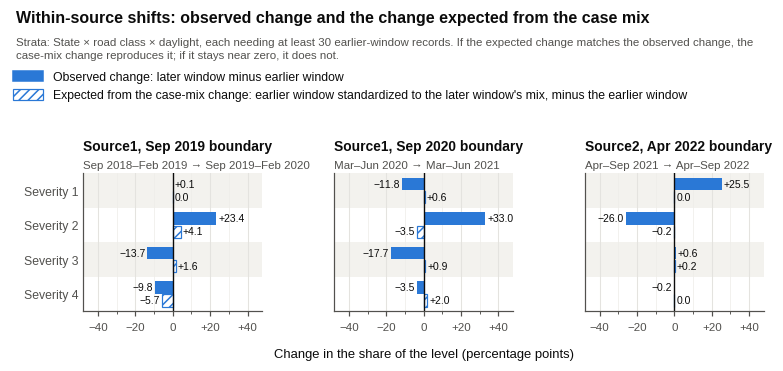

In [58]:
standardization_figure(
    WITHIN_SOURCE,
    panel_titles=lambda c: (f"{c.split(',')[0]}, {c.split(', ')[1]} boundary", f"{COMPARISONS[c][0]} → {COMPARISONS[c][2]}"),
    legend_labels=["Observed change: later window minus earlier window",
                   "Expected from the case-mix change: earlier window standardized to the later window's mix, minus the earlier "
                   "window"],
    x_label="Change in the share of the level (percentage points)",
    title="Within-source shifts: observed change and the change expected from the case mix",
    note="Strata: State × road class × daylight, each needing at least 30 earlier-window records. If the expected change matches "
         "the observed change, the case-mix change reproduces it; if it stays near zero, it does not.",
    name="standardization_within_source")

**Finding (within sources).**

- **Source1, September 2019: partly explained.** Severity 4 fell by 9.8 points (14.2% to 4.4%); the change in case mix alone would lower it by 5.7 points (to 8.5%), so the coverage change accounts for about three-fifths of the fall. It does not explain the fall in Severity 3 (13.7 points, from 18.8% to 5.1%), for which the case mix predicts a rise of 1.6 points.
- **Source1, September 2020: not explained.** Severity 1 fell by 11.8 points and Severity 3 by 17.7 points, both to 0.0%; the case mix predicts small rises (to 12.4% and 18.6%).
- **Source2, April 2022: not explained.** Severity 1 rose by 25.5 points (from 0.0% to 25.5%); the case mix predicts no change.

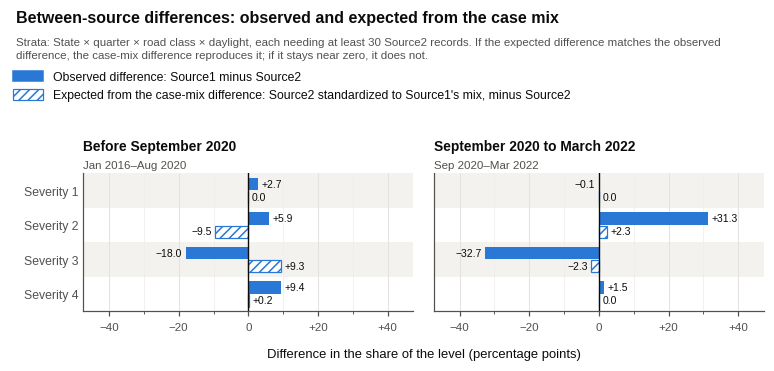

In [59]:
standardization_figure(
    [c for c in COMPARISONS if c not in WITHIN_SOURCE],
    panel_titles=lambda c: {"Source2 vs Source1, before Sep 2020": ("Before September 2020", "Jan 2016–Aug 2020"),
                            "Source2 vs Source1, Sep 2020–Mar 2022": ("September 2020 to March 2022", "Sep 2020–Mar 2022")}[c],
    legend_labels=["Observed difference: Source1 minus Source2",
                   "Expected from the case-mix difference: Source2 standardized to Source1's mix, minus Source2"],
    x_label="Difference in the share of the level (percentage points)",
    title="Between-source differences: observed and expected from the case mix",
    note="Strata: State × quarter × road class × daylight, each needing at least 30 Source2 records. If the expected difference "
         "matches the observed difference, the case-mix difference reproduces it; if it stays near zero, it does not.",
    name="standardization_between_sources")

**Finding (between sources): not explained.** Reweighting Source2 to Source1's mix does not move it towards Source1. Before September 2020, Source1 has 18.0 points less Severity 3 than Source2 (15.7% against 33.7%), while the case mix predicts 9.3 points more (43.0%). From September 2020, Source1 has 32.7 points less Severity 3 (it records none) and 31.3 points more Severity 2; the case mix accounts for 2.3 points of each.

**Limitation.** The conclusions hold when weather group and weekend are added to the strata (79% to 93% of the comparison records covered; the reweighted shares move by at most 3.0 points). Standardization adjusts only for the characteristics included: accident type, lanes affected, reporting channel and traffic volume are not in the data.

#### 2.3.2.4 Records that may describe the same accident

**Question:** when Source1 and Source2 appear to report the same accident, do they record the same level? **Method:** records are paired when their start locations agree after rounding to about 100 m and their start times are at most 10 minutes apart. `Severity` plays no part in the matching.

In [60]:
# Source1 and Source2 records that may describe the same accident: start location equal after rounding to three decimal
# places (about 100 m) and start times at most 10 minutes apart. Severity plays no part in the matching.
MATCH_MINUTES = 10
location_key = (np.round(df["Start_Lat"].to_numpy() * 1000).astype(np.int64) * 1_000_000
                + np.round((df["Start_Lng"].to_numpy() + 200) * 1000).astype(np.int64))
minute_bin = start_time.to_numpy().astype("datetime64[m]").astype(np.int64) // MATCH_MINUTES
side = {s: pd.DataFrame({"loc": location_key[is_source[s]], "bin": minute_bin[is_source[s]],
                         "time": start_time.to_numpy()[is_source[s]], "severity": sev_values[is_source[s]],
                         "row": np.flatnonzero(is_source[s])}) for s in MAIN_SOURCES}
candidates = []
for shift in (-1, 0, 1):  # neighbouring 10-minute bins, so pairs across a bin edge are not missed
    pairs = side["Source1"].merge(side["Source2"].assign(bin=side["Source2"]["bin"] + shift), on=["loc", "bin"], suffixes=("_1", "_2"))
    candidates.append(pairs[(pairs["time_1"] - pairs["time_2"]).abs() <= pd.Timedelta(minutes=MATCH_MINUTES)])
same_event = pd.concat(candidates).drop_duplicates(["row_1", "row_2"])
same_label = same_event["severity_1"] == same_event["severity_2"]
pair_period = pd.cut(same_event["time_1"], pd.to_datetime(["2016-01-01", "2020-09-01", "2022-04-01", "2022-10-01"]), right=False,
                     labels=list(STRATA_PERIODS))
agreement = same_label.groupby(pair_period, observed=True).agg(["size", "mean"])
print(f"Candidate pairs: {len(same_event):,} ({same_event['row_1'].nunique():,} Source1 and {same_event['row_2'].nunique():,} "
      f"Source2 records). Same Severity in {100 * same_label.mean():.1f}% of pairs: "
      + "; ".join(f"{p} {100 * r['mean']:.1f}% of {int(r['size']):,}" for p, r in agreement.iterrows()))
pair_table = pd.crosstab(same_event["severity_1"], same_event["severity_2"], margins=True, margins_name="Total").reindex(
    index=SEVERITY_LEVELS + ["Total"], columns=SEVERITY_LEVELS + ["Total"], fill_value=0)
pair_table.index = [f"Source1: Severity {k}" if k != "Total" else "Total" for k in pair_table.index]
pair_table.columns = [f"Source2: Severity {k}" if k != "Total" else "Total" for k in pair_table.columns]
show_table(pair_table.reset_index(names=""), caption="Severity recorded by each provider in the candidate pairs (number of pairs)")

Candidate pairs: 4,073 (4,028 Source1 and 3,604 Source2 records). Same Severity in 67.3% of pairs: Before Sep 2020 67.2% of 2,583; Sep 2020–Mar 2022 80.4% of 984; Apr–Sep 2022 42.3% of 506


,Source2: Severity 1,Source2: Severity 2,Source2: Severity 3,Source2: Severity 4,Total
Source1: Severity 1,0,21,3,0,24
Source1: Severity 2,150,"2,672",959,4,"3,785"
Source1: Severity 3,0,158,69,0,227
Source1: Severity 4,0,25,11,1,37
Total,150,"2,876","1,042",5,"4,073"


**Finding.** The providers record the same level in 67% of the 4,073 candidate pairs (80% from September 2020 to March 2022, but 42% from April 2022). When Source2 records Severity 3, Source1 records Severity 2 in 959 of 1,042 pairs (92%), and all 150 pairs with Source2 Severity 1 are Severity 2 in Source1.

**Limitation.** Matching on shared fields does not independently verify that two records describe the same accident: separate accidents at the same place minutes apart would also match, and the candidates are a small, selected set (about 0.1% of Source1 records). The pairs also suggest that some accidents may appear twice in the dataset, once from each provider. The duplicate check in Section 1.3.3 cannot detect them, because the records differ in content.

#### 2.3.2.5 What the evidence supports

| Finding | Classification |
|---|---|
| Source1's fall in Severity 4 in September 2019 | Partly accompanied by a change in coverage |
| Source1's fall in Severity 3 in September 2019 | Persists after reweighting |
| Source1's loss of Severity 1 and 3 from September 2020 | Persists after reweighting, although coverage changed |
| Severity 1 in Source2 and Source3 from April 2022 | Persists with an almost unchanged observable mix |
| Source1 versus Source2 | Persists within State × Quarter strata, after reweighting and among candidate same-accident pairs |
| Severity 1 in Source1 in March–June 2020 | Unresolved: it coincides with the start of the COVID-19 pandemic in the United States, when traffic conditions changed, and the data cannot separate a traffic effect from a reporting change |
| Source3 | Unresolved: too few records for stratified comparison |

**Conclusion.** The pattern is consistent with provider- and period-specific coding or reporting conventions, but it does not establish them. Differences that persist within comparable observed groups could still come from unmeasured accident characteristics, from how each provider selects incidents, or from traffic conditions. The recorded `Severity` is therefore treated as a source- and period-dependent outcome whose cause is unresolved. In Section 2.3.3 all records remain the primary population, and Source1 and Source2 are shown separately wherever the pooled view could reflect the provider mix.

### 2.3.3 Complete bivariate Severity analysis

**How to read the figures.** Most figures have one panel per Severity level, each with its own x-axis range starting at zero. A bar is the share of a group's records at that level, and a dashed line marks the reference share: all records, or the provider's overall share. Where two bars share a row, the solid bar is the group with the feature (or at night) and the hatched bar the group without it (or by day). Group sizes are given in the row labels. Where they differ widely (weather groups, road features), groups with fewer than 10,000 records are drawn faintly, and groups with fewer than 1,000 records are left out of the provider and period comparisons. Time patterns are shown twice, first for all records and then within Source1 and Source2, so that pooled and provider-specific shares never share a panel.

#### 2.3.3.1 Temporal patterns

**Question:** does the Severity distribution change with the hour of day?

All records: Severity 4 from 1.7% (07:00) to 6.6% (00:00); Severity 3 lowest at 01:00 (9.6%). Source2: Severity 3 highest at 00:00 (46.3%). Source1: Severity 4 highest at 00:00 (7.5%).


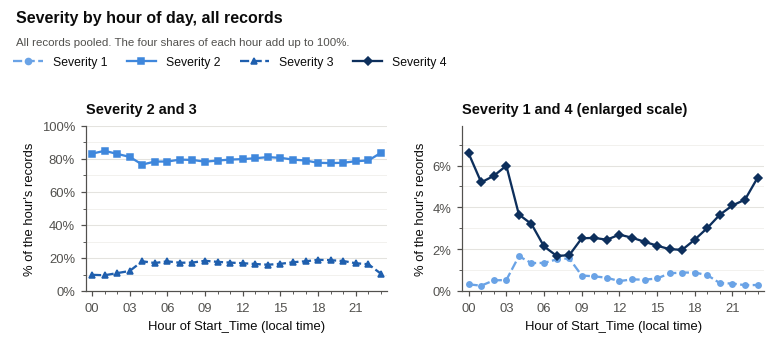

In [61]:
hour_profiles = {g: severity_shares(severity_counts(pd.Series(hour_of_day), m)) for g, m in POPULATIONS.items()}
pooled, source1, source2 = (hour_profiles[g] for g in POPULATIONS)
print(f"All records: Severity 4 from {pooled[4].min():.1f}% ({pooled[4].idxmin():02d}:00) to {pooled[4].max():.1f}% "
      f"({pooled[4].idxmax():02d}:00); Severity 3 lowest at {pooled[3].idxmin():02d}:00 ({pooled[3].min():.1f}%). "
      f"Source2: Severity 3 highest at {source2[3].idxmax():02d}:00 ({source2[3].max():.1f}%). "
      f"Source1: Severity 4 highest at {source1[4].idxmax():02d}:00 ({source1[4].max():.1f}%).")
HOUR_AXIS = dict(ticks=range(0, 24, 3), labels=[f"{h:02d}" for h in range(0, 24, 3)], minor=range(24), limits=(-0.5, 23.5),
                 label="Hour of Start_Time (local time)")
pooled_profile_figure(pooled, HOUR_AXIS, "hour", "Severity by hour of day, all records", "severity_by_hour")

**Finding (all records).** Severity 4 is most common after midnight (6.6% of records at 00:00) and least common in the morning (1.7% at 07:00). Severity 3 is least common at night (9.6% at 01:00), and Severity 1 peaks in the early morning.

**Question:** do these hourly patterns hold within each provider?

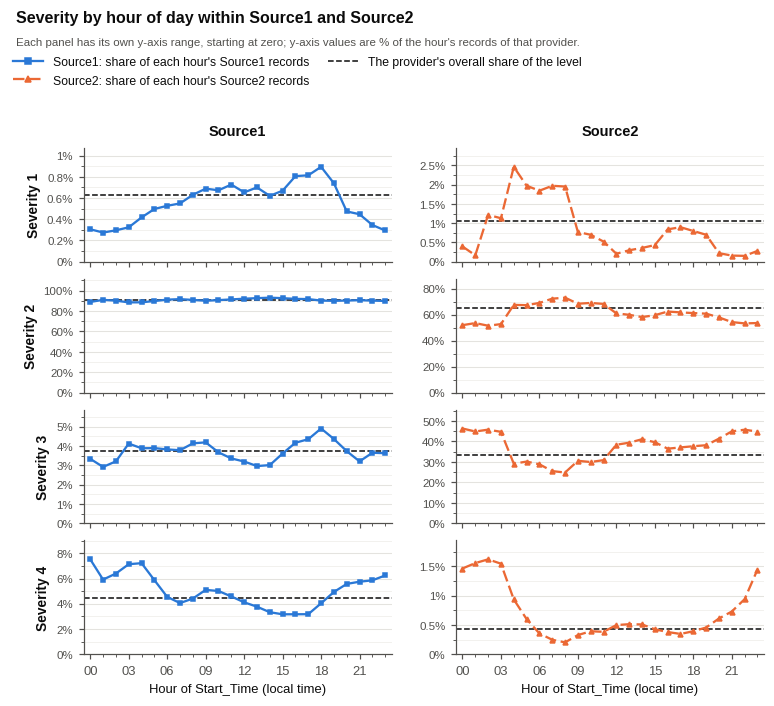

In [62]:
source_profile_figure({s: hour_profiles[s] for s in MAIN_SOURCES}, HOUR_AXIS, "hour",
                      "Severity by hour of day within Source1 and Source2", "severity_by_hour_by_source")

**Finding (within providers).** The Severity 4 night peak appears in both providers (Source1: 7.5% at 00:00). Severity 3 does not follow the pooled curve: within Source2 it is most common at night (46.3% at 00:00). The pooled Severity 3 dip at night therefore reflects how the provider mix changes over the day more than a common hourly pattern. The early-morning Severity 1 peak comes mainly from Source2.

**Question:** does it change with the day of week?

Weekend versus weekdays: All records Severity 3 18.3% vs 16.8%, Severity 4 3.7% vs 2.4%; Source1 Severity 3 2.9% vs 4.0%, Severity 4 4.9% vs 4.3%; Source2 Severity 3 56.0% vs 30.9%, Severity 4 0.8% vs 0.4%


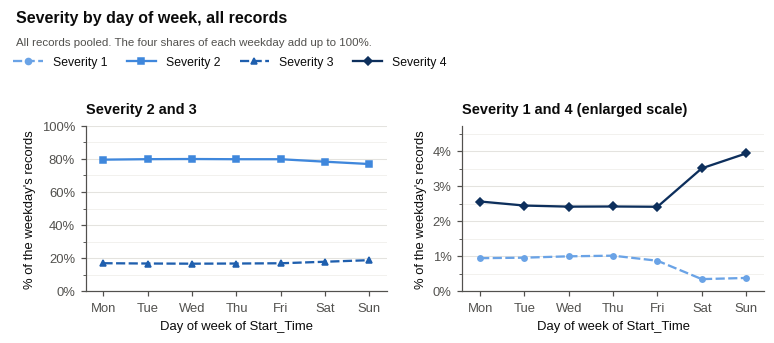

In [63]:
WEEKDAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
is_weekend = weekday >= 5
weekday_profiles = {g: severity_shares(severity_counts(pd.Series(weekday), m)) for g, m in POPULATIONS.items()}
weekend_mix = {g: (mix_of(m & is_weekend), mix_of(m & ~is_weekend)) for g, m in POPULATIONS.items()}
print("Weekend versus weekdays: " + "; ".join(
    f"{g} Severity 3 {weekend_mix[g][0][3]:.1f}% vs {weekend_mix[g][1][3]:.1f}%, Severity 4 {weekend_mix[g][0][4]:.1f}% vs "
    f"{weekend_mix[g][1][4]:.1f}%" for g in POPULATIONS))

WEEKDAY_AXIS = dict(ticks=range(7), labels=WEEKDAYS, minor=[], limits=(-0.4, 6.4), label="Day of week of Start_Time")
pooled_profile_figure(weekday_profiles["All records"], WEEKDAY_AXIS, "weekday", "Severity by day of week, all records",
                      "severity_by_weekday")

**Finding (all records).** Weekends carry more Severity 4 (3.7% of records against 2.4% on weekdays) and less Severity 1.

**Question:** does the weekend pattern hold within each provider?

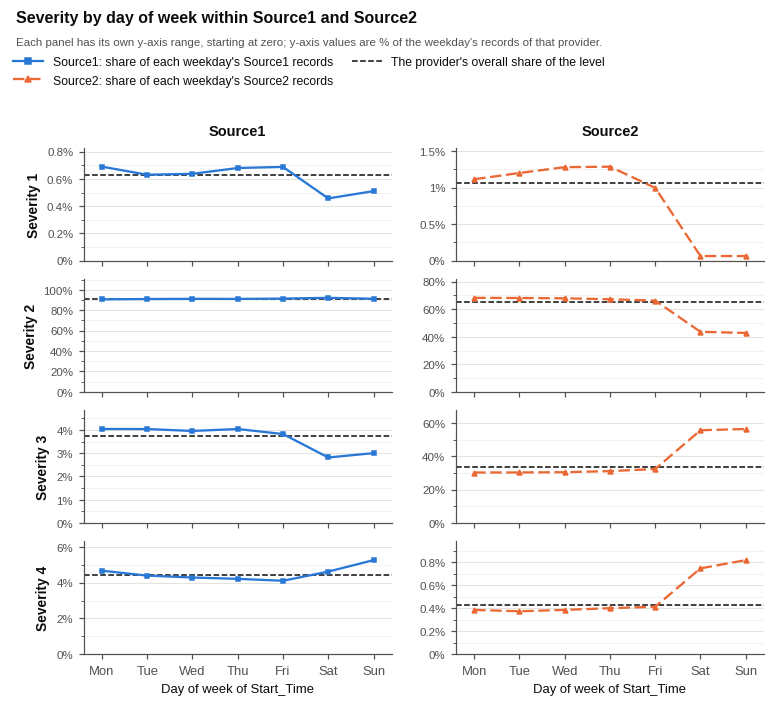

In [64]:
source_profile_figure({s: weekday_profiles[s] for s in MAIN_SOURCES}, WEEKDAY_AXIS, "weekday",
                      "Severity by day of week within Source1 and Source2", "severity_by_weekday_by_source")

**Finding (within providers).** Within Source2, Severity 3 jumps from 30.9% on weekdays to 56.0% at weekends, while within Source1 it falls slightly (4.0% to 2.9%). Severity 4 is higher at weekends in both providers (4.9% against 4.3% within Source1, 0.8% against 0.4% within Source2).

**Question:** do month and year carry a Severity signal of their own?

In [65]:
month_of_year = start_time.dt.month.to_numpy()
TIME_KEYS = {"Hour of day": hour_of_day, "Day of week": weekday, "Month": month_of_year, "Year": start_year.to_numpy()}
time_v = pd.DataFrame({name: {g: cramers_v(severity_counts(pd.Series(key), m)) for g, m in POPULATIONS.items()}
                       for name, key in TIME_KEYS.items()}).T  # summarized in Section 2.3.4
s1_rows = sev_values == 1
s1_windows = between("2020-03-01", "2020-07-01") | between("2022-04-01", "2022-10-01")
print(f"Cramér's V with Severity, all records / Source1 / Source2: month {time_v.at['Month', 'All records']:.3f} / "
      f"{time_v.at['Month', 'Source1']:.3f} / {time_v.at['Month', 'Source2']:.3f}; year {time_v.at['Year', 'All records']:.3f} / "
      f"{time_v.at['Year', 'Source1']:.3f} / {time_v.at['Year', 'Source2']:.3f}")
print(f"Severity 1 records from March–June 2020 or April–September 2022: {100 * (s1_rows & s1_windows).sum() / s1_rows.sum():.1f}% "
      f"of {int(s1_rows.sum()):,}")

Cramér's V with Severity, all records / Source1 / Source2: month 0.074 / 0.092 / 0.072; year 0.186 / 0.243 / 0.221
Severity 1 records from March–June 2020 or April–September 2022: 97.4% of 65,570


**Finding.** Year is strongly associated with `Severity` (V = 0.186), also within each provider (0.243 and 0.221), because each provider's shifts are tied to periods (Section 2.3.1). Severity 1 is concentrated in two periods: 97.4% of its records fall in March–June 2020 or April–September 2022. Month has V = 0.074.

**Limitation.** Hour and weekday are candidate predictors, but their pooled shapes partly reflect provider mix. Month and year mostly track the source and period shifts and should not be read as Severity signals on their own.

#### 2.3.3.2 Weather conditions and measurements

**Question:** does the Severity distribution differ by weather group?

Shares among all records: S1 0.86%, S2 79.5%, S3 17.0%, S4 2.6%. Snow or ice: S1 0.07%, S2 79.7%, S3 16.3%, S4 3.9%; Rain or drizzle: S1 0.62%, S2 76.1%, S3 20.6%, S4 2.6%; Fog, haze or smoke: S1 0.47%, S2 83.2%, S3 14.1%, S4 2.2%


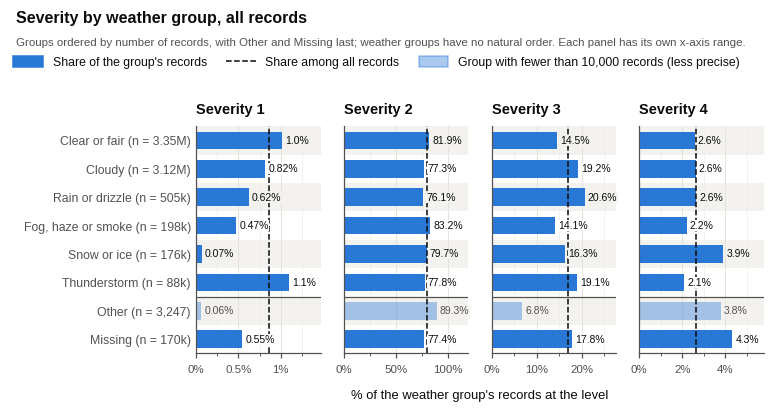

In [66]:
weather_grp_series = pd.Series(weather_grp)
weather_mix = severity_shares(severity_counts(weather_grp_series)).reindex(WEATHER_GROUPS)
# display order: weather groups by number of records (no natural order exists), then "Other" and "Missing"
WEATHER_ORDER = weather_mix["Rows"].drop(["Other", "Missing"]).sort_values(ascending=False).index.tolist() + ["Other", "Missing"]
weather_mix = weather_mix.loc[WEATHER_ORDER]
print("Shares among all records: " + ", ".join(f"S{k} {share_label(overall_mix[k])}%" for k in SEVERITY_LEVELS) + ". "
      + "; ".join(f"{g}: " + ", ".join(f"S{k} {share_label(weather_mix.at[g, k])}%" for k in SEVERITY_LEVELS)
                  for g in ["Snow or ice", "Rain or drizzle", "Fog, haze or smoke"]))

fig, axes = level_bar_panels(len(WEATHER_ORDER))
draw_level_bars(axes, weather_mix, [f"{g} (n = {count_label(n)})" for g, n in weather_mix["Rows"].items()],
                reference_line=overall_mix, separators=[1.5], faint=weather_mix["Rows"] < SMALL_GROUP_ROWS)
top = figure_header(fig, "Severity by weather group, all records",
                    "Groups ordered by number of records, with Other and Missing last; weather groups have no natural order. "
                    "Each panel has its own x-axis range.",
                    handles=[mpl.patches.Patch(label="Share of the group's records", **BAR), reference_handle("Share among all records"),
                             faint_handle()], ncol=3)
finish_layout(fig, axes, top, "% of the weather group's records at the level")
save_figure(fig, "severity_by_weather_group")
plt.show()

**Finding.** The association is weak (V = 0.041). The raw labels reach 0.125, largely because the April 2019 vocabulary change ties labels to periods, and periods to the Severity shifts. Snow or ice goes with almost no Severity 1 (0.07% against 0.86% among all records) and more Severity 4 (3.9% against 2.6%); rain or drizzle carries somewhat more Severity 3 (20.6% against 17.0%).

**Question:** do these weather patterns hold within each provider?

Source1: overall S1 0.63%, S3 3.8%, S4 4.4%; snow or ice S1 0.08%, S4 5.5%; rain or drizzle S3 4.7%; thunderstorm S3 3.8%; Source2: overall S1 1.1%, S3 33.5%, S4 0.43%; snow or ice S1 0.04%, S4 0.64%; rain or drizzle S3 38.9%; thunderstorm S3 42.2%


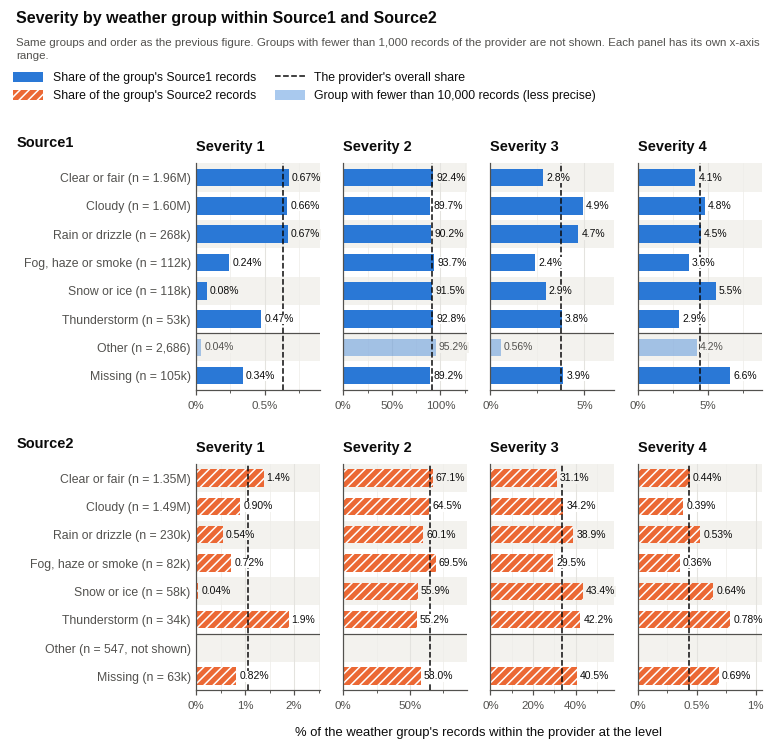

In [67]:
blocks = []
for s in MAIN_SOURCES:
    shares = severity_shares(severity_counts(weather_grp_series, is_source[s])).reindex(WEATHER_ORDER)
    too_few = shares["Rows"] < MIN_GROUP_ROWS
    shares.loc[too_few, SEVERITY_LEVELS] = np.nan  # shown as an empty row
    blocks.append({"name": s, "shares": shares,
                   "reference_line": mix_of(is_source[s]), "bar": SOURCE_BARS[s], "separators": [1.5],
                   "faint": shares["Rows"] < SMALL_GROUP_ROWS,
                   "labels": [f"{g} (n = {count_label(n)}{', not shown' if few else ''})"
                              for (g, n), few in zip(shares["Rows"].items(), too_few)]})
print("; ".join(f"{b['name']}: overall S1 {share_label(b['reference_line'][1])}%, S3 {share_label(b['reference_line'][3])}%, "
                f"S4 {share_label(b['reference_line'][4])}%; snow or ice S1 {share_label(b['shares'].at['Snow or ice', 1])}%, "
                f"S4 {share_label(b['shares'].at['Snow or ice', 4])}%; rain or drizzle S3 {share_label(b['shares'].at['Rain or drizzle', 3])}%; "
                f"thunderstorm S3 {share_label(b['shares'].at['Thunderstorm', 3])}%" for b in blocks))
handles = [mpl.patches.Patch(label=f"Share of the group's {s} records", **SOURCE_BARS[s]) for s in MAIN_SOURCES]
handles += [reference_handle("The provider's overall share"), faint_handle(SOURCE_BARS["Source1"])]
fig, axes = bar_block_figure(blocks, "Severity by weather group within Source1 and Source2",
                             f"Same groups and order as the previous figure. Groups with fewer than {MIN_GROUP_ROWS:,} records of "
                             "the provider are not shown. Each panel has its own x-axis range.", handles,
                             x_label="% of the weather group's records within the provider at the level")
save_figure(fig, "severity_by_weather_group_and_source")
plt.show()

**Finding.** The snow-or-ice pattern (less Severity 1, more Severity 4) appears in both providers, and fog, haze or smoke carries less Severity 1 in both. Rain and thunderstorms carry more Severity 3 within Source2 (38.9% and 42.2%, against 33.5%), while within Source1 the difference is small.

**Question:** do the candidate equivalent labels of Section 2.2.2 relate to Severity alike?

In [68]:
# Candidate equivalent labels (Section 2.2.2) within Source2, next to the average of each label's own period
rows = []
for before_change in (True, False):
    in_period = is_source["Source2"] & ((start_time < WEATHER_FEED_CHANGE) == before_change).to_numpy()
    period = f"{'before' if before_change else 'from'} {WEATHER_FEED_CHANGE:%b %Y}"
    rows.append({"Records": f"All Source2 records, {period}", **mix_of(in_period).to_dict(), "Rows": int(in_period.sum())})
    for pair in LABEL_PAIRS:
        label = pair[0] if before_change else pair[1]
        m = in_period & df["Weather_Condition"].eq(label).to_numpy()
        rows.append({"Records": f"{label} ({period})", **mix_of(m).to_dict(), "Rows": int(m.sum())})
label_check = pd.DataFrame(rows).rename(columns={k: f"Severity {k} (%)" for k in SEVERITY_LEVELS})
show_table(label_check, caption="Candidate equivalent weather labels within Source2, next to their period's average")

Records,Severity 1 (%),Severity 2 (%),Severity 3 (%),Severity 4 (%),Rows
"All Source2 records, before Apr 2019",0.05,64.04,35.83,0.08,"1,703,164"
Clear (before Apr 2019),0.05,65.95,33.92,0.07,"619,100"
Overcast (before Apr 2019),0.04,65.04,34.84,0.08,"290,775"
Thunderstorm (before Apr 2019),0.03,59.56,40.29,0.12,"3,346"
"All Source2 records, from Apr 2019",2.14,66.05,31.01,0.80,"1,600,081"
Fair (from Apr 2019),2.54,68.18,28.53,0.76,"712,977"
Cloudy (from Apr 2019),1.57,66.98,30.67,0.78,"254,743"
T-Storm (from Apr 2019),2.36,54.24,42.21,1.19,"5,795"


**Finding.** Within Source2, each pair sits on the same side of its period's average Severity 3 share: Clear (33.9%) and Fair (28.5%) are both below it, and Thunderstorm (40.3%) and T-Storm (42.2%) both above. This supports, but does not prove, harmonizing them.

**Question:** do the weather measurements differ across Severity levels?

Spearman correlation with Severity: |rho| at most 0.090 for every measurement, in all records and within each large provider
Medians by Severity 1-4: Temperature(F) 74 / 64 / 64.9 / 60.1; Pressure(in) 29.53 / 29.84 / 29.92 / 29.81


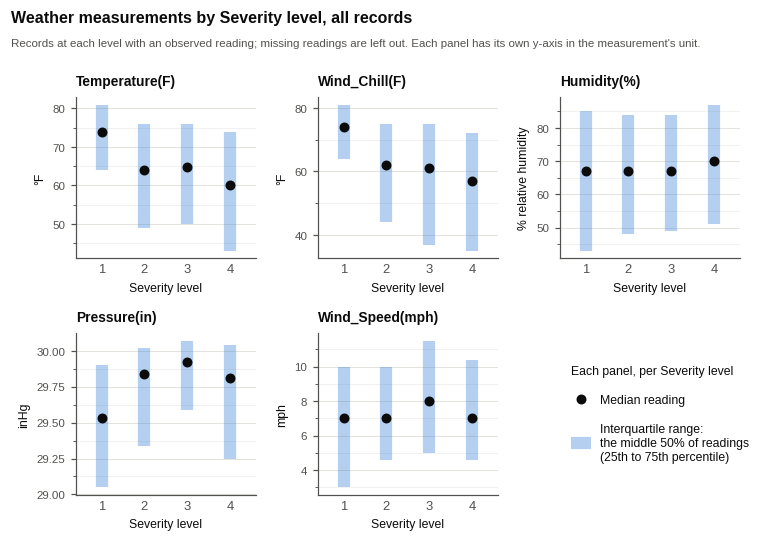

In [69]:
QUANTILE_COLS = ["Temperature(F)", "Wind_Chill(F)", "Humidity(%)", "Pressure(in)", "Wind_Speed(mph)"]
SHARE_MEASURES = {"Precipitation above 0 in": ("Precipitation(in)", lambda v: v > 0),
                  "Visibility below 10 mi": ("Visibility(mi)", lambda v: v < 10),
                  "Calm wind (0 mph)": ("Wind_Speed(mph)", lambda v: v == 0)}
quartiles = {c: pd.DataFrame({k: np.nanquantile(df[c].to_numpy(dtype="float64")[sev_values == k], [0.25, 0.5, 0.75])
                              for k in SEVERITY_LEVELS}, index=["Q1", "Median", "Q3"]) for c in QUANTILE_COLS}
observed_share = pd.DataFrame({name: {k: 100 * test(v[(sev_values == k) & ~np.isnan(v)]).mean() for k in SEVERITY_LEVELS}
                               for name, (c, test) in SHARE_MEASURES.items()
                               for v in [df[c].to_numpy(dtype="float64")]})
numeric_rho = pd.DataFrame({c: {g: pd.Series(df[c].to_numpy(dtype="float64")[m]).corr(pd.Series(sev_values[m], dtype="float64"),
                                                                                         method="spearman")
                                for g, m in POPULATIONS.items()}
                            for c in QUANTILE_COLS + ["Precipitation(in)", "Visibility(mi)"]}).T  # summarized in Section 2.3.4
print(f"Spearman correlation with Severity: |rho| at most {numeric_rho.abs().max().max():.3f} for every measurement, "
      "in all records and within each large provider")
print("Medians by Severity 1-4: " + "; ".join(f"{c} " + " / ".join(f"{quartiles[c].at['Median', k]:g}" for k in SEVERITY_LEVELS)
                                              for c in ["Temperature(F)", "Pressure(in)"]))

IQR_BAR = dict(color=COLORS["primary"], alpha=0.35, linewidth=8)
MEDIAN_DOT = dict(color=COLORS["ink"], marker="o", markersize=5.5, linestyle="none")
fig, axes = plt.subplots(2, 3, figsize=(7.0, 4.9))
for ax, c in zip(axes.flat, QUANTILE_COLS):
    q = quartiles[c]
    ax.vlines(SEVERITY_LEVELS, q.loc["Q1"], q.loc["Q3"], zorder=2, capstyle="butt", **IQR_BAR)
    ax.plot(SEVERITY_LEVELS, q.loc["Median"], zorder=3, **MEDIAN_DOT)
    ax.yaxis.set_major_locator(mticker.MaxNLocator(5, steps=[1, 2, 2.5, 5, 10]))
    ax.yaxis.set_minor_locator(mticker.AutoMinorLocator(2))
    value_grid(ax, "y")
    ax.set_xticks(SEVERITY_LEVELS)
    ax.set_xlim(0.4, 4.6)
    ax.tick_params(axis="x", length=0)
    ax.tick_params(axis="y", labelsize=7.5)
    ax.set_title(c, fontsize=9)
    ax.set_ylabel(MEASUREMENT_UNITS[c], fontsize=8)
    ax.set_xlabel("Severity level", fontsize=8)
key = axes.flat[5]
key.axis("off")
key.legend(handles=[mpl.lines.Line2D([], [], label="Median reading", **MEDIAN_DOT),
                    mpl.lines.Line2D([], [], label="Interquartile range:\nthe middle 50% of readings\n(25th to 75th percentile)",
                                     solid_capstyle="butt", **IQR_BAR)],
           loc="center left", fontsize=8, handlelength=1.6, labelspacing=1.4, title="Each panel, per Severity level",
           title_fontsize=8, alignment="left")
top = figure_header(fig, "Weather measurements by Severity level, all records",
                    "Records at each level with an observed reading; missing readings are left out. Each panel has its own "
                    "y-axis in the measurement's unit.")
fig.tight_layout(rect=(0, 0, 1, top), h_pad=1.2, w_pad=1.5)
save_figure(fig, "weather_measurements_by_severity")
plt.show()

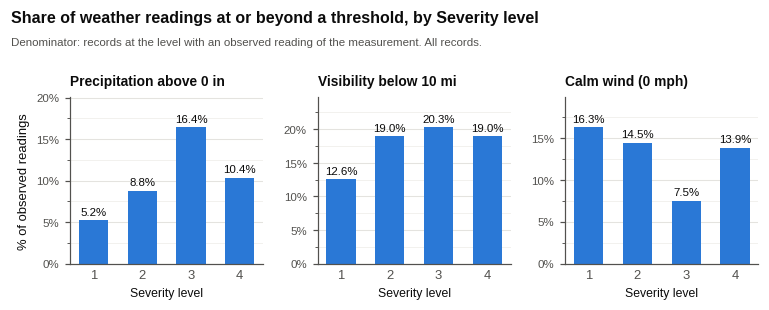

In [70]:
fig, axes = plt.subplots(1, 3, figsize=(7.0, 2.8))
for ax, (name, values) in zip(axes, observed_share.items()):
    ax.bar(SEVERITY_LEVELS, values, width=0.6, zorder=2, **BAR)
    for k, v in values.items():
        ax.annotate(f"{v:.1f}%", (k, v), xytext=(0, 2), textcoords="offset points", ha="center", va="bottom", fontsize=7.5)
    ax.set_ylim(0, values.max() * 1.22)
    percent_axis(ax.yaxis, n_ticks=5)
    value_grid(ax, "y")
    ax.set_xticks(SEVERITY_LEVELS)
    ax.tick_params(axis="x", length=0)
    ax.tick_params(axis="y", labelsize=7.5)
    ax.set_title(name, fontsize=9)
    ax.set_xlabel("Severity level", fontsize=8)
axes[0].set_ylabel("% of observed readings", fontsize=8.5)
top = figure_header(fig, "Share of weather readings at or beyond a threshold, by Severity level",
                    "Denominator: records at the level with an observed reading of the measurement. All records.")
fig.tight_layout(rect=(0, 0, 1, top), w_pad=1.5)
save_figure(fig, "weather_reading_shares_by_severity")
plt.show()

**Finding.** Monotonic associations are weak (|ρ| ≤ 0.09 for every measurement, in all records and within each provider), but the levels differ in specific ways. Severity 1 records are warmer (median 74 °F against 64 °F for Severity 2) and have lower pressure (29.53 against 29.84 inHg). Severity 3 records more often have measurable precipitation (16.4% against 8.8% for Severity 2) and less often calm wind (7.5% against 14.5%). Severity 4 records are the coldest (median 60.1 °F).

**Limitation.** The Severity 1 differences are probably not a weather effect: almost all Severity 1 records fall in spring and summer months of 2020 and 2022 (Section 2.3.3.1), and Arizona, the state with the highest Severity 1 share (Section 2.3.3.3), lies at higher elevation than most, which lowers station pressure. Weather relationships need to be checked within season, location and period.

**Question:** do the retained extreme values of Section 1.3.7 have an unusual Severity distribution?

Records per tail: 235 to 1,462. Severity 4 in the distance, pressure and wind-speed tails: 16.1%, 5.8%, 5.4%; Severity 3 in the precipitation and humidity tails: 38.2%, 7.7%


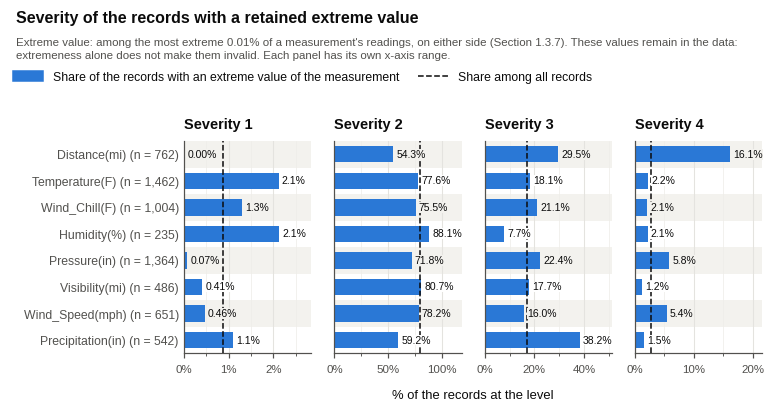

In [71]:
# Retained extreme values (Section 1.3.7): the most extreme 0.01% on each side of every measurement
tails = {}
for c in MEASUREMENT_COLS:
    lo, hi = df[c].quantile([FAR_TAIL, 1 - FAR_TAIL])
    tails[c] = ((df[c] < lo) | (df[c] > hi)).to_numpy()
tail_mix = pd.DataFrame({c: mix_of(m) for c, m in tails.items()}).T.assign(Rows=[int(m.sum()) for m in tails.values()])
print(f"Records per tail: {tail_mix['Rows'].min():,} to {tail_mix['Rows'].max():,}. Severity 4 in the distance, pressure and "
      f"wind-speed tails: {tail_mix.at['Distance(mi)', 4]:.1f}%, {tail_mix.at['Pressure(in)', 4]:.1f}%, "
      f"{tail_mix.at['Wind_Speed(mph)', 4]:.1f}%; Severity 3 in the precipitation and humidity tails: "
      f"{tail_mix.at['Precipitation(in)', 3]:.1f}%, {tail_mix.at['Humidity(%)', 3]:.1f}%")


fig, axes = level_bar_panels(len(tail_mix))
draw_level_bars(axes, tail_mix, [f"{c} (n = {n:,})" for c, n in tail_mix["Rows"].items()], reference_line=overall_mix)
top = figure_header(fig, "Severity of the records with a retained extreme value",
                    "Extreme value: among the most extreme 0.01% of a measurement's readings, on either side (Section 1.3.7). These "
                    "values remain in the data: extremeness alone does not make them invalid. Each panel has its own x-axis range.",
                    handles=[mpl.patches.Patch(label="Share of the records with an extreme value of the measurement", **BAR),
                             reference_handle("Share among all records")])
finish_layout(fig, axes, top, "% of the records at the level")
save_figure(fig, "severity_of_extreme_values")
plt.show()

**Finding.** Most tails differ only modestly from all records, and each tail holds only 235 to 1,462 records. The largest differences are more Severity 4 in the distance tail (16.1%, against 2.6% among all records) and more Severity 3 in the precipitation tail (38.2%, against 17.0%); the humidity tail has less Severity 3 (7.7%). Whether these tails reflect particular stations remains open.

#### 2.3.3.3 Geographic factors

**Question:** does the Severity distribution vary across states? The figure shows the 15 largest of the 26 states with at least 20,000 records from each large provider; together they hold 78.7% of all records.

26 states have at least 20,000 records from each large provider; the 15 largest hold 78.7% of all records
Range across the states shown: Severity 1 0.26% (MN) to 4.10% (AZ); Severity 2 55.04% (GA) to 90.52% (OR); Severity 3 5.54% (OR) to 36.79% (GA); Severity 4 0.45% (MN) to 7.58% (GA)


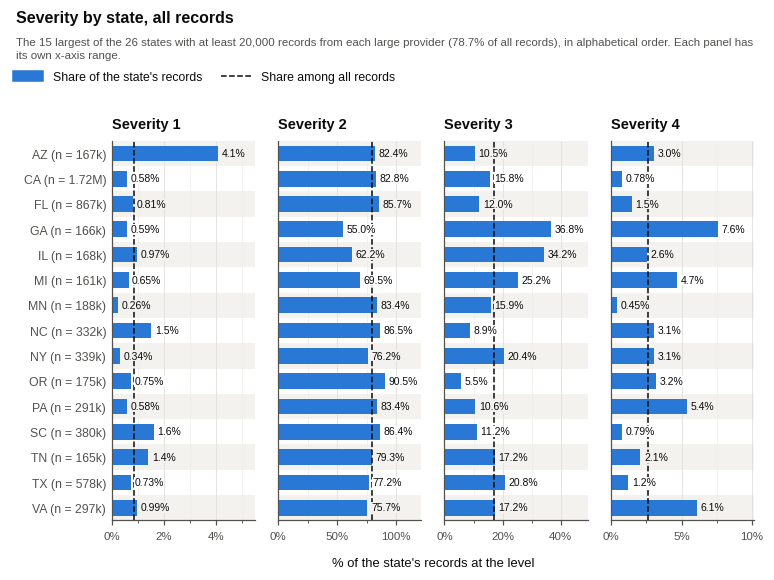

In [72]:
# States shown: the 15 largest among those with at least 20,000 records from each of Source1 and Source2
STATE_MIN_ROWS, STATES_SHOWN = 20_000, 15
state_rows = {g: df.loc[m, "State"].value_counts() for g, m in POPULATIONS.items()}
eligible = [s for s in state_rows["All records"].index
            if min(state_rows[p].get(s, 0) for p in MAIN_SOURCES) >= STATE_MIN_ROWS]
states_shown = eligible[:STATES_SHOWN]
state_shares = {g: severity_shares(severity_counts(df["State"], m)).reindex(states_shown) for g, m in POPULATIONS.items()}
print(f"{len(eligible)} states have at least {STATE_MIN_ROWS:,} records from each large provider; the {len(states_shown)} largest "
      f"hold {100 * state_rows['All records'][states_shown].sum() / n_clean:.1f}% of all records")

pooled_states = state_shares["All records"]
print("Range across the states shown: " + "; ".join(
    f"Severity {k} {pooled_states[k].min():.2f}% ({pooled_states[k].idxmin()}) to {pooled_states[k].max():.2f}% "
    f"({pooled_states[k].idxmax()})" for k in SEVERITY_LEVELS))
STATE_ORDER = sorted(states_shown)  # alphabetical: states have no natural order
fig, axes = level_bar_panels(len(STATE_ORDER), row_height=0.24)
draw_level_bars(axes, pooled_states.loc[STATE_ORDER],
                [f"{s} (n = {count_label(n)})" for s, n in pooled_states.loc[STATE_ORDER, "Rows"].items()], reference_line=overall_mix)
top = figure_header(fig, "Severity by state, all records",
                    f"The {len(states_shown)} largest of the {len(eligible)} states with at least {STATE_MIN_ROWS:,} records from "
                    f"each large provider ({100 * state_rows['All records'][states_shown].sum() / n_clean:.1f}% of all records), in "
                    "alphabetical order. Each panel has its own x-axis range.",
                    handles=[mpl.patches.Patch(label="Share of the state's records", **BAR), reference_handle("Share among all records")])
finish_layout(fig, axes, top, "% of the state's records at the level")
save_figure(fig, "severity_by_state")
plt.show()

**Finding.** All four levels vary by state (V = 0.144). Among the states shown, Severity 1 ranges from 0.26% (Minnesota) to 4.1% (Arizona), Severity 3 from 5.5% (Oregon) to 36.8% (Georgia) and Severity 4 from 0.45% (Minnesota) to 7.6% (Georgia).

**Question:** is the state pattern the same in both providers?

Spearman correlation of the providers' state shares: Severity 1 -0.05, Severity 2 0.21, Severity 3 0.47, Severity 4 0.50. Arizona, Severity 1: Source1 6.90%, Source2 0.88%. Oregon records from Source1: 85.9%


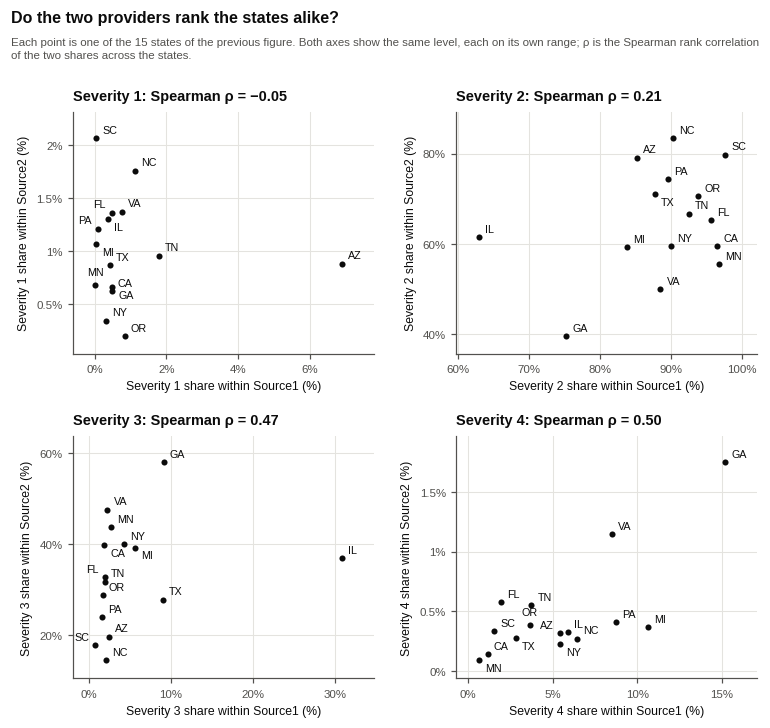

In [73]:
rank_rho = {k: state_shares["Source1"][k].corr(state_shares["Source2"][k], method="spearman") for k in SEVERITY_LEVELS}
print("Spearman correlation of the providers' state shares: " + ", ".join(f"Severity {k} {v:.2f}" for k, v in rank_rho.items())
      + f". Arizona, Severity 1: Source1 {state_shares['Source1'].at['AZ', 1]:.2f}%, Source2 {state_shares['Source2'].at['AZ', 1]:.2f}%. "
      f"Oregon records from Source1: {100 * state_rows['Source1']['OR'] / state_rows['All records']['OR']:.1f}%")

NEAR = [(4, 2), (4, -2), (-4, 2), (-4, -2), (0, 5), (0, -5), (7, 0), (-7, 0)]  # label offsets in points
FAR = [(dx * f, dy * f) for f in (2.2, 3.6) for dx, dy in [(4, 4), (4, -4), (-4, 4), (-4, -4), (0, 5), (0, -5), (6, 0), (-6, 0)]]


def overlap_area(a, b):
    """Area shared by two boxes (0 if they are disjoint)."""
    return max(min(a.x1, b.x1) - max(a.x0, b.x0), 0) * max(min(a.y1, b.y1) - max(a.y0, b.y0), 0)


def label_points(ax, xs, ys, labels):
    """Label every point without overlaps: positions next to the point are tried first, then farther ones joined to the
    point by a thin leader line; a label must stay inside the axes and clear of every point and earlier label. Points
    with the most close neighbours are labelled first. Call after the final layout, since labels are measured on the canvas.
    Fonts and renderers measure text slightly differently, so a position free in one environment can be taken in another.
    If no position is free, the label goes where the least of it lies outside the axes, then where it overlaps least (the
    earlier position on a tie), on a white background beneath the points so that no point is hidden, instead of failing."""
    frame = ax.get_window_extent()
    points = ax.transData.transform(np.column_stack([xs, ys]))
    taken = [mpl.transforms.Bbox.from_bounds(px - 3, py - 3, 6, 6) for px, py in points]
    crowding = [(np.hypot(*(points - p).T) < 30).sum() for p in points]

    def annotate(i, dx, dy, zorder=4, **style):
        leader = dict(arrowstyle="-", color=COLORS["muted"], linewidth=0.5, shrinkA=0, shrinkB=2) if (dx, dy) in FAR else None
        return ax.annotate(labels[i], (xs[i], ys[i]), xytext=(dx, dy), textcoords="offset points",
                           ha="left" if dx > 0 else "right" if dx < 0 else "center",
                           va="bottom" if dy > 0 else "top" if dy < 0 else "center",
                           fontsize=7, color=COLORS["ink"], zorder=zorder, arrowprops=leader, **style)

    for i in np.argsort(crowding)[::-1]:
        others = [b for j, b in enumerate(taken) if j != i]
        misses = []
        for n, (dx, dy) in enumerate(NEAR + FAR):
            label = annotate(i, dx, dy)
            box = label.get_window_extent()
            if (frame.x0 <= box.x0 and box.x1 <= frame.x1 and frame.y0 <= box.y0 and box.y1 <= frame.y1
                    and not any(box.overlaps(b) for b in others)):
                taken.append(box)
                break
            misses.append((box.width * box.height - overlap_area(box, frame), sum(overlap_area(box, b) for b in others), n))
            label.remove()
        else:  # no free position
            label = annotate(i, *(NEAR + FAR)[min(misses)[2]], zorder=2.9,
                             bbox=dict(boxstyle="square,pad=0.1", facecolor="white", edgecolor="none"))
            taken.append(label.get_window_extent())


fig, axes = plt.subplots(2, 2, figsize=(7.0, 6.6))
for ax, k in zip(axes.flat, SEVERITY_LEVELS):
    x, y = state_shares["Source1"][k], state_shares["Source2"][k]
    ax.scatter(x, y, s=16, color=COLORS["ink"], linewidths=0, zorder=3)
    for axis, v in ((ax.xaxis, x), (ax.yaxis, y)):  # margins around the points leave room for labels; ticks only at 0% or more
        span = v.max() - v.min()
        low, high = v.min() - 0.09 * span, v.max() + 0.13 * span
        (ax.set_xlim if axis is ax.xaxis else ax.set_ylim)(low, high)
        ticks = mticker.MaxNLocator(5, steps=[1, 2, 5, 10]).tick_values(max(low, 0), high)
        axis.set_major_locator(mticker.FixedLocator([t for t in ticks if max(low, 0) <= t <= high]))
        axis.set_major_formatter(mticker.FuncFormatter(lambda t, _: f"{t:g}%"))
        axis.set_minor_locator(mticker.NullLocator())
    value_grid(ax, "both")
    ax.tick_params(labelsize=7.5)
    ax.set_title(f"Severity {k}: Spearman ρ = {rank_rho[k]:.2f}".replace("-", "−"), fontsize=9.5)
    ax.set_xlabel(f"Severity {k} share within Source1 (%)", fontsize=8)
    ax.set_ylabel(f"Severity {k} share within Source2 (%)", fontsize=8)
top = figure_header(fig, "Do the two providers rank the states alike?",
                    f"Each point is one of the {len(states_shown)} states of the previous figure. Both axes show the same level, "
                    "each on its own range; ρ is the Spearman rank correlation of the two shares across the states.")
fig.tight_layout(rect=(0, 0, 1, top), h_pad=1.5, w_pad=2.0)
fig.canvas.draw()
for ax, k in zip(axes.flat, SEVERITY_LEVELS):
    label_points(ax, state_shares["Source1"][k].to_numpy(), state_shares["Source2"][k].to_numpy(), states_shown)
save_figure(fig, "state_pattern_by_source")
plt.show()

**Finding.** Only partly. The state rankings agree moderately for Severity 3 and 4 (Spearman ρ = 0.47 and 0.50; Georgia is high and Minnesota low in both providers) but not for Severity 1 and 2 (ρ = −0.05 and 0.21). Arizona's high Severity 1 share appears only within Source1 (6.9% against 0.88% within Source2). The pooled state view also mixes provider coverage: 85.9% of Oregon's records come from Source1, which records little Severity 3, so Oregon's low pooled Severity 3 share partly reflects the provider.

**Question:** how much do the high-cardinality location fields vary?

In [74]:
# High-cardinality location fields are characterized, not encoded
city_counts = df["City"].value_counts()
big_cities = city_counts.index[city_counts >= MIN_GROUP_ROWS]
city_shares = severity_shares(severity_counts(df["City"].where(df["City"].isin(big_cities))))
print(f"{len(big_cities):,} cities with at least {MIN_GROUP_ROWS:,} records hold {100 * city_counts[big_cities].sum() / n_clean:.0f}% "
      "of records. 10th to 90th percentile of each level across them: "
      + "; ".join(f"Severity {k} {city_shares[k].quantile(0.1):.1f}% to {city_shares[k].quantile(0.9):.1f}%" for k in SEVERITY_LEVELS))

1,203 cities with at least 1,000 records hold 82% of records. 10th to 90th percentile of each level across them: Severity 1 0.1% to 1.8%; Severity 2 61.6% to 96.9%; Severity 3 1.0% to 35.1%; Severity 4 0.4% to 6.0%


**Finding.** Cities with at least 1,000 records hold 82% of records, and their Severity shares vary widely (Severity 3 from 1.0% to 35.1% between the 10th and 90th percentile). `City`, `County`, `Street` and `Zipcode` are characterized here, not encoded; the road class derived from `Street` is examined next.

#### 2.3.3.4 Road and daylight context

**Question:** does the Severity distribution differ when a road feature is present, or on an interstate?

With vs without the feature: Traffic_Signal S1 2.26% vs 0.62%, S3 7.8% vs 18.6%, S4 1.74% vs 2.81%; Crossing S1 2.10% vs 0.70%, S3 5.5% vs 18.5%, S4 1.53% vs 2.79%; Junction S1 0.53% vs 0.89%, S3 23.5% vs 16.5%, S4 3.61% vs 2.57%; Interstate S1 0.35% vs 1.03%, S3 33.9% vs 11.4%, S4 2.54% vs 2.68%


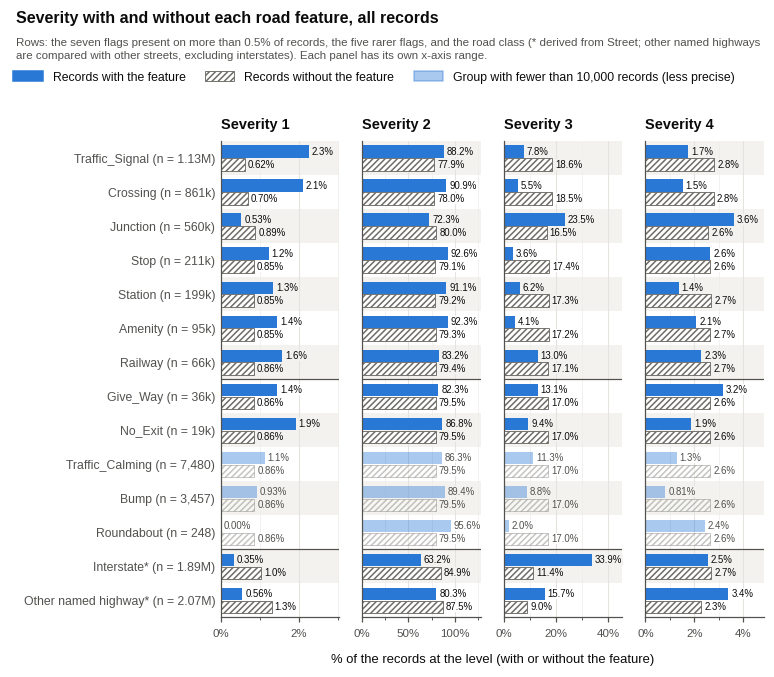

In [75]:
# Each row compares records with the feature to records without it; the road class is read from Street
ROAD_ROWS = {c: (df[c].to_numpy(dtype=bool), ~df[c].to_numpy(dtype=bool))
             for c in road_features.sort_values("Share (%)", ascending=False)["Column"]}
ROAD_ROWS["Interstate (from Street)"] = (is_interstate, ~is_interstate)
ROAD_ROWS["Other named highway (from Street)"] = (is_highway, ~is_interstate & ~is_highway)  # against other streets
road_with, road_without, road_support = contrast(ROAD_ROWS)
print("With vs without the feature: " + "; ".join(
    f"{name.replace(' (from Street)', '')} S1 {road_with.at[name, 1]:.2f}% vs {road_without.at[name, 1]:.2f}%, "
    f"S3 {road_with.at[name, 3]:.1f}% vs {road_without.at[name, 3]:.1f}%, S4 {road_with.at[name, 4]:.2f}% vs {road_without.at[name, 4]:.2f}%"
    for name in ["Traffic_Signal", "Crossing", "Junction", "Interstate (from Street)"]))


def context_label(name, n):
    """Row label with the number of records that have the feature; a star marks the road class derived from Street."""
    return f"{name.replace(' (from Street)', '*')} (n = {count_label(n)})"


fig, axes = level_bar_panels(len(ROAD_ROWS), row_height=0.32)
draw_level_bars(axes, road_with, [context_label(name, n) for name, n in road_support.items()], comparison=road_without,
                separators=[6.5, 1.5], faint=road_support < SMALL_GROUP_ROWS)
top = figure_header(fig, "Severity with and without each road feature, all records",
                    "Rows: the seven flags present on more than 0.5% of records, the five rarer flags, and the road class "
                    "(* derived from Street; other named highways are compared with other streets, excluding interstates). Each "
                    "panel has its own x-axis range.",
                    handles=[mpl.patches.Patch(label="Records with the feature", **BAR),
                             mpl.patches.Patch(label="Records without the feature", **COMPARISON_BAR), faint_handle()], ncol=3)
finish_layout(fig, axes, top, "% of the records at the level (with or without the feature)")
save_figure(fig, "severity_by_road_feature")
plt.show()

**Finding.**

- **Traffic signals and crossings** go with more Severity 1 (2.3% and 2.1%, against 0.6% and 0.7% without) and less Severity 3 and 4.
- **Junctions** go with more Severity 3 (23.5% against 16.5%) and more Severity 4.
- **Interstates** show the largest difference: Severity 3 is 33.9% on interstates against 11.4% elsewhere.
- **Rare flags** (`Roundabout` with 248 records, `Bump`, `Traffic_Calming`, `No_Exit`) show large relative differences on small support. Their estimates are imprecise, but rarity alone is not a reason to exclude them.

**Question:** does Severity differ at night, and does the daylight definition matter?

Night vs day: Sunrise_Sunset S1 0.51% vs 1.01%, S4 3.54% vs 2.23%; Civil_Twilight S1 0.46% vs 1.00%, S4 3.77% vs 2.23%; Nautical_Twilight S1 0.42% vs 0.98%, S4 4.10% vs 2.24%; Astronomical_Twilight S1 0.36% vs 0.96%, S4 4.36% vs 2.27%


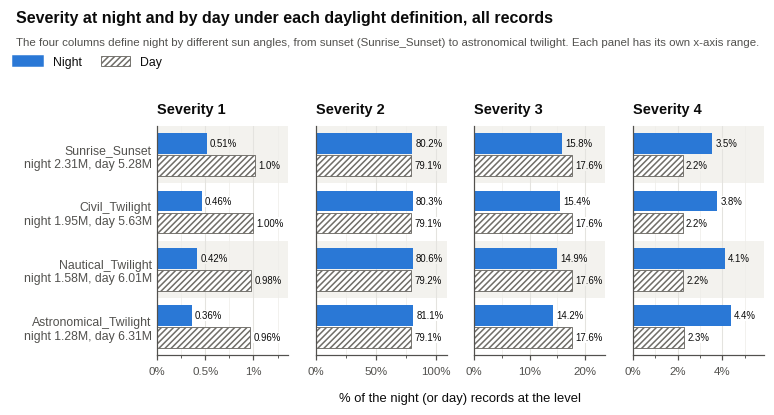

In [76]:
NIGHT_ROWS = {c: (df[c].eq("Night").to_numpy(), df[c].eq("Day").to_numpy()) for c in DAYLIGHT_COLS}
night_mix, day_mix, night_support = contrast(NIGHT_ROWS)
print("Night vs day: " + "; ".join(f"{c} S1 {night_mix.at[c, 1]:.2f}% vs {day_mix.at[c, 1]:.2f}%, S4 {night_mix.at[c, 4]:.2f}% vs "
                                  f"{day_mix.at[c, 4]:.2f}%" for c in DAYLIGHT_COLS))

day_support = pd.Series({c: int(no.sum()) for c, (_, no) in NIGHT_ROWS.items()})
fig, axes = level_bar_panels(len(NIGHT_ROWS), row_height=0.5, extra=1.7)
draw_level_bars(axes, night_mix, [f"{c}\nnight {count_label(night_support[c])}, day {count_label(day_support[c])}"
                                  for c in DAYLIGHT_COLS], comparison=day_mix)
top = figure_header(fig, "Severity at night and by day under each daylight definition, all records",
                    "The four columns define night by different sun angles, from sunset (Sunrise_Sunset) to astronomical "
                    "twilight. Each panel has its own x-axis range.",
                    handles=[mpl.patches.Patch(label="Night", **BAR), mpl.patches.Patch(label="Day", **COMPARISON_BAR)])
finish_layout(fig, axes, top, "% of the night (or day) records at the level")
save_figure(fig, "severity_by_daylight")
plt.show()

**Finding.** Night goes with less Severity 1 (0.51% against 1.01% by day) and more Severity 4 (3.5% against 2.2%, sunrise/sunset definition). The Severity 4 gap widens from the sunrise/sunset to the astronomical-twilight definition (4.4% at night), so the four indicators carry largely overlapping information.

**Question:** do the road and night patterns hold within each provider?

Source1, with vs without: interstate S3 5.4% vs 3.1%, S4 3.44% vs 4.83%; traffic signal S1 3.33% vs 0.36%, S3 4.8% vs 3.7%; junction S3 8.2% vs 3.3%; night S4 5.37% vs 3.92%
Source2, with vs without: interstate S3 79.4% vs 20.9%, S4 1.14% vs 0.24%; traffic signal S1 1.66% vs 0.89%, S3 9.2% vs 40.4%; junction S3 57.6% vs 32.2%; night S4 0.62% vs 0.36%


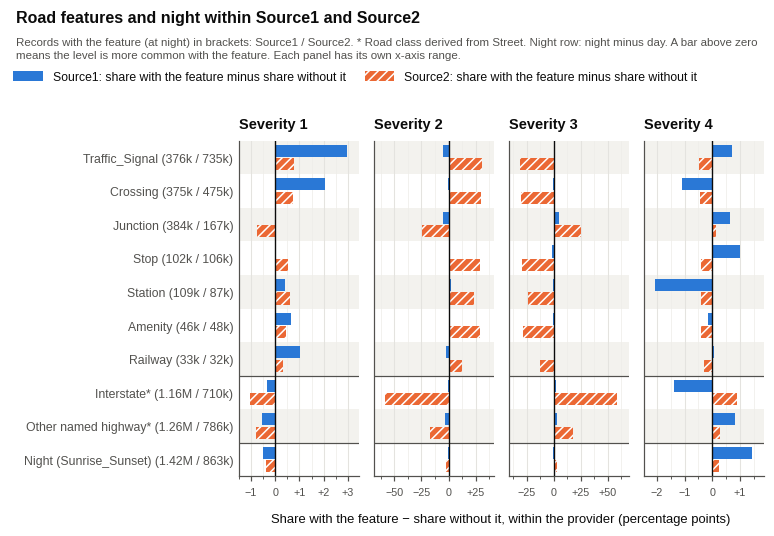

In [77]:
CONTEXT_ROWS = {**{c: ROAD_ROWS[c] for c in list(ROAD_ROWS)[:7]},  # the seven flags present on more than 0.5% of records
                "Interstate (from Street)": ROAD_ROWS["Interstate (from Street)"],
                "Other named highway (from Street)": ROAD_ROWS["Other named highway (from Street)"],
                "Night (Sunrise_Sunset)": NIGHT_ROWS["Sunrise_Sunset"]}
context_gap, context_support = {}, {}
for s in MAIN_SOURCES:
    with_s, without_s, support_s = contrast(CONTEXT_ROWS, is_source[s])
    print(f"{s}, with vs without: interstate S3 {with_s.at['Interstate (from Street)', 3]:.1f}% vs "
          f"{without_s.at['Interstate (from Street)', 3]:.1f}%, S4 {with_s.at['Interstate (from Street)', 4]:.2f}% vs "
          f"{without_s.at['Interstate (from Street)', 4]:.2f}%; traffic signal S1 {with_s.at['Traffic_Signal', 1]:.2f}% vs "
          f"{without_s.at['Traffic_Signal', 1]:.2f}%, S3 {with_s.at['Traffic_Signal', 3]:.1f}% vs {without_s.at['Traffic_Signal', 3]:.1f}%; "
          f"junction S3 {with_s.at['Junction', 3]:.1f}% vs {without_s.at['Junction', 3]:.1f}%; night S4 "
          f"{with_s.at['Night (Sunrise_Sunset)', 4]:.2f}% vs {without_s.at['Night (Sunrise_Sunset)', 4]:.2f}%")
    context_gap[s], context_support[s] = with_s - without_s, support_s  # percentage points

fig, axes = level_bar_panels(len(CONTEXT_ROWS), row_height=0.32)
draw_difference_bars(axes, context_gap, [f"{name.replace(' (from Street)', '*')} ({count_label(context_support['Source1'][name])} / "
                                         f"{count_label(context_support['Source2'][name])})" for name in CONTEXT_ROWS],
                     {s: SOURCE_BARS[s] for s in MAIN_SOURCES}, separators=[2.5, 0.5])
top = figure_header(fig, "Road features and night within Source1 and Source2",
                    "Records with the feature (at night) in brackets: Source1 / Source2. * Road class derived from Street. Night "
                    "row: night minus day. A bar above zero means the level is more common with the feature. Each panel has its "
                    "own x-axis range.",
                    handles=[mpl.patches.Patch(label=f"{s}: share with the feature minus share without it", **SOURCE_BARS[s])
                             for s in MAIN_SOURCES], ncol=2)
finish_layout(fig, axes, top, "Share with the feature − share without it, within the provider (percentage points)")
save_figure(fig, "road_and_daylight_by_source")
plt.show()

**Finding.** Several directions hold in both providers: more Severity 1 at traffic signals and crossings, more Severity 3 at junctions and more Severity 4 at night. The strength often differs sharply. On interstates Severity 3 is 79.4% against 20.9% within Source2 (V = 0.515) but 5.4% against 3.1% within Source1 (V = 0.061), and Severity 4 goes in opposite directions (more on Source2 interstates, less on Source1 interstates). At traffic signals Severity 3 falls from 40.4% to 9.2% within Source2 but is slightly higher within Source1 (4.8% against 3.7%).

**Limitation.** Road context is among the strongest bivariate signals, but its strength, and for some levels its direction, depends on the provider.

#### 2.3.3.5 Missingness

**Question:** is missingness itself associated with Severity, and does the association survive on each side of the April 2019 missingness break (Section 2.2.3)? The missing values are still missing in the analysis dataset; this subsection studies them before any model-dependent treatment, such as imputation or missing-value indicators, is chosen. Missing end coordinates are left out of the figure: they are missing for whole providers, which is a different mechanism (Section 2.2.3).

Wind_Chill(F) missing, Severity 3 with the value missing vs present: All records 30.1% vs 12.4%; Before Apr 2019 31.9% vs 32.1%; From Apr 2019 9.5% vs 10.8%
From Apr 2019, Severity 4 with the value missing vs present: Wind_Chill(F) 3.7% vs 2.4% (160,462 records); Precipitation(in) 3.0% vs 2.4% (234,948 records); Wind_Speed(mph) 3.8% vs 2.4% (143,645 records); No matched weather observation 4.3% vs 2.4% (90,180 records); Daylight indicators 9.9% vs 2.4% (22,636 records); Location text field 4.6% vs 2.4% (29,176 records)


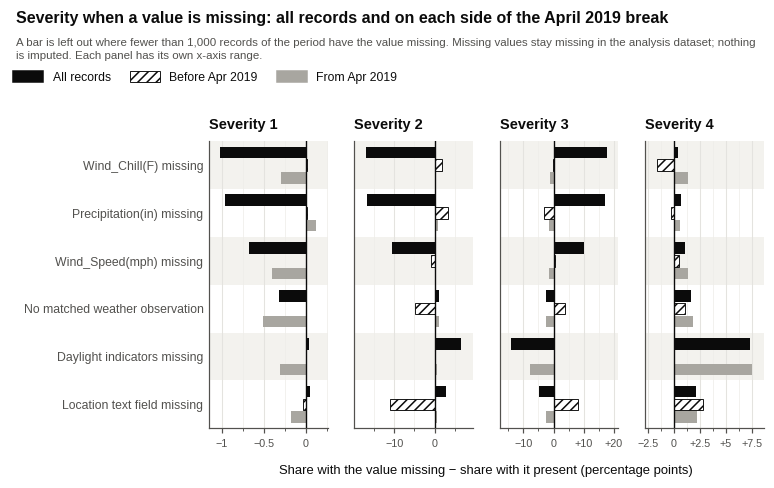

Records with end coordinates, by Severity level: Severity 1 40.3%, Severity 2 63.5%, Severity 3 12.2%, Severity 4 92.8% (the indicator is fixed within each source; Section 2.2.3)


In [78]:
LOCATION_TEXT_COLS = ["Street", "City", "Zipcode", "Timezone", "Airport_Code"]
missing_flag = {f"{c} missing": df[c].isna().to_numpy() for c in ["Wind_Chill(F)", "Precipitation(in)", "Wind_Speed(mph)"]}
missing_flag["No matched weather observation"] = df["Weather_Timestamp"].isna().to_numpy()
missing_flag["Daylight indicators missing"] = df["Sunrise_Sunset"].isna().to_numpy()
missing_flag["Location text field missing"] = df[LOCATION_TEXT_COLS].isna().any(axis=1).to_numpy()
MISSING_ROWS = {name: (flag, ~flag) for name, flag in missing_flag.items()}
before_break = (start_time < MISSINGNESS_BREAK).to_numpy()
MISSING_PERIODS = {"All records": everything, f"Before {MISSINGNESS_BREAK:%b %Y}": before_break,
                   f"From {MISSINGNESS_BREAK:%b %Y}": ~before_break}
missing_contrast = {p: contrast(MISSING_ROWS, m) for p, m in MISSING_PERIODS.items()}
wc = "Wind_Chill(F) missing"
print(f"{wc}, Severity 3 with the value missing vs present: " + "; ".join(
    f"{p} {missing_contrast[p][0].at[wc, 3]:.1f}% vs {missing_contrast[p][1].at[wc, 3]:.1f}%" for p in MISSING_PERIODS))
after = list(MISSING_PERIODS)[2]
print(f"{after}, Severity 4 with the value missing vs present: " + "; ".join(
    f"{name.replace(' missing', '')} {missing_contrast[after][0].at[name, 4]:.1f}% vs {missing_contrast[after][1].at[name, 4]:.1f}% "
    f"({missing_contrast[after][2][name]:,} records)" for name in MISSING_ROWS))

PERIOD_BARS = {"All records": dict(color=COLORS["ink"]),
               list(MISSING_PERIODS)[1]: dict(facecolor="white", edgecolor=COLORS["ink"], hatch="////", linewidth=0.6),
               list(MISSING_PERIODS)[2]: dict(color="#a8a6a0")}
missing_gap = {p: (missing - present).where(support >= MIN_GROUP_ROWS, axis=0)  # percentage points; too few records: empty
               for p, (missing, present, support) in missing_contrast.items()}
fig, axes = level_bar_panels(len(MISSING_ROWS), row_height=0.46)
draw_difference_bars(axes, missing_gap, list(MISSING_ROWS), PERIOD_BARS)
top = figure_header(fig, f"Severity when a value is missing: all records and on each side of the {MISSINGNESS_BREAK:%B %Y} break",
                    f"A bar is left out where fewer than {MIN_GROUP_ROWS:,} records of the period have the value missing. Missing "
                    "values stay missing in the analysis dataset; nothing is imputed. Each panel has its own x-axis range.",
                    handles=[mpl.patches.Patch(label=p, **style) for p, style in PERIOD_BARS.items()], ncol=3)
finish_layout(fig, axes, top, "Share with the value missing − share with it present (percentage points)")
save_figure(fig, "severity_by_missingness")
plt.show()

end_coords = df["End_Lat"].notna().to_numpy()
print("Records with end coordinates, by Severity level: " + ", ".join(
    f"Severity {k} {100 * end_coords[sev_values == k].mean():.1f}%" for k in SEVERITY_LEVELS)
      + " (the indicator is fixed within each source; Section 2.2.3)")

**Finding.**

- **Overall,** missing wind chill, precipitation or wind speed goes with much more Severity 3 (30.1% against 12.4% for wind chill) and less Severity 1.
- **Within each period this almost disappears.** Before April 2019, missing wind chill makes no difference to Severity 3 (31.9% against 32.1%). The pooled association arises because most missing values fall before April 2019, when Source2, with its high Severity 3 share, supplied most records.
- **From April 2019 a small residual remains:** records with a missing weather value carry somewhat more Severity 4 (3.7% against 2.4% for wind chill, 4.3% when no weather observation was matched).
- **Missing daylight indicators** (22,725 records, 22,636 of them from April 2019) go with 9.9% Severity 4 against 2.4% from April 2019, and missing location text fields with 4.6%. What these records have in common is not yet known.
- **Missing end coordinates are provider-structural.** They occur exactly for Source2 and Source3 records, so the indicator reproduces the provider difference (end coordinates exist for 92.8% of Severity 4 but 12.2% of Severity 3 records) and carries no information within a provider.

**Limitation.** A missing indicator built on all records would largely encode the collection period and the provider.

#### 2.3.3.6 Leakage diagnostics

**Question:** how strongly do the leakage candidates move with Severity? Two questions are kept apart. Whether a field may be used is decided by its availability when an accident is first reported (Section 1.3.8); the association only shows how much a model would gain from information it would not have in practice. Duration (`End_Time` − `Start_Time`) is computed here only as a diagnostic.

Spearman correlation with Severity (all records / Source1 / Source2): Distance(mi) -0.135 / 0.050 / 0.157; Duration (minutes) -0.176 / 0.049 / -0.090


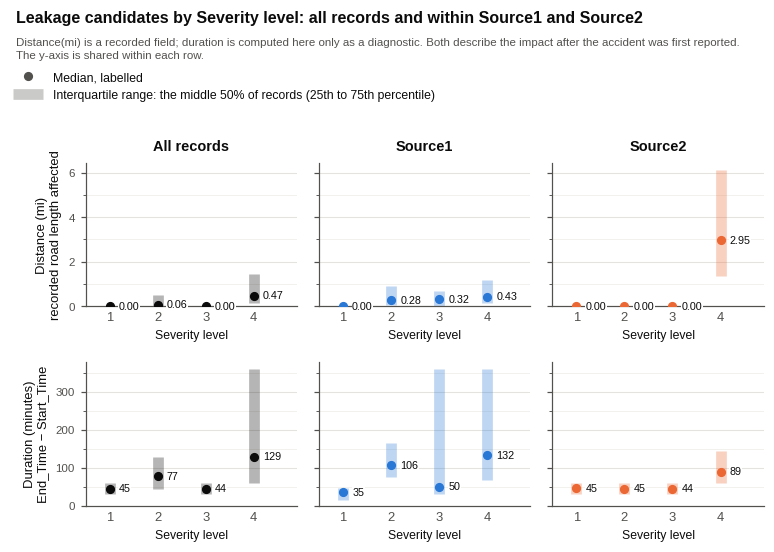

In [79]:
duration_min = (df["End_Time"] - start_time).dt.total_seconds().to_numpy() / 60  # analysis-only leakage diagnostic
LEAKAGE_MEASURES = {"Distance(mi)": df["Distance(mi)"].to_numpy(dtype="float64"), "Duration (minutes)": duration_min}
leakage_rho = pd.DataFrame({name: {g: pd.Series(values[m]).corr(pd.Series(sev_values[m], dtype="float64"), method="spearman")
                                   for g, m in POPULATIONS.items()} for name, values in LEAKAGE_MEASURES.items()}).T
print("Spearman correlation with Severity (all records / Source1 / Source2): " + "; ".join(
    f"{name} {r['All records']:.3f} / {r['Source1']:.3f} / {r['Source2']:.3f}" for name, r in leakage_rho.iterrows()))


LEAKAGE_AXES = {"Distance(mi)": ("Distance (mi)\nrecorded road length affected", "{:.2f}"),
                "Duration (minutes)": ("Duration (minutes)\nEnd_Time − Start_Time", "{:.0f}")}
fig, axes = plt.subplots(2, 3, figsize=(7.0, 5.0), sharey="row")
for col, (g, m) in enumerate(POPULATIONS.items()):
    colour = COLORS["ink"] if g == "All records" else SOURCE_COLORS[g]
    for row, (name, values) in enumerate(LEAKAGE_MEASURES.items()):
        ax = axes[row, col]
        for k in SEVERITY_LEVELS:
            q1, med, q3 = np.nanquantile(values[m & (sev_values == k)], [0.25, 0.5, 0.75])
            ax.vlines(k, q1, q3, color=colour, linewidth=7, alpha=0.3, capstyle="butt", zorder=2)
            ax.plot(k, med, marker="o", markersize=5, color=colour, zorder=3)
            ax.annotate(LEAKAGE_AXES[name][1].format(med), (k, med), xytext=(6, 0), textcoords="offset points", va="center",
                        fontsize=7, bbox=dict(facecolor="white", edgecolor="none", pad=0.3), zorder=4)
        ax.set_xticks(SEVERITY_LEVELS)
        ax.set_xlim(0.5, 4.9)
        ax.yaxis.set_major_locator(mticker.MaxNLocator(5, steps=[1, 2, 2.5, 5, 10]))
        ax.yaxis.set_minor_locator(mticker.AutoMinorLocator(2))
        value_grid(ax, "y")
        ax.tick_params(axis="x", length=0)
        ax.tick_params(axis="y", labelsize=7.5)
        ax.set_xlabel("Severity level", fontsize=8)
        if row == 0:
            ax.set_title(g, fontsize=9.5, loc="center")
        if col == 0:
            ax.set_ylabel(LEAKAGE_AXES[name][0], fontsize=8.5)
for row in range(2):  # after all three populations are drawn, so the shared row scale covers every panel
    axes[row, 0].set_ylim(bottom=0)
handles = [mpl.lines.Line2D([], [], color=COLORS["muted"], marker="o", markersize=5, linestyle="none", label="Median, labelled"),
           mpl.lines.Line2D([], [], color=COLORS["muted"], linewidth=7, alpha=0.3, solid_capstyle="butt",
                            label="Interquartile range: the middle 50% of records (25th to 75th percentile)")]
top = figure_header(fig, "Leakage candidates by Severity level: all records and within Source1 and Source2",
                    "Distance(mi) is a recorded field; duration is computed here only as a diagnostic. Both describe the impact "
                    "after the accident was first reported. The y-axis is shared within each row.", handles=handles, ncol=1)
fig.tight_layout(rect=(0, 0, 1, top), h_pad=1.5, w_pad=1.2)
save_figure(fig, "leakage_candidates_by_severity")
plt.show()

**Finding.** Within Source2, distance separates Severity 4 sharply (median 2.95 mi, against 0.00 for every other level); within Source1 it rises modestly from Severity 2 to 4 (0.28 to 0.43 mi). Duration is longest for Severity 4 in both providers (medians 132 and 89 minutes), but within Source1 Severity 3 records are shorter than Severity 2 records (50 against 106 minutes). The pooled correlations are negative (ρ = −0.135 for distance and −0.176 for duration) although distance correlates positively with Severity within each provider (0.050 and 0.157): the pooled value mixes providers with different recording conventions (Section 2.2.4) and different Severity distributions.

**Decision (unchanged).** These fields describe the extent and duration of the impact that `Severity` summarizes, and they are not available at reporting time, so using them would cause prediction-time leakage. `Distance(mi)`, `End_Time` (and any duration derived from it), `End_Lat` and `End_Lng` remain excluded from the candidate predictors.

### 2.3.4 Bivariate findings and multivariate questions

**Question:** which associations are strongest, and which hold within each provider? Two measures condense a relationship into one number. They measure different things, so they are shown in separate figures:

- **Cramér's V** (categorical features) measures the strength of association in the feature × Severity table, from 0 (no association) to 1 (the feature determines the level). It has no sign and does not show which levels differ.
- **Spearman's ρ** (numeric measurements) is the rank correlation between a measurement and the Severity level, from −1 to +1. Its sign gives the direction of a monotonic trend; patterns that rise and fall are missed.

Both complement rather than replace the figures above, and neither is a model feature importance. All values are exported to `tables/severity_effect_sizes.csv`.

In [80]:
def binary_v(yes, no, mask):
    """Cramér's V between a yes/no feature and Severity, within `mask`."""
    return cramers_v(severity_counts(pd.Series(yes), mask & (yes | no)))


pop_masks = list(POPULATIONS.values())
rows = [("Source", "Source and period", "Cramér's V", V_SOURCE, np.nan, np.nan)]
rows += [(name, "Time", "Cramér's V", *time_v.loc[name]) for name in TIME_KEYS]
rows += [(name, "Weather", "Cramér's V", *[cramers_v(severity_counts(key, m)) for m in pop_masks])
         for name, key in [("Weather_Condition (raw labels)", df["Weather_Condition"].cat.codes), ("Weather group", weather_grp_series)]]
rows += [("State", "Geography", "Cramér's V", *[cramers_v(severity_counts(df["State"], m)) for m in pop_masks])]
rows += [(name, "Road", "Cramér's V", *[binary_v(yes, no, m) for m in pop_masks]) for name, (yes, no) in ROAD_ROWS.items()]
rows += [(f"Night ({c})", "Daylight", "Cramér's V", *[binary_v(yes, no, m) for m in pop_masks]) for c, (yes, no) in NIGHT_ROWS.items()]
rows += [(name, "Missingness", "Cramér's V", *[binary_v(yes, no, m) for m in pop_masks]) for name, (yes, no) in MISSING_ROWS.items()]
rows += [("End_Lat / End_Lng missing", "Missingness (fixed within each source)", "Cramér's V",
          binary_v(~end_coords, end_coords, everything), np.nan, np.nan)]
rows += [(c, "Weather measurement", "Spearman ρ", *numeric_rho.loc[c]) for c in numeric_rho.index]
rows += [(name, "Leakage candidate", "Spearman ρ", *leakage_rho.loc[name]) for name in leakage_rho.index]
effect_sizes = pd.DataFrame(rows, columns=["Feature", "Feature group", "Statistic", "All records", "Source1", "Source2"])
save_table(effect_sizes, "severity_effect_sizes")

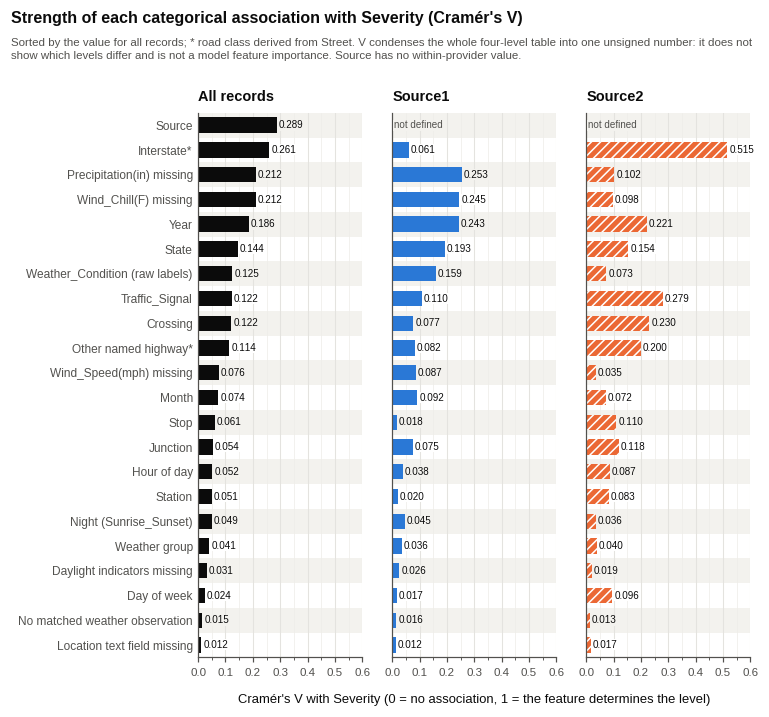

In [81]:
SUMMARY_FEATURES = ["Source", "Year", "Month", "Hour of day", "Day of week", "Weather_Condition (raw labels)", "Weather group",
                    "State", "Traffic_Signal", "Crossing", "Junction", "Stop", "Station", "Interstate (from Street)",
                    "Other named highway (from Street)", "Night (Sunrise_Sunset)"] + list(MISSING_ROWS)
POPULATION_BARS = {"All records": dict(color=COLORS["ink"]), **{s: SOURCE_BARS[s] for s in MAIN_SOURCES}}


def effect_size_figure(table, row_labels, x_limits, x_label, title, note, name, signed_values=False, separators=()):
    """One panel per population (all records, Source1, Source2) with the same rows and x-scale, one bar per feature."""
    y = np.arange(len(table))[::-1].astype(float)
    fig, axes = plt.subplots(1, 3, figsize=(7.0, 0.22 * len(table) + 1.6), sharey=True, sharex=True)
    for ax, g in zip(axes, POPULATIONS):
        shade_rows(ax, y)
        values = table[g].to_numpy(dtype=float)
        ax.barh(y, values, height=0.62, zorder=2, **POPULATION_BARS[g])
        for i, (yi, v) in enumerate(zip(y, values)):
            text = (signed(v, 3) if signed_values else f"{v:.3f}") if np.isfinite(v) else "not defined"
            ax.text(v + 0.012 * np.diff(x_limits)[0] if np.isfinite(v) and v >= 0 else (v - 0.012 * np.diff(x_limits)[0] if np.isfinite(v) else 0.005),
                    yi, text, va="center", ha="right" if np.isfinite(v) and v < 0 else "left", fontsize=6.5, zorder=4,
                    color=COLORS["ink"] if np.isfinite(v) else COLORS["muted"],
                    bbox=dict(facecolor=ZEBRA if i % 2 == 0 else "white", edgecolor="none", pad=0.3))
        if signed_values:
            ax.axvline(0, color=COLORS["ink"], linewidth=0.9, zorder=3)
        for s in separators:
            ax.axhline(s, color=COLORS["muted"], linewidth=0.8, zorder=1)
        ax.set_xlim(*x_limits)
        ax.xaxis.set_major_locator(mticker.MultipleLocator(0.1))
        ax.xaxis.set_minor_locator(mticker.MultipleLocator(0.05))
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: (signed(v, 1) if v else "0") if signed_values else f"{v:.1f}"))
        value_grid(ax, "x")
        ax.tick_params(axis="y", length=0)
        ax.tick_params(axis="x", labelsize=7.5)
        ax.set_title(g, fontsize=9.5)
    axes[0].set_yticks(y, row_labels, fontsize=7.8)
    axes[0].set_ylim(-0.5, len(y) - 0.5)
    top = figure_header(fig, title, note)
    finish_layout(fig, axes, top, x_label, w_pad=1.0)
    save_figure(fig, name)
    plt.show()


shown = effect_sizes.set_index("Feature").loc[SUMMARY_FEATURES].sort_values("All records", ascending=False)
effect_size_figure(shown, [f.replace(" (from Street)", "*") for f in shown.index], (0, 0.6),
                   "Cramér's V with Severity (0 = no association, 1 = the feature determines the level)",
                   "Strength of each categorical association with Severity (Cramér's V)",
                   "Sorted by the value for all records; * road class derived from Street. V condenses the whole four-level "
                   "table into one unsigned number: it does not show which levels differ and is not a model feature importance. "
                   "Source has no within-provider value.", "severity_effect_sizes")

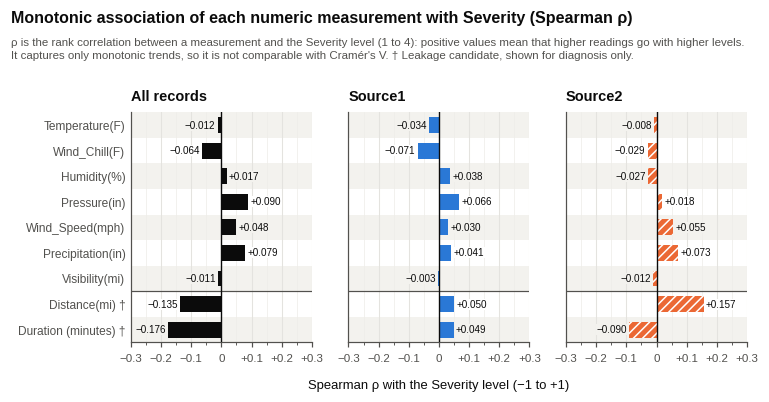

In [82]:
rho_table = effect_sizes[effect_sizes["Statistic"] == "Spearman ρ"].set_index("Feature")
effect_size_figure(rho_table, [f + (" †" if f in LEAKAGE_MEASURES else "") for f in rho_table.index], (-0.3, 0.3),
                   "Spearman ρ with the Severity level (−1 to +1)",
                   "Monotonic association of each numeric measurement with Severity (Spearman ρ)",
                   "ρ is the rank correlation between a measurement and the Severity level (1 to 4): positive values mean that "
                   "higher readings go with higher levels. It captures only monotonic trends, so it is not comparable with "
                   "Cramér's V. † Leakage candidate, shown for diagnosis only.", "severity_numeric_correlations",
                   signed_values=True, separators=[len(LEAKAGE_MEASURES) - 0.5])

**Summary.**

| Feature or group | Four-class finding | Within the two providers | Competing explanation |
|---|---|---|---|
| Source and period | Every level differs; abrupt shifts within providers | Persists within strata and after reweighting | Coverage, selection, traffic, coding or reporting (unresolved) |
| Hour of day | Severity 4 peaks after midnight; the pooled Severity 3 dip at night reverses within Source2 | Severity 4 peak in both | Provider mix by hour; traffic volume |
| Day of week | More Severity 4 at weekends; Severity 3 jumps at weekends within Source2 | Mainly Source2 | Traffic mix; provider-specific pattern |
| Month and year | Severity 1 only in 2020 and 2022; Severity 3 falls from 2018 to 2022 | Year association persists | Source and period shifts |
| Weather | Snow or ice: less Severity 1, more Severity 4; Severity 3 wetter; weak monotonic trends | Snow or ice in both | Season, location, elevation |
| State and city | All levels vary | Rankings agree moderately for Severity 3 and 4 | Provider coverage; road mix |
| Road features and road class | Signals and crossings: more Severity 1; junctions and interstates: more Severity 3 | Direction often shared, strength differs | Provider-specific coverage of road types |
| Daylight | Night: less Severity 1, more Severity 4 | Both | Hour; traffic volume |
| Weather missingness | The pooled link to Severity 3 vanishes within periods | Small Severity 4 residual after April 2019 | Collection period; provider mix |
| Daylight and location-text missingness | More Severity 4 | Not stratified | Unknown common cause |
| Leakage candidates | Strong within Source2, weak within Source1; the pooled sign misleads | Differ | Recording conventions; post-accident information |

**Relationships to carry forward.** Night and hour of day, snow or ice, junctions, interstates and state move with `Severity` in the pooled data and within both providers, although with different strength. Traffic signals, crossings, weekday and precipitation relate strongly to Severity 3 within Source2 only. Section 2.4 re-examines the strongest of these within comparable strata.

**Relationships explained mostly by collection or provider mix.** Year and month, the raw weather labels, the pooled weather-missingness association, end-coordinate missingness and the pooled Severity 3 pattern by hour largely follow the source and period shifts. The warmer temperatures of Severity 1 records follow season and period.

**Unresolved.** Why the Severity distribution shifts at the September 2020 and April 2022 boundaries and differs between providers within comparable groups; whether some accidents appear twice across providers; what the records with missing daylight or location fields have in common.

**Questions for the multivariate analysis:**

1. Are the Source-related Severity differences partly explained by geographic and road coverage (State × road class × Source)?
2. How stable is each relationship across collection periods, in particular before and after September 2020 and April 2022?
3. Does road context (interstates, signals, crossings, junctions) explain the apparent state differences?
4. Do hour, weekday and the daylight indicators carry distinct information once provider and road class are held constant?
5. Does weather remain associated with `Severity` within comparable locations and seasons?
6. Do the missing-value indicators carry information beyond provider, period and location?

Section 2.4 takes up questions 4 and 5, and the road relationships behind question 3, within comparable strata; question 1 is answered in Section 2.3.2. Question 2 is built into the calendar-quarter strata of Section 2.4 and into the time-aware validation of Section 2.6, and question 6 into the missing-value policy of Section 2.6.

## 2.4 Focused Multivariate EDA

**Question:** do the strongest feature–Severity relationships of Section 2.3 remain when the main confounders found there (provider, collection period, state and road context) are held comparable?

**What is already multivariate.** Section 2.3.2 standardized the Source/period Severity differences over combinations of state, road class, daylight and quarter, with weather group and weekend as a sensitivity check. That question is not repeated: here Source and period only define strata. Three questions follow, one per feature group (Sections 2.4.1–2.4.3), and Section 2.4.4 summarizes them.

**Method: stratified direct standardization.** For a yes/no feature F, the records are divided into strata s, for example Source × State × calendar quarter (Source1, California, 2021Q3).

1. **Within each stratum:** the Severity distribution with the feature, P(k | F = 1, s), and without it, P(k | F = 0, s), for k = 1, 2, 3, 4.
2. **Common support:** a stratum is used only if it holds at least 100 records with and 100 without the feature, so that one record moves a within-stratum share by at most 1 percentage point. Records in other strata are left out, not extrapolated, and the share kept is reported.
3. **Common weights:** both groups use the same stratum weights w_s, the distribution of the with-feature records over the usable strata. As in Section 2.3.2.3, one group is standardized to the other's mix: the records without the feature are reweighted to the strata mix of the records with it.
4. **Adjusted difference:** Σ_s w_s P(k | F = 1, s) − Σ_s w_s P(k | F = 0, s) for each level, in percentage points. The four differences sum to zero.
5. **For reference:** the pooled difference over all eligible records, without strata, and the adjusted difference within Source1 strata and within Source2 strata (the same weights, restricted to one provider).

**What it can and cannot establish.** An adjusted difference is an association that remains within comparable strata, not a causal effect: characteristics outside the strata, such as traffic volume, lanes affected or the reporting channel, are not held constant. A feature is compared with its absence only where it is known, so records with a missing value enter neither group. Source3 records count where their strata have support but are too few to show separately. The analysis uses the analysis dataset; feature codes and strata are analysis-only arrays, and `df` is not modified.

In [83]:
# Analysis-only arrays for Section 2.4; df is not modified. A feature is coded 1 (with it), 0 (without it) or −1 (unknown,
# e.g. a missing reading): unknown records enter neither group
MV_MIN_ROWS = 100  # records needed with and without the feature in a stratum: one record then moves a share by at most 1 point
SOURCE_CODE = {s: i for i, s in enumerate(df["Source"].cat.categories)}
CODED["Source"] = (df["Source"].cat.codes.to_numpy(), len(SOURCE_CODE))
precipitation = df["Precipitation(in)"].to_numpy(dtype="float64")
weather_code = np.asarray(weather_grp.codes)
snow_code, missing_weather_code = WEATHER_GROUPS.index("Snow or ice"), WEATHER_GROUPS.index("Missing")


def yes_no(yes, no):
    """1 where `yes`, 0 where `no` and −1 elsewhere."""
    return np.select([yes, no], [1, 0], -1).astype(np.int8)


MV_FEATURES = {  # defined exactly as in Section 2.3
    "Interstate*": yes_no(*ROAD_ROWS["Interstate (from Street)"]),
    **{c: yes_no(*ROAD_ROWS[c]) for c in ["Junction", "Traffic_Signal", "Crossing"]},
    "Night": yes_no(*NIGHT_ROWS["Sunrise_Sunset"]),  # night against day; missing daylight enters neither group
    "Weekend": yes_no(is_weekend, ~is_weekend),
    "Snow or ice": yes_no(weather_code == snow_code, (weather_code != snow_code) & (weather_code != missing_weather_code)),
    "Precipitation > 0 in": yes_no(precipitation > 0, precipitation == 0)}  # a missing reading is not zero


def adjusted_contrast(feature, dimensions, min_rows=MV_MIN_ROWS):
    """Severity distribution with (feature = 1) and without (feature = 0) a yes/no feature, pooled over all eligible records
    and standardized within the strata built from `dimensions`. A stratum is usable if it has at least `min_rows` records in
    each group. Both groups get the same stratum weights, the with-feature records' distribution over the usable strata; the
    same weights restricted to one provider give its within-provider result. Returns the differences (with minus without,
    percentage points; rows Pooled, Adjusted, Source1, Source2) and the common-support figures."""
    eligible = feature >= 0
    strata, stratum = np.unique(stratum_key(dimensions, eligible), return_inverse=True)
    counts = np.bincount((stratum * 2 + feature[eligible]) * 4 + sev_values[eligible] - 1,
                         minlength=8 * len(strata)).reshape(-1, 2, 4)  # stratum × (without, with) × level
    rows = counts.sum(axis=2)
    usable = (rows >= min_rows).all(axis=1)
    shares = counts / np.maximum(rows, 1)[:, :, None]
    provider = np.zeros(len(strata), dtype=np.int64)
    provider[stratum] = CODED["Source"][0][eligible]

    def standardized(mask):
        weights = rows[mask, 1] / rows[mask, 1].sum()
        return 100 * (weights @ shares[mask, 1] - weights @ shares[mask, 0]), weights

    pooled = counts.sum(axis=0) / rows.sum(axis=0)[:, None]
    adjusted, weights = standardized(usable)
    variance = (weights[:, None] ** 2  # binomial sampling variance of the adjusted difference, per level
                * (shares[usable] * (1 - shares[usable]) / rows[usable][:, :, None]).sum(axis=1)).sum(axis=0)
    differences = {"Pooled": 100 * (pooled[1] - pooled[0]), "Adjusted": adjusted,
                   **{s: standardized(usable & (provider == SOURCE_CODE[s]))[0] for s in MAIN_SOURCES}}
    support = {"Usable strata": int(usable.sum()), "Eligible records": int(rows.sum()),
               "Records covered (%)": 100 * rows[usable].sum() / rows.sum(),
               "With-feature records covered (%)": 100 * rows[usable, 1].sum() / rows[:, 1].sum(),
               "Largest 95% half-width (points)": 196 * float(np.sqrt(variance.max())),
               "With the feature": int(rows[:, 1].sum()),
               **{f"With the feature, {s}": int(rows[provider == SOURCE_CODE[s], 1].sum()) for s in MAIN_SOURCES}}
    return pd.DataFrame(differences, index=SEVERITY_LEVELS).T, support


def point_label(value):
    """Signed difference in points: two decimals below 1 point, one decimal otherwise (the convention of share_label)."""
    return signed(value, 2) if abs(value) < 1 else signed(value, 1)


def describe_contrasts(results, sensitivity, extra):
    """Print each feature's common support and four differences, then how far the sensitivity strata move them."""
    for name, (table, support) in results.items():
        print(f"{name}: {support['Usable strata']:,} usable strata hold {support['Records covered (%)']:.1f}% of the "
              f"{support['Eligible records']:,} eligible records and {support['With-feature records covered (%)']:.1f}% of the "
              f"{support['With the feature']:,} with the feature.")
        print("    Severity 1 / 2 / 3 / 4, points: " + "; ".join(
            f"{kind.lower() if kind in ('Pooled', 'Adjusted') else 'within ' + kind} "
            + " / ".join(point_label(v) for v in table.loc[kind]) for kind in table.index))
    print(f"Sensitivity, strata + {extra}: " + "; ".join(
        f"{name} {sensitivity[name][1]['With-feature records covered (%)']:.1f}% of the records with the feature covered, "
        f"adjusted differences move by at most "
        f"{(sensitivity[name][0].loc['Adjusted'] - table.loc['Adjusted']).abs().max():.2f} points"
        for name, (table, _) in results.items()))


MV_BARS = {"Pooled": COMPARISON_BAR, "Adjusted": dict(color=COLORS["ink"])}
BLOCK_BAND = 0.12  # inches reserved above each row of panels for the row's heading


def adjusted_figure(results, strata_label, title, x_label, name, row_height=0.3):
    """Top row: pooled and adjusted differences. Bottom row: the adjusted difference within each provider. One panel per
    Severity level; both panels of a column share its x-axis range."""
    names = list(results)
    tables = {kind: pd.DataFrame({f: results[f][0].loc[kind] for f in names}).T for kind in ["Pooled", "Adjusted", *MAIN_SOURCES]}
    height = 2 * (len(names) * row_height + 0.8) + 1.5 + 2 * BLOCK_BAND
    fig, axes = plt.subplots(2, 4, figsize=(7.0, height), sharey="row")
    draw_difference_bars(axes[0], {k: tables[k] for k in MV_BARS}, [f"{f} ({count_label(results[f][1]['With the feature'])})"
                                                                   for f in names], MV_BARS)
    draw_difference_bars(axes[1], {s: tables[s] for s in MAIN_SOURCES},
                         [f"{f} ({' / '.join(count_label(results[f][1][f'With the feature, {s}']) for s in MAIN_SOURCES)})"
                          for f in names], {s: SOURCE_BARS[s] for s in MAIN_SOURCES})
    for col, k in enumerate(SEVERITY_LEVELS):  # one x-range per column, covering both rows
        values = np.concatenate([t[k].to_numpy() for t in tables.values()])
        lo, hi = min(0.0, values.min()), max(0.0, values.max())
        for ax in axes[:, col]:
            ax.set_xlim(lo - 0.12 * (hi - lo), hi + 0.12 * (hi - lo))
            percent_axis(ax.xaxis, n_ticks=6, signed_labels=True, steps=(1, 2, 5, 10))  # three to six short tick labels
    handles = [mpl.patches.Patch(label="Pooled: all eligible records, no strata", **MV_BARS["Pooled"]),
               mpl.patches.Patch(label="Adjusted: compared within the same strata", **MV_BARS["Adjusted"]),
               *[mpl.patches.Patch(label=f"Adjusted within {s} strata only", **SOURCE_BARS[s]) for s in MAIN_SOURCES]]
    top = figure_header(fig, title, f"Strata: {strata_label}, each with at least {MV_MIN_ROWS} records with and without the "
                                    "feature. Severity 1 and 4 are rare, so their columns have smaller ranges, shared by both "
                                    "rows. Row labels: records with the feature (bottom row: Source1 / Source2).",
                        handles=handles, ncol=2)
    finish_layout(fig, axes, top - BLOCK_BAND / height, x_label, h_pad=2.6 + BLOCK_BAND * 72 / 9)  # h_pad in font sizes
    for row, block in enumerate(["All providers", "Within each provider"]):  # above the panel titles of its row
        fig.text(0.01, axes[row, 0].get_position().y1 + 0.3 / height, block, ha="left", va="bottom", fontsize=9.5,
                 fontweight="semibold")
    save_figure(fig, name)
    plt.show()

### 2.4.1 Road context after Source, period, and geography

**Question:** do the strongest road-context relationships with Severity remain after accounting for Source, time period and State? **Features:** the road variables with the clearest bivariate patterns (Section 2.3.3.4): interstate (road class read from `Street`, marked *), `Junction`, `Traffic_Signal` and `Crossing`. **Strata:** Source × State × calendar quarter. **Sensitivity:** daylight (`Sunrise_Sunset`) added to the strata; hour of day was not used, because its 24 values would split the strata too finely.

Interstate*: 1,635 usable strata hold 96.8% of the 7,610,699 eligible records and 97.6% of the 1,894,770 with the feature.
    Severity 1 / 2 / 3 / 4, points: pooled −0.69 / −21.7 / +22.5 / −0.14; adjusted −0.64 / −20.0 / +22.5 / −1.8; within Source1 −0.10 / +2.3 / +1.2 / −3.5; within Source2 −1.5 / −55.6 / +56.3 / +0.84
Junction: 993 usable strata hold 86.0% of the 7,610,699 eligible records and 91.8% of the 560,498 with the feature.
    Severity 1 / 2 / 3 / 4, points: pooled −0.36 / −7.7 / +7.0 / +1.0; adjusted −0.13 / −5.2 / +6.4 / −1.0; within Source1 +0.01 / +0.36 / +1.2 / −1.5; within Source2 −0.48 / −19.0 / +19.3 / +0.19
Traffic_Signal: 1,170 usable strata hold 92.0% of the 7,610,699 eligible records and 96.3% of the 1,127,663 with the feature.
    Severity 1 / 2 / 3 / 4, points: pooled +1.6 / +10.3 / −10.9 / −1.1; adjusted +0.97 / +18.5 / −19.0 / −0.41; within Source1 +1.4 / +1.2 / −2.2 / −0.40; within Source2 +0.78 / +26.9 / −27.3 / −0.42
Crossing: 996 usable strata hold 88.8%

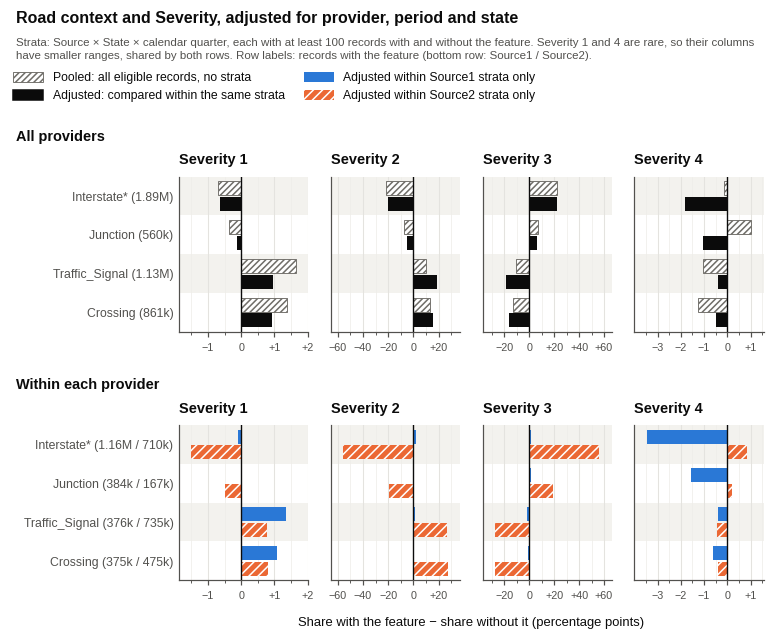

In [84]:
ROAD_STRATA = ["Source", "State", "Quarter"]  # Quarter: the calendar quarter, e.g. 2021Q3
road_adjusted = {f: adjusted_contrast(MV_FEATURES[f], ROAD_STRATA) for f in ["Interstate*", "Junction", "Traffic_Signal", "Crossing"]}
road_sensitivity = {f: adjusted_contrast(MV_FEATURES[f], ROAD_STRATA + ["Daylight"]) for f in road_adjusted}
describe_contrasts(road_adjusted, road_sensitivity, "daylight")
print("Share of records on interstates*, with vs without the feature: " + "; ".join(
    f"{c} {100 * is_interstate[MV_FEATURES[c] == 1].mean():.1f}% vs {100 * is_interstate[MV_FEATURES[c] == 0].mean():.1f}%"
    for c in ["Junction", "Traffic_Signal", "Crossing"]))
adjusted_figure(road_adjusted, "Source × State × calendar quarter",
                "Road context and Severity, adjusted for provider, period and state",
                "Share with the feature − share without it (percentage points)", "adjusted_road_context")

**Finding.**

- **Bivariate (Section 2.3.3.4):** interstates and junctions went with more Severity 3; traffic signals and crossings with more Severity 1 and less Severity 3 and 4.
- **Adjusted:** the usable strata hold 86.0% to 96.8% of the records and 91.8% to 97.6% of the records with each feature. Most differences remain. Traffic signals: Severity 1 +0.97 points (pooled +1.6) and Severity 3 −19.0 (pooled −10.9); crossings: +0.92 (+1.4) and −15.9 (−13.0), in the same direction within both providers. Interstates: Severity 3 +22.5 (pooled +22.5); junctions: +6.4 (+7.0).
- **What changed:** mainly Severity 4. On interstates its difference grows from −0.14 to −1.8 points, with opposite directions in the two providers (−3.5 within Source1, +0.84 within Source2). At junctions the pooled Severity 4 excess reverses (+1.0 to −1.0; Source1 −1.5, Source2 +0.19). At signals and crossings the Severity 4 deficit shrinks to −0.41 and −0.49 points.
- **Provider dependence:** the Severity 2 and 3 differences come almost entirely from Source2 (on interstates, Severity 3 +56.3 points within Source2 against +1.2 within Source1). Source1 records no Severity 3 from September 2020 (0.0% in every month, Section 2.3.1), so its Severity 3 differences are necessarily small.
- **Sensitivity:** adding daylight moves every adjusted difference by at most 0.59 points, with 83.4% to 94.5% of the records with each feature still covered.
- **Uncertain:** the four variables were adjusted one at a time, and they overlap: 45.6% of junction records are on interstates, against 23.3% of other records, but only 2.9% of traffic-signal and 2.0% of crossing records. Their adjusted differences are therefore not separate contributions; separating them requires a joint model.
- **Modeling implication:** traffic signals and crossings, retain as candidate predictors. Interstate and junction, retain as candidates, but their Severity 4 relationship depends on the provider, so their contribution must be evaluated across Source and period.

### 2.4.2 Temporal context after road and geographic adjustment

**Question:** do night and weekend remain associated with Severity after accounting for Source, geography, period and road context? **Features:** night against day (`Sunrise_Sunset`; the twilight indicators overlap with it, Section 2.3.3.4) and weekend against weekdays. **Strata:** Source × State × calendar quarter × road class. **Sensitivity:** each feature is also held constant for the other (weekend added for night, daylight for weekend). Whether hour or night is the better predictor is a modeling decision and is not examined here.

Night: 2,957 usable strata hold 91.4% of the 7,587,974 eligible records and 94.4% of the 2,310,684 with the feature.
    Severity 1 / 2 / 3 / 4, points: pooled −0.50 / +1.0 / −1.8 / +1.3; adjusted +0.02 / −1.7 / +0.70 / +0.94; within Source1 −0.02 / −2.1 / +0.73 / +1.4; within Source2 +0.07 / −0.99 / +0.70 / +0.22
Weekend: 1,845 usable strata hold 80.0% of the 7,610,699 eligible records and 89.5% of the 1,204,712 with the feature.
    Severity 1 / 2 / 3 / 4, points: pooled −0.60 / −2.1 / +1.5 / +1.3; adjusted −0.12 / −4.1 / +3.8 / +0.37; within Source1 −0.01 / −0.85 / +0.41 / +0.45; within Source2 −0.46 / −13.0 / +13.3 / +0.17
Sensitivity, strata + the other feature (weekend for night, daylight for weekend): Night 89.9% of the records with the feature covered, adjusted differences move by at most 0.23 points; Weekend 82.3% of the records with the feature covered, adjusted differences move by at most 0.85 points


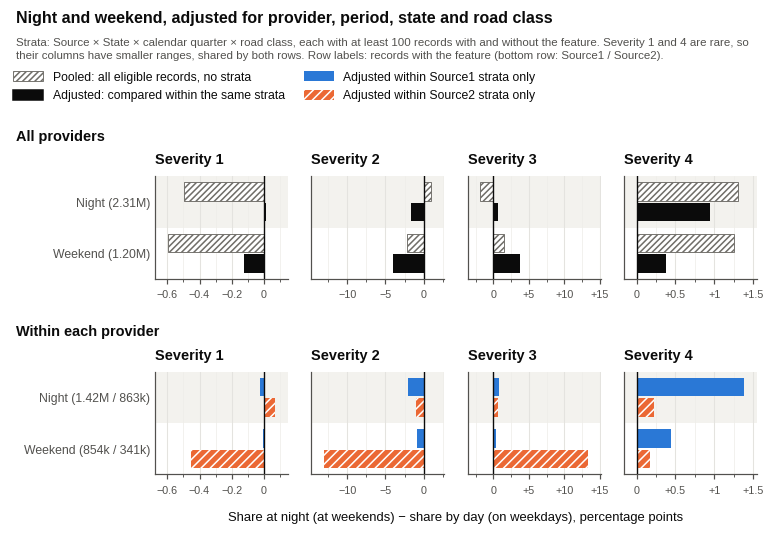

In [85]:
TIME_STRATA = ["Source", "State", "Quarter", "Road class"]
time_adjusted = {f: adjusted_contrast(MV_FEATURES[f], TIME_STRATA) for f in ["Night", "Weekend"]}
time_sensitivity = {"Night": adjusted_contrast(MV_FEATURES["Night"], TIME_STRATA + ["Weekend"]),  # each also held by the other
                    "Weekend": adjusted_contrast(MV_FEATURES["Weekend"], TIME_STRATA + ["Daylight"])}
describe_contrasts(time_adjusted, time_sensitivity, "the other feature (weekend for night, daylight for weekend)")
adjusted_figure(time_adjusted, "Source × State × calendar quarter × road class",
                "Night and weekend, adjusted for provider, period, state and road class",
                "Share at night (at weekends) − share by day (on weekdays), percentage points", "adjusted_temporal_context",
                row_height=0.36)

**Finding.**

- **Bivariate (Sections 2.3.3.1 and 2.3.3.4):** night went with less Severity 1 and more Severity 4, and weekends with more Severity 4 and less Severity 1.
- **Night, adjusted** (91.4% of the eligible records and 94.4% of the night records covered): Severity 4 remains higher, +0.94 points against +1.3 pooled, within both providers (Source1 +1.4, Source2 +0.22). The Severity 1 difference disappears (−0.50 pooled, +0.02 adjusted), and Severity 3 turns positive (+0.70 against −1.8 pooled), which confirms that the pooled night dip in Severity 3 reflects the provider mix (Section 2.3.3.1).
- **Weekend, adjusted** (80.0% and 89.5% covered): the Severity 4 excess shrinks from +1.3 to +0.37 points (Source1 +0.45, Source2 +0.17), and the Severity 1 difference from −0.60 to −0.12. What remains is a shift from Severity 2 to Severity 3 (−4.1 and +3.8 points), almost entirely within Source2 (+13.3 points of Severity 3, against +0.41 within Source1).
- **Sensitivity:** holding the other feature constant moves the adjusted differences by at most 0.23 points for night and 0.85 for weekend (89.9% and 82.3% of the records with each feature covered).
- **Uncertain:** traffic volume differs between night and day and between weekends and weekdays, but it is not in the data. Source2's Severity 4 differences look small in percentage points because Source2 records little Severity 4 (0.43% of its records, Section 2.3.1).
- **Modeling implication:** night, retain as a candidate predictor; Part 3 keeps `Sunrise_Sunset` together with hour of day and drops the overlapping twilight indicators. Weekend (day of week), retain as a candidate, noting that most of its pooled Severity 4 association was compositional and that the remaining Severity 3 pattern is mainly within Source2.

### 2.4.3 Weather after Source, location, and season

**Question:** do the clearest weather relationships remain when Source, geography and season are held approximately comparable? **Features:** the snow-or-ice weather group (the grouping of Section 2.3.2; `Weather_Condition` itself is unchanged) against other observed weather, and positive against zero `Precipitation(in)`. Records without a weather label or a precipitation reading enter neither group, so a missing reading is not treated as zero. **Strata:** Source × State × calendar quarter. The calendar quarter holds season and collection period together; pooling quarters across years into seasons would mix periods whose Severity distributions differ (Section 2.3.1). **Sensitivity:** daylight added to the strata.

Snow or ice: 329 usable strata hold 27.9% of the 7,441,043 eligible records and 86.9% of the 176,494 with the feature.
    Severity 1 / 2 / 3 / 4, points: pooled −0.82 / +0.17 / −0.67 / +1.3; adjusted −0.02 / −1.3 / +1.2 / +0.08; within Source1 −0.03 / +0.19 / −0.21 / +0.06; within Source2 +0.01 / −4.6 / +4.4 / +0.14
Precipitation > 0 in: 933 usable strata hold 89.6% of the 5,417,876 eligible records and 90.5% of the 525,318 with the feature.
    Severity 1 / 2 / 3 / 4, points: pooled −0.59 / −8.9 / +9.3 / +0.18; adjusted −0.17 / −2.3 / +2.8 / −0.32; within Source1 −0.08 / +0.34 / +0.37 / −0.63; within Source2 −0.27 / −5.6 / +5.8 / +0.06
Sensitivity, strata + daylight: Snow or ice 76.6% of the records with the feature covered, adjusted differences move by at most 0.44 points; Precipitation > 0 in 81.3% of the records with the feature covered, adjusted differences move by at most 0.14 points


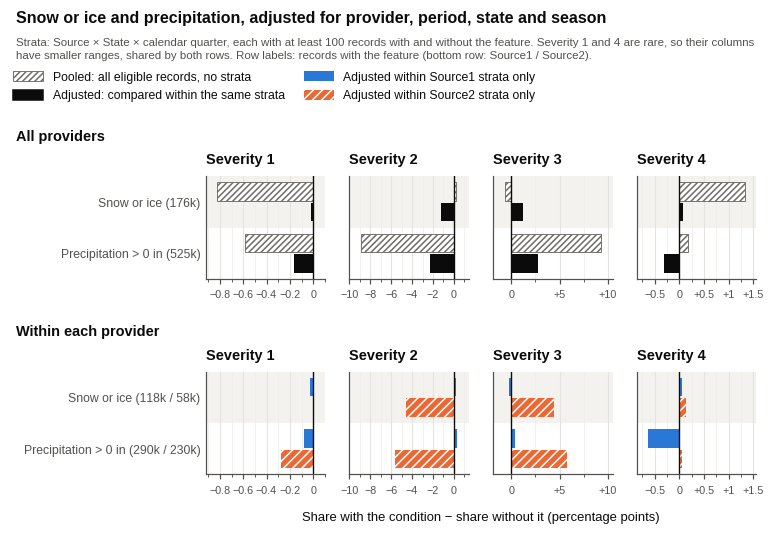

In [86]:
WEATHER_STRATA = ["Source", "State", "Quarter"]
weather_adjusted = {f: adjusted_contrast(MV_FEATURES[f], WEATHER_STRATA) for f in ["Snow or ice", "Precipitation > 0 in"]}
weather_sensitivity = {f: adjusted_contrast(MV_FEATURES[f], WEATHER_STRATA + ["Daylight"]) for f in weather_adjusted}
describe_contrasts(weather_adjusted, weather_sensitivity, "daylight")
adjusted_figure(weather_adjusted, "Source × State × calendar quarter",
                "Snow or ice and precipitation, adjusted for provider, period, state and season",
                "Share with the condition − share without it (percentage points)", "adjusted_weather", row_height=0.36)

**Finding.**

- **Bivariate (Section 2.3.3.2):** snow or ice went with almost no Severity 1 and more Severity 4, and positive precipitation with more Severity 3.
- **Snow or ice, adjusted:** the usable strata hold 86.9% of the snow-or-ice records but only 27.9% of the 7,441,043 eligible records, because most state-quarter strata have too little snow or ice; the comparison is therefore with other weather in the same wintry strata. Within them, both bivariate differences disappear: Severity 1 −0.02 points (pooled −0.82) and Severity 4 +0.08 (pooled +1.3). A small Severity 3 excess appears (+1.2), within Source2 only (+4.4; Source1 −0.21).
- **Positive precipitation, adjusted** (89.6% of the 5,417,876 eligible records and 90.5% of those with precipitation covered): the Severity 3 excess falls from +9.3 to +2.8 points, and what remains is mostly within Source2 (+5.8, against +0.37 within Source1).
- **What changed:** the pooled weather differences mostly followed where and when the conditions were recorded. For example, 97.4% of Severity 1 records fall in March–June 2020 or April–September 2022 (Section 2.3.3.1), months with little snow.
- **Sensitivity:** adding daylight moves the adjusted differences by at most 0.44 points for snow or ice and 0.14 for precipitation (76.6% and 81.3% of the records with each condition covered).
- **Uncertain:** weather is taken from the nearest station at the matched observation time, not from the accident site, and a quarter only approximates the season.
- **Modeling implication:** keep the harmonized weather groups rather than the raw labels (which also encode the April 2019 vocabulary change), and precipitation, as candidate predictors, but expect weak associations once provider, state and season are known. A missing precipitation reading must not be treated as an observed zero; its treatment is set out in Section 2.6.

### 2.4.4 Multivariate summary

The adjusted results of Sections 2.4.1–2.4.3 are exported to `tables/multivariate_adjusted_summary.csv`: every feature and all four Severity levels, with the pooled, adjusted and within-provider differences, the sensitivity result and the common support. The relationships are then summarized by what happens to them after adjustment. This is a summary of the evidence, not the decision table; column-by-column preparation decisions belong to Part 3.

In [87]:
MV_QUESTIONS = {"2.4.1": (ROAD_STRATA, road_adjusted, "Daylight", road_sensitivity),
                "2.4.2": (TIME_STRATA, time_adjusted, "Weekend (night) / Daylight (weekend)", time_sensitivity),
                "2.4.3": (WEATHER_STRATA, weather_adjusted, "Daylight", weather_sensitivity)}
rows = []
for question, (strata, adjusted, extra, sensitivity) in MV_QUESTIONS.items():
    for name, (table, support) in adjusted.items():
        for k in SEVERITY_LEVELS:
            rows.append({"Section": question, "Feature": name, "Strata": " × ".join(strata), "Severity": k,
                         "Pooled (pp)": table.at["Pooled", k], "Adjusted (pp)": table.at["Adjusted", k],
                         **{f"Adjusted within {s} (pp)": table.at[s, k] for s in MAIN_SOURCES},
                         "Sensitivity: added to the strata": extra, "Sensitivity adjusted (pp)": sensitivity[name][0].at["Adjusted", k],
                         **{c: support[c] for c in ["Usable strata", "Eligible records", "Records covered (%)",
                                                    "With-feature records covered (%)"]}})
mv_summary = pd.DataFrame(rows).round(2)
save_table(mv_summary, "multivariate_adjusted_summary")
half_width = max(support["Largest 95% half-width (points)"] for _, adjusted, _, _ in MV_QUESTIONS.values()
                 for _, support in adjusted.values())
print(f"Largest binomial 95% half-width of an adjusted difference ({mv_summary['Feature'].nunique()} features × 4 levels): "
      f"{half_width:.2f} points.")

Largest binomial 95% half-width of an adjusted difference (8 features × 4 levels): 0.17 points.


**Classification.** Each relationship reported in Section 2.3, and each adjusted difference of at least 1 point that appears only after adjustment, is classified by its adjusted difference in the primary strata:

- **A. Remains after adjustment:** at least half of the pooled difference remains, with the same sign within both providers.
- **B. Strongly attenuated after adjustment:** less than half remains, or the sign reverses.
- **C. Inconsistent / source-specific:** the adjusted differences within Source1 and within Source2 have opposite signs, and at least one of them is 0.5 points or more (this takes precedence over A and B).
- **D. Insufficient common support:** fewer than 75% of the feature's records lie in usable strata.

All four levels are estimated for every feature and appear in the figures above and in the exported table. The rows below name the levels that carry each relationship; Severity 2 changes are not listed separately because they mostly mirror the Severity 3 difference (or, within Source1, which records no Severity 3 from September 2020, the Severity 4 difference).

| Class | Relationship | Pooled → adjusted (points) | Adjusted within Source1 / Source2 |
|---|---|---|---|
| A | Traffic signals and crossings: more Severity 1 | +1.6 → +0.97; +1.4 → +0.92 | +1.4 / +0.78; +1.1 / +0.80 |
| A | Traffic signals and crossings: less Severity 3 | −10.9 → −19.0; −13.0 → −15.9 | −2.2 / −27.3; −1.1 / −27.4 |
| A | Interstates and junctions: more Severity 3 | +22.5 → +22.5; +7.0 → +6.4 | +1.2 / +56.3; +1.2 / +19.3 |
| A | Night: more Severity 4 | +1.3 → +0.94 | +1.4 / +0.22 |
| A | Weekend: more Severity 3 | +1.5 → +3.8 | +0.41 / +13.3 |
| B | Traffic signals and crossings: less Severity 4 | −1.1 → −0.41; −1.3 → −0.49 | −0.40 / −0.42; −0.61 / −0.39 |
| B | Night: less Severity 1; less Severity 3 | −0.50 → +0.02; −1.8 → +0.70 | −0.02 / +0.07; +0.73 / +0.70 |
| B | Weekend: more Severity 4; less Severity 1 | +1.3 → +0.37; −0.60 → −0.12 | +0.45 / +0.17; −0.01 / −0.46 |
| B | Snow or ice: less Severity 1; more Severity 4 | −0.82 → −0.02; +1.3 → +0.08 | −0.03 / +0.01; +0.06 / +0.14 |
| B | Positive precipitation: more Severity 3 | +9.3 → +2.8 | +0.37 / +5.8 |
| C | Interstates: Severity 4 (appears after adjustment) | −0.14 → −1.8 | −3.5 / +0.84 |
| C | Junctions: more Severity 4 | +1.0 → −1.0 | −1.5 / +0.19 |
| C | Snow or ice: Severity 3 (appears after adjustment) | −0.67 → +1.2 | −0.21 / +4.4 |

**D: none.** 86.9% to 97.6% of each feature's records lie in usable strata (76.6% to 94.5% with the sensitivity strata). Source3 alone cannot be assessed.

**Reading the classes.** Class A does not mean equal strength in both providers: every Severity 3 difference comes mostly from Source2, because Source1 records Severity 3 only before September 2020. Every adjusted difference has a binomial 95% half-width of at most 0.17 points, so sampling error is negligible; what limits these results is what the strata leave out.

In [88]:
# Checkpoint at the end of Part 2: the EDA did not modify the analysis dataset validated in Section 1.5
assert frame_fingerprint(df) == CLEAN_FINGERPRINT, "The analysis dataset changed during Part 2"
severity_check = df[TARGET].value_counts().sort_index().tolist()
assert df.shape == (7_610_699, 44) and severity_check == [65_570, 6_048_391, 1_295_235, 201_503]
print(f"Integrity check passed: the analysis dataset is unchanged since Section 1.5 ({df.shape[0]:,} rows x {df.shape[1]} "
      "columns; Severity 1–4: " + " / ".join(f"{n:,}" for n in severity_check) + ").")

Integrity check passed: the analysis dataset is unchanged since Section 1.5 (7,610,699 rows x 44 columns; Severity 1–4: 65,570 / 6,048,391 / 1,295,235 / 201,503).


## 2.5 Key Insights

Each insight states what the EDA showed, where the evidence is, and why it matters for predicting `Severity`.

1. **Severity is heavily imbalanced.** Severity 2 makes up 79.47% of the records and Severity 1 only 0.86% (`figures/severity_distribution.jpg`, Section 2.1.1). *For modeling:* always predicting Severity 2 already reaches 79.47% accuracy but only 25.00% balanced accuracy, so evaluation needs class-sensitive metrics.

2. **Source and collection period shape the recorded Severity.** The providers' Severity distributions differ sharply and shift abruptly over time, for example Source1 records no Severity 3 from September 2020, and the differences persist within comparable state, quarter and road strata (`figures/severity_by_source.jpg`, `figures/severity_by_month_source1.jpg`, `figures/severity_by_month_source2.jpg`, `figures/standardization_between_sources.jpg`; Sections 2.3.1 and 2.3.2). *For modeling:* this is a distribution shift whose cause (accident population, coverage, selection, traffic or coding practice) is unresolved, so validation must be source- and time-aware.

3. **Road context keeps the clearest adjusted associations, with provider-dependent strength.** Within Source × State × quarter strata, traffic signals and crossings keep less Severity 3 (−19.0 and −15.9 percentage points) and interstates more (+22.5), mostly within Source2 (`figures/adjusted_road_context.jpg`, Section 2.4.1). *For modeling:* road features are worth keeping, but their contribution must be checked across providers and periods.

4. **Night is the most stable temporal effect.** Its Severity 4 excess remains after adjustment (+0.94 percentage points) in both providers, whereas the weekend and pooled hourly patterns are largely compositional (`figures/adjusted_temporal_context.jpg`, `figures/severity_by_hour_by_source.jpg`; Section 2.4.2). *For modeling:* keep day/night context, but do not read pooled temporal patterns at face value.

5. **Weather adds little once context is held fixed, and its gaps follow the collection process.** After adjustment, the Severity 3 excess with precipitation falls from +9.3 to +2.8 percentage points and the snow-or-ice pattern disappears (`figures/adjusted_weather.jpg`, Section 2.4.3); the weather vocabulary and the weather missing rates both change in April 2019, and the pooled link between missingness and Severity vanishes within each period (`figures/weather_missingness_by_month.jpg`, `figures/severity_by_missingness.jpg`; Sections 2.2.2, 2.2.3 and 2.3.3.5). *For modeling:* use harmonized weather groups, expect weak weather effects, and treat missingness as non-random.

6. **Prediction-time availability defines the feature boundary.** Distance, duration and end coordinates move strongly with Severity, but they describe the impact after the accident is first reported (`figures/leakage_candidates_by_severity.jpg`, Section 2.3.3.6). *For modeling:* a strong association does not justify post-event information; using these fields would cause prediction-time leakage, so they stay excluded.

## 2.6 Preparation Implications from the EDA

The insights translate into seven broad preparation principles. Part 3 specifies exactly how each column is treated; nothing here is applied to the analysis dataset.

- **Exclude post-event information.** Fields that describe the extent or duration of the impact are unavailable when an accident is first reported, so they are excluded whatever their association with Severity, to avoid prediction-time leakage (Sections 1.3.8 and 2.3.3.6). Free-text `Description` also stays outside the baseline tabular model.
- **Keep records, and handle gaps and extremes inside the training pipeline.** Confirmed duplicates are removed, but unconfirmed repeats, incomplete records and extreme values that break no validity rule are kept (Sections 1.3.3 and 1.3.7). Missing predictors are imputed from the training partition and flagged where the collection process shaped the gaps, so a missing precipitation reading is never read as an observed zero (Sections 2.2.3 and 2.3.3.5).
- **Encode high-cardinality categories without leakage.** Location fields with thousands of levels are frequency-encoded on the training partition rather than one-hot or target-encoded, and raw street names give way to a text-derived road-class proxy, not an official classification (Sections 2.1.2 and 2.3.2).
- **Harmonize weather terminology.** Weather labels are mapped to groups that span the April 2019 vocabulary change (Section 2.2.2).
- **Keep `Source` for provenance and diagnostics, not as a baseline predictor.** It may encode provider-specific collection or reporting rather than accident conditions, and the cause of the source and period differences is unresolved (Sections 2.3.1 and 2.3.2).
- **Evaluate under distribution shift.** A random split alone would overstate robustness, so a chronological holdout is the primary check and results are reported by Source and collection period (Section 2.3.1).
- **Evaluate with class-sensitive metrics.** With 79.47% of the records at Severity 2, accuracy alone is misleading (Section 2.1.1).

# Part 3. Decision Table 

The table turns the evidence of Parts 1 and 2 into the final preparation policy for predicting `Severity`, in the Column / issue, Decision and Because format of Lecture 5. Every step that learns from data (imputation medians, category frequencies, one-hot vocabularies, any scaling) is fitted on the training partition only and applied unchanged to validation and test data. Read from top to bottom, the rows and the sections they cite are sufficient to rebuild the preparation workflow, from the raw file to the model-ready representation (C).

| Column / issue | Decision | Because |
|---|---|---|
| `Severity` (target) | Keep all four levels (1–4) for every record; never impute, merge or relabel them. Do not resample before splitting: apply any class weights or resampling to the training partition only, and evaluate with macro-F1, balanced accuracy and per-class recall next to accuracy. | The target is complete and valid, but Severity 2 holds 79.47% of the records and Severity 1 only 0.86%: always predicting Severity 2 reaches 79.47% accuracy but only 25.00% balanced accuracy and 0.221 macro-F1 (Sections 1.3.1 and 2.1.1). |
| `ID`, `Country`, `Turning_Loop` | Exclude from the predictors: keep `ID` only as the row key, and drop `Country` and `Turning_Loop`. | None of them describes the accident: `ID` is a serial key with 7,728,394 unique values for 7,728,394 raw rows, and `Country` (US) and `Turning_Loop` (False) each hold a single value (Section 1.3.2). |
| Duplicate and repeated records | Before splitting, remove rows identical in all 45 non-`ID` columns once timestamps are parsed, keeping the first. Keep the unconfirmed event-key overlaps and cross-source pairs; if a reliable event grouping becomes available, split by event group. | Only identical rows are proven copies (117,695 removed); the 91,976 event-key overlaps and 4,073 cross-source candidate pairs cannot be confirmed as the same accident (Sections 1.3.3 and 2.3.2.4). |
| `Start_Time` | Derive `Hour` (0–23) and `Is_weekend` (1 for Saturday or Sunday, 0 otherwise) from local time. One-hot encode `Hour` as a 24-level categorical variable with a vocabulary learned on the training partition only, and use `Is_weekend` as a binary 0/1 predictor. Use `Start_Time` itself only to define the chronological split (the chronological holdout below); do not use the raw timestamp, year or month as baseline predictors. | Hour and weekend carry useful temporal structure: Severity 4 is 6.6% of records at 00:00 against 1.7% at 07:00. Year and month are strongly entangled with the changing provider and collection regimes: 97.4% of Severity 1 records fall in March–June 2020 or April–September 2022 (Sections 2.3.3.1 and 2.4.2). |
| `End_Time`, `End_Lat`, `End_Lng`, `Distance(mi)` | Exclude from the predictors, together with any duration derived from `End_Time`; their missing values need no imputation. | They describe the extent and duration of the impact, which are unknown when an accident is first reported, so using them would cause prediction-time leakage; within Source2, for example, the median distance is 2.95 mi for Severity 4 against 0.00 for every other level (Sections 1.3.8 and 2.3.3.6). |
| `Source` | Keep for provenance and for reporting metrics by provider; exclude from the baseline predictors. | Severity differs sharply by provider (Cramér's V = 0.29 for all records, 0.20 to 0.48 within single years), the differences persist within comparable strata, and their cause is unresolved (Sections 2.3.1 and 2.3.2). |
| `Description` | Exclude from the baseline tabular model; a text model with its own leakage review is outside the scope of this assignment. | It is unstructured, provider-written text that may contain post-event wording (Sections 1.3.8 and 2.1.2). |
| `Start_Lat`, `Start_Lng`, `State`, `Timezone` | Keep the coordinates as numeric predictors, without binning or target encoding. One-hot encode `State` and `Timezone` (with a Missing level for `Timezone`) using training-partition vocabularies, so unseen levels get all zeros. | The coordinates are numeric location features, while State and Timezone are low-cardinality categorical variables suitable for one-hot encoding. Geographic location carries information: Severity 3 ranges from 5.5% in Oregon to 36.8% in Georgia among the states shown (Sections 1.3.7, 2.1.2 and 2.3.3.3). |
| `City`, `County`, `Zipcode`, `Airport_Code` | Merge letter-case variants and keep the first five digits of `Zipcode`, then replace each level by its share of training records; unseen levels and missing values map to 0. No one-hot or target encoding. | They have 1,871 (`County`) to 825,094 (`Zipcode`) distinct raw values, too many to one-hot encode, and target encoding would leak Severity into the features (Sections 1.3.6 and 2.1.2). |
| `Street` | Exclude the raw name; derive `Road_class` (Interstate, Other named highway, Other or unnamed street) with the rule of Section 2.3.2 and one-hot encode it. | Raw names are too many to encode (336,306 distinct raw values), while the road-class proxy keeps a strong adjusted association (interstates: Severity 3 +22.5 percentage points); it is text-derived, not an official classification (Sections 2.1.2 and 2.4.1). |
| `Temperature(F)`, `Wind_Chill(F)`, `Humidity(%)`, `Pressure(in)`, `Visibility(mi)`, `Wind_Speed(mph)`, `Precipitation(in)`, `Weather_Timestamp` | Keep the seven measurements (a zero `Pressure(in)` stays missing) and impute their gaps with training-partition medians. Add missing indicators for `Wind_Chill(F)`, `Wind_Speed(mph)` and `Precipitation(in)`, plus `No_weather_observation` where `Weather_Timestamp` is missing; drop the raw timestamp but keep rows observed more than 1 h from `Start_Time`. A missing precipitation reading is never an observed zero. | Weather gaps follow the collection period and provider rather than chance (`Precipitation(in)` is missing for 87.1% of records in March 2019 but 3.7% in April 2019), and most recorded precipitation readings are zero. The measurements stay as candidates even though their associations attenuate after adjustment: the Severity 3 excess with precipitation falls from +9.3 to +2.8 points (Sections 2.1.3, 2.2.3 and 2.4.3). |
| `Weather_Condition`, `Wind_Direction` | Map `Weather_Condition` to the seven weather groups of Section 2.3.2 and `Wind_Direction` to its 18 canonical levels (Section 1.4); one-hot encode both with a Missing level. | The raw labels mix coding schemes (24 `Wind_Direction` labels for 16 compass points plus calm and variable wind) and change vocabulary in April 2019, so they partly encode the collection period (Sections 1.3.6 and 2.2.2). |
| `Amenity`, `Bump`, `Crossing`, `Give_Way`, `Junction`, `No_Exit`, `Railway`, `Roundabout`, `Station`, `Stop`, `Traffic_Calming`, `Traffic_Signal` | Keep all twelve road-feature flags as 0/1 predictors, including the rare ones. | They are complete, several keep adjusted associations with Severity (Severity 3: traffic signals −19.0, crossings −15.9 and junctions +6.4 percentage points), and rarity alone is not evidence of irrelevance (Sections 2.1.2.4 and 2.4.1). |
| `Sunrise_Sunset`, `Civil_Twilight`, `Nautical_Twilight`, `Astronomical_Twilight` | Keep `Sunrise_Sunset` as a one-hot day/night predictor (Day, Night, Missing); exclude the three twilight indicators. | The four indicators overlap, and the night association was confirmed after adjustment with `Sunrise_Sunset`: Severity 4 stays +0.94 percentage points higher at night, in both providers (Sections 2.3.3.4 and 2.4.2). |
| Missing values, extremes and learned preprocessing | Delete no record for a missing predictor. Retain extreme values unless they violate a documented or definitionally necessary validity rule (only the three zero `Pressure(in)` values do, and they stay missing); use the 1.5 × IQR rule only to inspect distributions, with no IQR-based deletion, clipping or winsorizing. Fit every data-derived step (medians, frequencies, vocabularies, any scaling) on the training partition only and apply it unchanged to validation and test data. | A statistically unusual value is not proven invalid: the 1.5 × IQR rule would flag 9.65% of precipitation readings (every non-zero amount) and 19.61% of visibility readings. Missingness and distributions shift with provider and period, so deleting rows or learning statistics from all records would bias the data or leak test information (Sections 1.3.7 and 2.2.3). |
| Evaluation design | Primary robustness check, a chronological holdout: train on records before 1 April 2022 (the training partition) and test on 1 April 2022 to 31 March 2023. Tune on a Severity-stratified random validation split of the training partition, and report metrics overall, by Source and by period (before September 2020, September 2020 to March 2022, from April 2022). | Severity shifts abruptly within providers across collection periods (Source2's Severity 1 share rises from 5.2% in April 2022 to 31.1% in May 2022), so a random split alone would overstate robustness (Sections 2.2.1 and 2.3.1). |

# Part 4. RAPIDS Experiment 

Part 4 reproduces six core EDA task families from Part 2 using NVIDIA RAPIDS on the full 7,610,699 × 44 analysis dataset derived from the full 7,728,394-row source file: cuDF replaces pandas and CuPy replaces NumPy. The six families cover univariate profiling; collection (source) and temporal effects; Severity by source and time; weather grouping and correlations; road class and road features; and direct standardization, the method of the focused multivariate EDA. Section 4.2 maps each family to its Part 2 sections. The computations behind these analyses are repeated, not every individual Part 2 figure. Each task is one function that runs on the pandas data frame `df` and, unchanged, on its GPU copy `gdf`. Section 4.4 checks that both sides give the same results, and Section 4.5 compares their runtimes. Part 4 needs an NVIDIA GPU with RAPIDS installed: without them, the first cell stops with an error instead of falling back to pandas.

## 4.1 Setup and RAPIDS availability

In [89]:
# Part 4 stops here, instead of falling back to pandas, unless cuDF, CuPy and a CUDA GPU are available
try:
    import cudf
    import cupy
    gpu = cupy.cuda.runtime.getDeviceProperties(0)
except Exception as error:  # a missing package, or no usable GPU or driver
    raise RuntimeError(f"Part 4 needs NVIDIA RAPIDS (cuDF and CuPy) and a CUDA GPU, which this environment does not provide "
                       f"({type(error).__name__}: {error}).") from None
gpu_name = gpu["name"].decode() if isinstance(gpu["name"], bytes) else gpu["name"]
print(f"GPU: {gpu_name} ({gpu['totalGlobalMem'] / 1e9:.1f} GB); cuDF {cudf.__version__}; CuPy {cupy.__version__}")

GPU: Tesla T4 (15.6 GB); cuDF 26.02.01; CuPy 14.0.1


## 4.2 Operations replicated from Part 2

| Task (Part 2 sections) | pandas / NumPy (CPU) | cuDF / CuPy (GPU) |
|---|---|---|
| Copy of the analysis dataset to the GPU | – | `pyarrow.Table.from_pandas`, `cudf.DataFrame.from_arrow` |
| Univariate profile: records per level, missing values, distinct values, numeric summary (2.1.1–2.1.3) | `Series.value_counts`, `DataFrame.isna().sum()`, `DataFrame.nunique`, `DataFrame.describe` | the same methods of `cudf.Series` and `cudf.DataFrame` |
| Collection effects: records per month and source, missing weather values by period and source (2.2.1, 2.2.3) | `.dt` accessor, `DataFrame.groupby(...).size()` and `.mean()` | cuDF `.dt` accessor, `cudf.DataFrame.groupby` |
| Severity by source, year, hour and weekday (2.3.1, 2.3.3.1) | `.dt` accessor, `DataFrame.groupby(...).size()` | cuDF `.dt` accessor, `cudf.DataFrame.groupby` |
| Weather groups and Spearman correlations (2.3.3.2) | `numpy.bincount`, `Series.rank`, NumPy dot products | `cupy.bincount`, `cudf.Series.rank`, CuPy dot products |
| Road class from `Street` and road-feature contrasts (2.3.2, 2.3.3.4) | `.str.strip`, `.str.lower`, `.str.contains` with regular expressions, `numpy.bincount` | cuDF `.str` methods, with the regular expressions evaluated on the GPU; `cupy.bincount` |
| Direct standardization for traffic signals (2.4.1) | `numpy.unique`, `numpy.bincount`, matrix products | `cupy.unique`, `cupy.bincount`, CuPy matrix products |

Each task receives the data frame (`df` or `gdf`) and the matching array module (`numpy` or `cupy`), so the same line of code calls pandas on the CPU and cuDF on the GPU. `.values` returns a NumPy array for a pandas column and a CuPy array for a cuDF column, and `to_host` copies each small result back to the CPU.

In [90]:
CARDINALITY_COLS = CATEGORY_FEATURES + ["Description"]  # categorical and text columns (Section 2.1.2)
SPEARMAN_COLS = list(numeric_rho.index)  # the seven weather measurements (Section 2.3.3.2)
MONTH_KEYS = [m.year * 100 + m.month for m in all_months]
YEARS = sorted(int(y) for y in start_year.unique())
INTERSTATE_PATTERN = r"^(?:i-\s?\d|interstate\b)"  # the road-class rules of Section 2.3.2, for lower-case street names
HIGHWAY_PATTERN = (r"(?:\b(?:us|sr|state route|route|rte|hwy|highway|fwy|freeway|expy|expressway|pkwy|parkway|tpke|turnpike"
                   r"|beltway)\b|^[a-z]{2}-\d)")
ROAD_FLAGS = ["Traffic_Signal", "Crossing", "Junction"]


def to_host(result):
    """A small result as a pandas or NumPy object: cuDF results are copied with .to_pandas(), CuPy arrays with
    cupy.asnumpy(); pandas and NumPy results are returned unchanged."""
    if hasattr(result, "to_pandas"):
        return result.to_pandas()
    return cupy.asnumpy(result) if isinstance(result, cupy.ndarray) else result


def category_codes(series):
    """Category codes with −1 for a missing value (pandas already uses −1; cuDF marks the value as null)."""
    return series.cat.codes.astype("int32").fillna(-1)


def crosstab(rows, columns, row_values, column_values):
    """Records for each pair of integer keys, counted with groupby(...).size(), as a small pandas table."""
    counts = to_host(rows.to_frame("row").assign(column=columns).groupby(["row", "column"]).size())
    return counts.unstack(fill_value=0).reindex(index=row_values, columns=column_values, fill_value=0)


def univariate_profile(frame, xp):  # Sections 2.1.1–2.1.3
    return {"Records per Severity level": to_host(frame[TARGET].value_counts()).reindex(SEVERITY_LEVELS),
            "Missing values per column": to_host(frame.isna().sum()),
            "Distinct values per categorical or text column": to_host(frame[CARDINALITY_COLS].nunique()),
            "Numeric summary": to_host(frame[NUMERIC_FEATURES].describe())}


def collection_effects(frame, xp):  # Sections 2.2.1 and 2.2.3
    start, source = frame["Start_Time"], category_codes(frame["Source"])
    month = start.dt.year.astype("int32") * 100 + start.dt.month.astype("int32")
    missing = frame[MISSING_OVER_TIME].isna().astype("float64")
    missing["period"] = (start >= MISSINGNESS_BREAK.to_datetime64()).astype("int8")  # 0 before, 1 from April 2019
    missing["source"] = source
    return {"Records per month and source": crosstab(month, source, MONTH_KEYS, range(len(SOURCES))),
            "Missing weather values by period and source (%)":
                100 * to_host(missing.groupby(["period", "source"]).mean()).sort_index()}


def severity_profiles(frame, xp):  # Sections 2.3.1 and 2.3.3.1
    start, severity = frame["Start_Time"], frame[TARGET].astype("int8")
    keys = {"source": (category_codes(frame["Source"]), range(len(SOURCES))), "year": (start.dt.year.astype("int32"), YEARS),
            "hour": (start.dt.hour.astype("int32"), range(24)), "weekday": (start.dt.dayofweek.astype("int32"), range(7))}
    return {f"Severity by {name}": crosstab(key, severity, values, SEVERITY_LEVELS) for name, (key, values) in keys.items()}


def weather_analysis(frame, xp):  # Section 2.3.3.2
    labels = pd.Index(to_host(frame["Weather_Condition"].cat.categories)).astype(str)  # 144 labels, grouped as in 2.3.2
    group_of_label = np.select([labels.str.lower().str.contains(p) for _, p in WEATHER_PATTERNS],
                               [WEATHER_GROUPS.index(g) for g, _ in WEATHER_PATTERNS], WEATHER_GROUPS.index("Other"))
    lookup = xp.asarray(np.append(group_of_label, WEATHER_GROUPS.index("Missing")))  # code −1 (missing) takes the last entry
    group = lookup[category_codes(frame["Weather_Condition"]).values]
    severity = frame[TARGET].astype("int64").values
    counts = xp.bincount(group * 4 + severity - 1, minlength=4 * len(WEATHER_GROUPS)).reshape(-1, 4)
    rho = {}
    for c in SPEARMAN_COLS:  # Spearman's rho: Pearson correlation of the average ranks, over the records with a reading
        valid = frame[c].notna()
        x = frame[c][valid].rank(method="average").values
        y = frame[TARGET][valid].astype("float64").rank(method="average").values
        x, y = x - x.mean(), y - y.mean()
        rho[c] = float(x @ y / xp.sqrt((x @ x) * (y @ y)))
    return {"Severity by weather group": pd.DataFrame(to_host(counts), index=WEATHER_GROUPS, columns=SEVERITY_LEVELS),
            "Spearman correlation with Severity": pd.Series(rho)}


def road_context(frame, xp):  # Sections 2.3.2 and 2.3.3.4
    street = frame["Street"].fillna("").str.strip().str.lower()
    interstate = street.str.contains(INTERSTATE_PATTERN, regex=True).astype("bool").values
    highway = ~interstate & street.str.contains(HIGHWAY_PATTERN, regex=True).astype("bool").values
    severity = frame[TARGET].astype("int64").values
    flags = {**{c: frame[c].astype("int64").values for c in ROAD_FLAGS}, "Interstate (from Street)": interstate.astype("int64")}
    return {"Records per road class": to_host(xp.bincount(xp.where(interstate, 0, xp.where(highway, 1, 2)), minlength=3)),
            **{f"{name}: Severity without and with": to_host(xp.bincount(flag * 4 + severity - 1, minlength=8)).reshape(2, 4)
               for name, flag in flags.items()}}


def standardized_contrast(frame, xp, feature="Traffic_Signal"):  # Section 2.4.1: strata Source × State × calendar quarter
    start = frame["Start_Time"]
    quarter = ((start.dt.year.astype("int32") - 2016) * 4 + start.dt.quarter.astype("int32") - 1).astype("int64").values
    source = category_codes(frame["Source"]).astype("int64").values
    state = category_codes(frame["State"]).astype("int64").values + 1
    _, stratum = xp.unique((source * 64 + state) * 64 + quarter, return_inverse=True)
    with_feature, severity = frame[feature].astype("int64").values, frame[TARGET].astype("int64").values
    counts = xp.bincount((stratum * 2 + with_feature) * 4 + severity - 1,
                         minlength=8 * (int(stratum.max()) + 1)).reshape(-1, 2, 4)  # stratum × (without, with) × level
    rows = counts.sum(axis=2)
    usable = (rows >= MV_MIN_ROWS).all(axis=1)
    shares = counts / xp.maximum(rows, 1)[:, :, None]
    weights = rows[usable, 1] / rows[usable, 1].sum()  # the with-feature records' distribution over the usable strata
    adjusted = 100 * (weights @ shares[usable, 1] - weights @ shares[usable, 0])
    pooled = 100 * (counts[:, 1].sum(axis=0) / rows[:, 1].sum() - counts[:, 0].sum(axis=0) / rows[:, 0].sum())
    return {"Pooled difference (percentage points)": to_host(pooled),
            "Adjusted difference (percentage points)": to_host(adjusted), "Usable strata": int(usable.sum())}


TASKS = {  # task: (Part 2 sections, function)
    "Univariate profile": ("2.1.1–2.1.3", univariate_profile),
    "Collection effects": ("2.2.1, 2.2.3", collection_effects),
    "Severity by source and time": ("2.3.1, 2.3.3.1", severity_profiles),
    "Weather groups and correlations": ("2.3.3.2", weather_analysis),
    "Road class and road features": ("2.3.2, 2.3.3.4", road_context),
    "Direct standardization": ("2.4.1", standardized_contrast),
}

## 4.3 Copy to the GPU and timed runs

The analysis dataset is copied to GPU memory once, through Apache Arrow, and the copy is timed on its own. Each task then runs on each side once untimed, a warm-up that absorbs CUDA initialization, kernel compilation and caching, and three more times timed; Section 4.5 reports the median. The GPU is synchronized before each clock stops, every timed run includes copying its small result back to the CPU, and loading the data from disk is excluded on both sides.

In [91]:
# One copy of the analysis dataset to GPU memory, timed separately. pandas string columns reach Arrow with 64-bit offsets;
# they are cast to 32-bit offsets, which every cuDF release reads (the largest column, Description, holds about 0.5 GB of text)
start = time.perf_counter()
arrow_table = pa.Table.from_pandas(df, preserve_index=False)
arrow_table = arrow_table.cast(pa.schema([field.with_type(pa.string()) if pa.types.is_large_string(field.type) else field
                                          for field in arrow_table.schema]))
gdf = cudf.DataFrame.from_arrow(arrow_table)
cupy.cuda.runtime.deviceSynchronize()
transfer_seconds = time.perf_counter() - start
del arrow_table
assert gdf.shape == df.shape and list(gdf.columns) == list(df.columns), "The GPU copy does not match the analysis dataset"
print(f"Analysis dataset copied to the GPU in {transfer_seconds:.1f} s: {gdf.shape[0]:,} rows x {gdf.shape[1]} columns, "
      f"{gdf.memory_usage(deep=True).sum() / 1e9:.2f} GB of GPU memory.")

SIDES = {"pandas / NumPy": (df, np, lambda: None),
         "cuDF / CuPy": (gdf, cupy, cupy.cuda.runtime.deviceSynchronize)}  # GPU work is asynchronous: wait for it to finish
REPEATS = 3  # timed runs per task and side, after one untimed warm-up run
results, seconds = {}, {}
for name, (_, task) in TASKS.items():
    for side, (frame, xp, synchronize) in SIDES.items():
        task(frame, xp)
        synchronize()
        runs = []
        for _ in range(REPEATS):
            start = time.perf_counter()
            results[name, side] = task(frame, xp)
            synchronize()
            runs.append(time.perf_counter() - start)
        seconds[name, side] = float(np.median(runs))

Analysis dataset copied to the GPU in 1.8 s: 7,610,699 rows x 44 columns, 1.71 GB of GPU memory.


## 4.4 Result equivalence

Every result is compared between the two sides. Counts must be identical; floating-point results may differ only in the last digits, by at most 10⁻⁹ relative (10⁻⁵ for the numeric summary of the 32-bit weather measurements), because the libraries sum in different orders. One key GPU result per task is also checked against the value computed in Part 2.

In [92]:
FLOAT_TOLERANCE = {"Numeric summary": 1e-5}  # 32-bit measurements; every other floating-point result: 1e-9


def largest_difference(cpu, gpu):
    """Largest difference between two results with the same labels, relative to the value where it exceeds 1."""
    if isinstance(cpu, (pd.Series, pd.DataFrame)) and (list(cpu.index) != list(gpu.index)
                                                       or (cpu.ndim == 2 and list(cpu.columns) != list(gpu.columns))):
        return np.inf
    a, b = np.asarray(cpu, dtype="float64"), np.asarray(gpu, dtype="float64")
    return float(np.max(np.abs(a - b) / np.maximum(np.abs(a), 1), initial=0.0)) if a.shape == b.shape else np.inf


PART2_ANCHORS = {  # task: (Part 2 result, check of the GPU result against it)
    "Univariate profile": ("Severity counts (2.1.1)",
                           lambda r: r["Records per Severity level"].tolist() == severity_distribution["Count"].tolist()),
    "Collection effects": ("Records per month and source (2.2.1)",
                           lambda r: np.array_equal(r["Records per month and source"],
                                                    source_by_month.reindex(all_months, fill_value=0)[SOURCES])),
    "Severity by source and time": ("Cramér's V between Source and Severity (2.3.1)",
                                    lambda r: np.isclose(cramers_v(r["Severity by source"]), V_SOURCE, rtol=1e-9)),
    "Weather groups and correlations": ("Spearman correlations with Severity (2.3.3.2)",
                                        lambda r: np.allclose(r["Spearman correlation with Severity"],
                                                              numeric_rho.loc[SPEARMAN_COLS, "All records"], rtol=1e-9)),
    "Road class and road features": ("Records per road class (2.3.2)",
                                     lambda r: np.array_equal(r["Records per road class"], np.bincount(road_class_code, minlength=3))),
    "Direct standardization": ("Adjusted Traffic_Signal differences and usable strata (2.4.1)",
                               lambda r: np.allclose(r["Adjusted difference (percentage points)"],
                                                     road_adjusted["Traffic_Signal"][0].loc["Adjusted"], rtol=1e-9, atol=1e-12)
                               and r["Usable strata"] == road_adjusted["Traffic_Signal"][1]["Usable strata"]),
}
CPU, GPU = SIDES
rows = []
for name, (sections, _) in TASKS.items():
    cpu, gpu = results[name, CPU], results[name, GPU]
    differences = {key: largest_difference(cpu[key], gpu[key]) for key in cpu}
    agree = all(d == 0 if np.asarray(cpu[key]).dtype.kind in "iub" else d <= FLOAT_TOLERANCE.get(key, 1e-9)
                for key, d in differences.items())  # counts exactly, floating-point results within the tolerance
    anchor, reproduces = PART2_ANCHORS[name]
    worst = max(differences.values())
    rows.append({"Task (Part 2 sections)": f"{name} ({sections})", "Results compared": len(cpu),
                 "Largest CPU–GPU difference": "0" if worst == 0 else f"{worst:.1e}", "Part 2 value checked on the GPU": anchor,
                 "Status": "Pass" if agree and reproduces(gpu) else
                           "Fail: CPU and GPU differ" if not agree else "Fail: Part 2 value not reproduced"})
equivalence = pd.DataFrame(rows)
show_table(equivalence, caption="Result equivalence: pandas and NumPy against cuDF and CuPy, and the GPU results against Part 2")
assert (equivalence["Status"] == "Pass").all(), "The RAPIDS results do not reproduce the pandas results"

Task (Part 2 sections),Results compared,Largest CPU–GPU difference,Part 2 value checked on the GPU,Status
Univariate profile (2.1.1–2.1.3),4,4.7e-07,Severity counts (2.1.1),Pass
"Collection effects (2.2.1, 2.2.3)",2,0,Records per month and source (2.2.1),Pass
"Severity by source and time (2.3.1, 2.3.3.1)",4,0,Cramér's V between Source and Severity (2.3.1),Pass
Weather groups and correlations (2.3.3.2),2,4.0e-14,Spearman correlations with Severity (2.3.3.2),Pass
"Road class and road features (2.3.2, 2.3.3.4)",5,0,Records per road class (2.3.2),Pass
Direct standardization (2.4.1),3,3.7e-15,Adjusted Traffic_Signal differences and usable strata (2.4.1),Pass


## 4.5 Runtime comparison

In [93]:
CPU_COL, GPU_COL, SPEEDUP = f"{CPU} (s)", f"{GPU} (s)", "Speedup (×)"
timing = pd.DataFrame([{"Task": name, CPU_COL: seconds[name, CPU], GPU_COL: seconds[name, GPU]} for name in TASKS])
total_cpu, total_gpu = timing[CPU_COL].sum(), timing[GPU_COL].sum()
timing.loc[len(timing)] = {"Task": "All six tasks", CPU_COL: total_cpu, GPU_COL: total_gpu}
timing.loc[len(timing)] = {"Task": "All six tasks, including the copy to the GPU", CPU_COL: total_cpu,
                           GPU_COL: total_gpu + transfer_seconds}
timing[SPEEDUP] = timing[CPU_COL] / timing[GPU_COL]
show_table(timing, caption=f"Runtime per task: median of {REPEATS} timed runs after a warm-up run, in seconds; data loading is "
                           f"excluded, and the one-off copy to the GPU ({transfer_seconds:.1f} s) is added only in the last row",
           name="rapids_timing", formats={CPU_COL: "{:.2f}", GPU_COL: "{:.3f}", SPEEDUP: "{:.1f}"})

Task,pandas / NumPy (s),cuDF / CuPy (s),Speedup (×)
Univariate profile,9.23,0.682,13.5
Collection effects,1.63,0.099,16.4
Severity by source and time,2.54,0.122,20.9
Weather groups and correlations,11.59,0.650,17.8
Road class and road features,2.77,1.793,1.5
Direct standardization,1.45,0.098,14.8
All six tasks,29.21,3.445,8.5
"All six tasks, including the copy to the GPU",29.21,5.277,5.5


## 4.6 Workflow differences and observations

- **Data movement.** The RAPIDS workflow adds a step that pandas does not need: the analysis dataset is copied from host memory to GPU memory once, through Apache Arrow, and every result must come back to the CPU before it can be displayed, compared with Part 2 or plotted with Matplotlib. Section 4.5 therefore reports the copy separately and gives the total runtime with and without it.
- **Workflow and API.** cuDF and CuPy follow the pandas and NumPy APIs closely enough for each task to be written once. The differences lie in the details: cuDF marks missing values as nulls rather than NaN, so missing category codes are set to −1 explicitly; group-by results may come back in a different order, so they are reindexed before comparison; and only small aggregated results return to the host.
- **Performance measurement.** GPU work is queued asynchronously, so every timed run ends with a device synchronization, and the first call on each side pays one-off costs (CUDA context, kernel compilation, memory allocation), which the untimed warm-up absorbs. The speedups in Section 4.5 differ between tasks and depend on the GPU and CPU of the runtime, so they describe this experiment rather than a general ratio.
- **Observations.** On the Tesla T4 used here (Section 4.1), the six tasks take 29.21 s with pandas and NumPy against 3.445 s with cuDF and CuPy, an 8.5× compute-only speedup; including the one-time 1.8 s copy to the GPU, the speedup is 5.5×. Group-by and vectorized numerical tasks gain most (13.5× to 20.9×), while the string- and regex-heavy road-class task gains only 1.5×. Every result agrees between CPU and GPU, counts exactly and floating-point values within the stated tolerance, and the Part 2 values are reproduced (Section 4.4).

In [94]:
# Checkpoint at the end of Part 4: the analysis dataset is still the one validated in Section 1.5, and figures/ and tables/
# hold exactly the files written by this run
assert frame_fingerprint(df) == CLEAN_FINGERPRINT, "The analysis dataset changed after Section 1.5"
severity_check = df[TARGET].value_counts().sort_index().tolist()
assert df.shape == (7_610_699, 44) and severity_check == [65_570, 6_048_391, 1_295_235, 201_503]
assert "rapids_timing.csv" in SAVED_TABLES, "Section 4.5 did not write tables/rapids_timing.csv"
for folder, written in ((FIGURE_DIR, SAVED_FIGURES), (TABLE_DIR, SAVED_TABLES)):
    on_disk = {p.name for p in folder.iterdir() if not p.name.startswith(".")}
    assert on_disk == written, f"{folder.name}/: missing {sorted(written - on_disk)}; not written by this run {sorted(on_disk - written)}"
print(f"Final check passed: the analysis dataset is unchanged ({df.shape[0]:,} rows x {df.shape[1]} columns; Severity 1–4: "
      + " / ".join(f"{n:,}" for n in severity_check) + f"). figures/ holds the {len(SAVED_FIGURES)} figures and tables/ the "
      f"{len(SAVED_TABLES)} tables written by this run, including rapids_timing.csv, and nothing else.")

Final check passed: the analysis dataset is unchanged (7,610,699 rows x 44 columns; Severity 1–4: 65,570 / 6,048,391 / 1,295,235 / 201,503). figures/ holds the 42 figures and tables/ the 16 tables written by this run, including rapids_timing.csv, and nothing else.
